In [1]:
# 라이브러리
import os
import pandas as pd
from sqlalchemy import create_engine
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 그래프 기본 설정
sns.set()
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['figure.figsize'] = 12, 6
plt.rcParams['font.size'] = 14
plt.rcParams['axes.unicode_minus'] = False

# 모든 컬럼 출력 설정
pd.set_option('display.max_rows', 100)       # 최대 행 수
pd.set_option('display.max_colwidth', None)  # 컬럼 내 값 길이 제한 해제

In [2]:
# MySQL 접속 설정
username = "root"      # MySQL 사용자명
password = "1234"      # MySQL 비밀번호
host = "127.0.0.1"     # 로컬호스트
port = 3306            # 포트
database = "ott_db"  # DB 이름

# MySQL 엔진 생성
engine = create_engine(f"mysql+pymysql://{username}:{password}@{host}:{port}/{database}")

## ---CONTENTS---

### 전처리

In [3]:
query = """
SELECT 
    c.*,           -- contents 테이블의 전체 컬럼
    u.nation,   -- user 테이블에서 필요한 컬럼만 명시
    u.gender,
    u.age
FROM contents AS c
JOIN user AS u
ON c.user_id = u.user_id
"""
df_contents = pd.read_sql(query, engine)
df_contents

,user_id,frequency_series,frequency_movie,frequency_variety,genre_series_movie_rom_2022,genre_series_movie_rom_2023,genre_series_movie_fant_2022,genre_series_movie_fant_2023,genre_series_movie_action_2022,genre_series_movie_action_2023,...,viewed_movie,viewed_variety,viewed_music,viewed_animation,viewed_webtoon,viewed_webnovel,viewed_game,nation,gender,age
0,20228,1주일에 3~4일,1주일에 3~4일,이용안함,0.0,NaN,0.0,NaN,1.0,NaN,...,1,0,0,0,0,0,0,미국,여성,40-44세
1,202211,1주일에 3~4일,1주일에 3~4일,1주일에 1~2일,1.0,NaN,0.0,NaN,1.0,NaN,...,1,1,1,0,0,0,0,미국,남성,25-29세
2,202212,매일,1주일에 3~4일,매일,1.0,NaN,0.0,NaN,0.0,NaN,...,1,1,1,1,0,0,0,미국,여성,20-24세
3,202213,1주일에 1~2일,1주일에 1~2일,2~3달에 1~2일 이하,1.0,NaN,1.0,NaN,1.0,NaN,...,1,1,0,0,0,0,0,미국,여성,45-49세
4,202215,1주일에 3~4일,1주일에 1~2일,1주일에 5~6일,1.0,NaN,0.0,NaN,1.0,NaN,...,1,1,1,1,1,1,1,미국,여성,25-29세
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10857,202310296,한 달에 1~3일,한 달에 1~3일,이용안함,NaN,0.0,NaN,1.0,NaN,1.0,...,1,0,0,1,0,0,0,일본,여성,25-29세
10858,202310298,매일,매일,매일,NaN,0.0,NaN,1.0,NaN,0.0,...,1,1,1,1,1,1,0,일본,여성,15-19세
10859,202310300,매일,1주일에 5~6일,1주일에 5~6일,NaN,1.0,NaN,1.0,NaN,0.0,...,1,1,1,1,1,1,0,일본,남성,50-54세
10860,202310301,1주일에 1~2일,1주일에 1~2일,이용안함,NaN,1.0,NaN,0.0,NaN,1.0,...,1,0,1,0,0,0,0,일본,남성,40-44세


In [4]:
# 결측치 확인  --> 2022 / 2023 구분 외에 결측치 없음
df_contents.isna().sum()

user_id                               0
frequency_series                      0
frequency_movie                       0
frequency_variety                     0
genre_series_movie_rom_2022        6326
genre_series_movie_rom_2023        4536
genre_series_movie_fant_2022       6326
genre_series_movie_fant_2023       4536
genre_series_movie_action_2022     6326
genre_series_movie_action_2023     4536
genre_series_movie_horr_2022       6326
genre_series_movie_horr_2023       4536
genre_series_movie_comedy_2023     4536
genre_series_movie_history_2022    6326
genre_series_movie_history_2023    4536
genre_series_movie_human_2022      6326
genre_series_movie_human_2023      4536
genre_series_movie_docu_2022       6326
genre_series_movie_docu_2023       4536
genre_series_movie_musical_2022    6326
genre_series_movie_musical_2023    4536
genre_series_movie_ani_2023        4536
genre_series_movie_kids_2023       4536
genre_series_movie_teleno_2023     4536
genre_series_movie_etc_2022        6326


In [5]:
# 이상값 확인용 고유값 확인
for col in df_contents.columns:
    unique_vals = df_contents[col].unique()
    print(f"[{col}] 고유값 수: {len(unique_vals)}")
    print(f"▶ 샘플 고유값: {unique_vals[:10]}")
    print("-" * 50)

[user_id] 고유값 수: 10862
▶ 샘플 고유값: [ 20228 202211 202212 202213 202215 202217 202219 202220 202221 202223]
--------------------------------------------------
[frequency_series] 고유값 수: 7
▶ 샘플 고유값: ['1주일에 3~4일' '매일' '1주일에 1~2일' '1주일에 5~6일' '이용안함' '2~3달에 1~2일 이하'
 '한 달에 1~3일']
--------------------------------------------------
[frequency_movie] 고유값 수: 7
▶ 샘플 고유값: ['1주일에 3~4일' '1주일에 1~2일' '매일' '2~3달에 1~2일 이하' '1주일에 5~6일' '한 달에 1~3일'
 '이용안함']
--------------------------------------------------
[frequency_variety] 고유값 수: 7
▶ 샘플 고유값: ['이용안함' '1주일에 1~2일' '매일' '2~3달에 1~2일 이하' '1주일에 5~6일' '한 달에 1~3일'
 '1주일에 3~4일']
--------------------------------------------------
[genre_series_movie_rom_2022] 고유값 수: 3
▶ 샘플 고유값: [ 0.  1. nan]
--------------------------------------------------
[genre_series_movie_rom_2023] 고유값 수: 3
▶ 샘플 고유값: [nan  0.  1.]
--------------------------------------------------
[genre_series_movie_fant_2022] 고유값 수: 3
▶ 샘플 고유값: [ 0.  1. nan]
------------------------------------------------

In [6]:
# 컬럼 분리
cols_2022 = [col for col in df_contents.columns if col.endswith('_2022')]
cols_2023 = [col for col in df_contents.columns if col.endswith('_2023')]

# 공통으로 가져올 기본 컬럼
common_cols = ['user_id', 'nation', 'age', 'gender']

# 연도별 데이터프레임 생성
df_2022 = df_contents[df_contents['user_id'].astype(str).str.startswith('2022')][common_cols + cols_2022]
df_2023 = df_contents[df_contents['user_id'].astype(str).str.startswith('2023')][common_cols + cols_2023]

In [7]:
df_2022

,user_id,nation,age,gender,genre_series_movie_rom_2022,genre_series_movie_fant_2022,genre_series_movie_action_2022,genre_series_movie_horr_2022,genre_series_movie_history_2022,genre_series_movie_human_2022,...,genre_variety_culture_2022,genre_variety_etc_2022,recog_route_recom_2022,recog_route_media_2022,recog_route_fav_actor_2022,recog_route_fav_singer_2022,recog_route_celeb_recom_2022,recog_route_algorithm_2022,recog_route_search_2022,recog_route_etc_2022
0,20228,미국,40-44세,여성,0.0,0.0,1.0,0.0,1.0,1.0,...,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,202211,미국,25-29세,남성,1.0,0.0,1.0,1.0,1.0,0.0,...,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
2,202212,미국,20-24세,여성,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,202213,미국,45-49세,여성,1.0,1.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,202215,미국,25-29세,여성,1.0,0.0,1.0,0.0,1.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7616,202212040,인도네시아,20-24세,여성,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
7617,202212042,인도네시아,25-29세,여성,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
7618,202212057,인도네시아,20-24세,여성,0.0,1.0,1.0,1.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
7619,202212060,인도네시아,20-24세,여성,1.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0


In [8]:
df_2023

,user_id,nation,age,gender,genre_series_movie_rom_2023,genre_series_movie_fant_2023,genre_series_movie_action_2023,genre_series_movie_horr_2023,genre_series_movie_comedy_2023,genre_series_movie_history_2023,...,genre_variety_survival_2023,genre_variety_culture_2023,genre_variety_counsel_2023,genre_variety_edu_2023,genre_variety_talkshow_2023,genre_variety_quizshow_2023,genre_variety_varshow_2023,genre_variety_married_2023,genre_variety_etc_2023,recog_route_2023
4140,20237,브라질,45-49세,남성,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,주변 지인의 추천/후기
4141,202311,브라질,15-19세,남성,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,주변 지인의 추천/후기
4142,202313,브라질,45-49세,남성,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,"기사, 광고, SNS 등 미디어 노출"
4143,202315,브라질,20-24세,남성,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,좋아하는 가수의 배우 데뷔
4144,202316,브라질,35-39세,여성,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,"기사, 광고, SNS 등 미디어 노출"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10857,202310296,일본,25-29세,여성,0.0,1.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,"기사, 광고, SNS 등 미디어 노출"
10858,202310298,일본,15-19세,여성,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,좋아하는 배우가 출연한 콘텐츠
10859,202310300,일본,50-54세,남성,1.0,1.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,"기사, 광고, SNS 등 미디어 노출"
10860,202310301,일본,40-44세,남성,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,"장르, 출연진, 연출진 등을 검색하다가"


In [9]:
# 공통 컬럼: 위 두 조건에 해당하지 않는 것들
cols_common = [col for col in df_contents.columns 
               if not (col.endswith('_2022') or col.endswith('_2023'))]

# 공통 컬럼만 포함된 데이터프레임
df_common = df_contents[cols_common]
df_common

,user_id,frequency_series,frequency_movie,frequency_variety,watch_recommendation,watch_search,watch_original,watch_full_single,watch_binge,watch_unsubscribe,...,viewed_movie,viewed_variety,viewed_music,viewed_animation,viewed_webtoon,viewed_webnovel,viewed_game,nation,gender,age
0,20228,1주일에 3~4일,1주일에 3~4일,이용안함,1,1,0,0,1,0,...,1,0,0,0,0,0,0,미국,여성,40-44세
1,202211,1주일에 3~4일,1주일에 3~4일,1주일에 1~2일,1,1,0,0,1,1,...,1,1,1,0,0,0,0,미국,남성,25-29세
2,202212,매일,1주일에 3~4일,매일,1,1,1,1,1,0,...,1,1,1,1,0,0,0,미국,여성,20-24세
3,202213,1주일에 1~2일,1주일에 1~2일,2~3달에 1~2일 이하,0,0,1,0,0,1,...,1,1,0,0,0,0,0,미국,여성,45-49세
4,202215,1주일에 3~4일,1주일에 1~2일,1주일에 5~6일,1,1,1,0,1,1,...,1,1,1,1,1,1,1,미국,여성,25-29세
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10857,202310296,한 달에 1~3일,한 달에 1~3일,이용안함,0,1,0,1,1,0,...,1,0,0,1,0,0,0,일본,여성,25-29세
10858,202310298,매일,매일,매일,1,1,1,1,1,0,...,1,1,1,1,1,1,0,일본,여성,15-19세
10859,202310300,매일,1주일에 5~6일,1주일에 5~6일,1,1,1,0,1,0,...,1,1,1,1,1,1,0,일본,남성,50-54세
10860,202310301,1주일에 1~2일,1주일에 1~2일,이용안함,1,1,1,1,0,0,...,1,0,1,0,0,0,0,일본,남성,40-44세


In [10]:
# 성별 응답자 수
df_common.drop_duplicates(subset='user_id')["gender"].value_counts()

gender
여성    5504
남성    5358
Name: count, dtype: int64

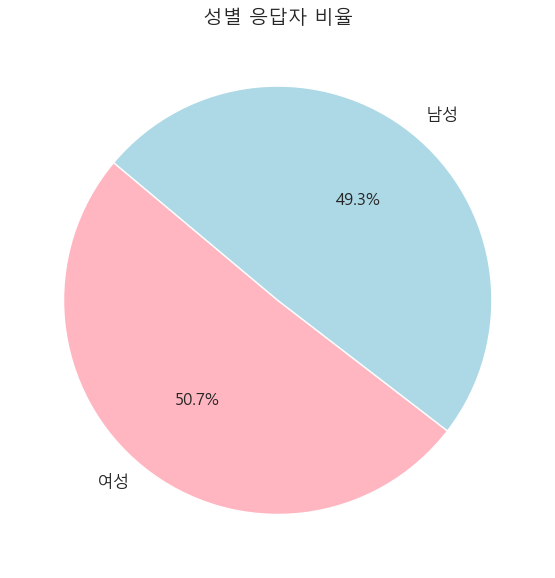

In [11]:
# 성별 응답자 수 (중복 제거 후 집계)
gender_counts = df_common.drop_duplicates(subset='user_id')["gender"].value_counts()

# 파스텔톤 색상 지정
colors = ['#FFB6C1', '#ADD8E6']  # 연핑크, 연하늘 (여성, 남성 순)

# 파이 차트 그리기
plt.figure(figsize=(6, 6))
plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 12}
)
plt.title("성별 응답자 비율", fontsize=14)
plt.tight_layout()
plt.show()


In [12]:
# 성별 응답자 수
df_2022.drop_duplicates(subset='user_id')["gender"].value_counts()

gender
여성    2285
남성    2251
Name: count, dtype: int64

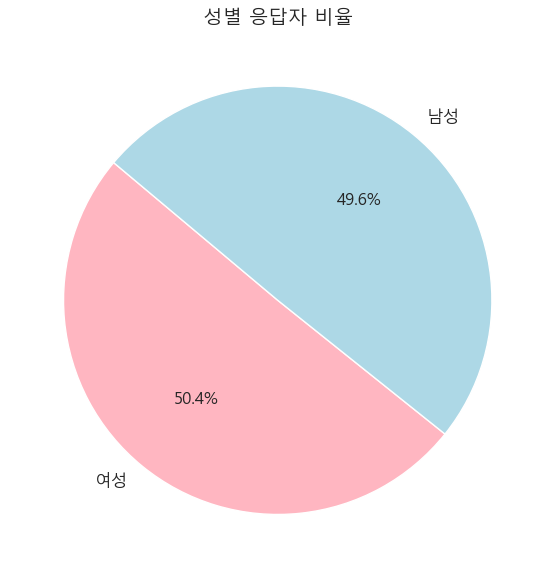

In [13]:
# 성별 응답자 수 (중복 제거 후 집계)
gender_counts = df_2022.drop_duplicates(subset='user_id')["gender"].value_counts()

# 파스텔톤 색상 지정
colors = ['#FFB6C1', '#ADD8E6']  # 연핑크, 연하늘 (여성, 남성 순)

# 파이 차트 그리기
plt.figure(figsize=(6, 6))
plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 12}
)
plt.title("성별 응답자 비율", fontsize=14)
plt.tight_layout()
plt.show()

In [14]:
# 성별 응답자 수
df_2023.drop_duplicates(subset='user_id')["gender"].value_counts()

gender
여성    3219
남성    3107
Name: count, dtype: int64

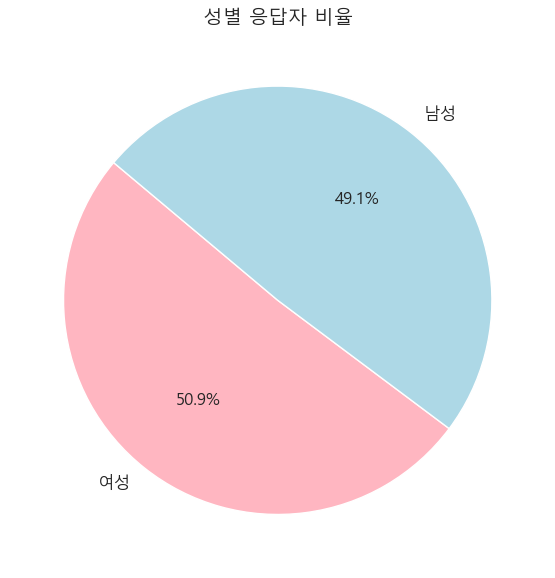

In [15]:
# 성별 응답자 수 (중복 제거 후 집계)
gender_counts = df_2023.drop_duplicates(subset='user_id')["gender"].value_counts()

# 파스텔톤 색상 지정
colors = ['#FFB6C1', '#ADD8E6']  # 연핑크, 연하늘 (여성, 남성 순)

# 파이 차트 그리기
plt.figure(figsize=(6, 6))
plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 12}
)
plt.title("성별 응답자 비율", fontsize=14)
plt.tight_layout()
plt.show()

In [16]:
# 연령대 응답자 수
df_common.drop_duplicates(subset='user_id')["age"].value_counts().sort_index()

age
15-19세     801
20-24세    1785
25-29세    1847
30-34세    1772
35-39세    1393
40-44세    1302
45-49세    1036
50-54세     926
Name: count, dtype: int64

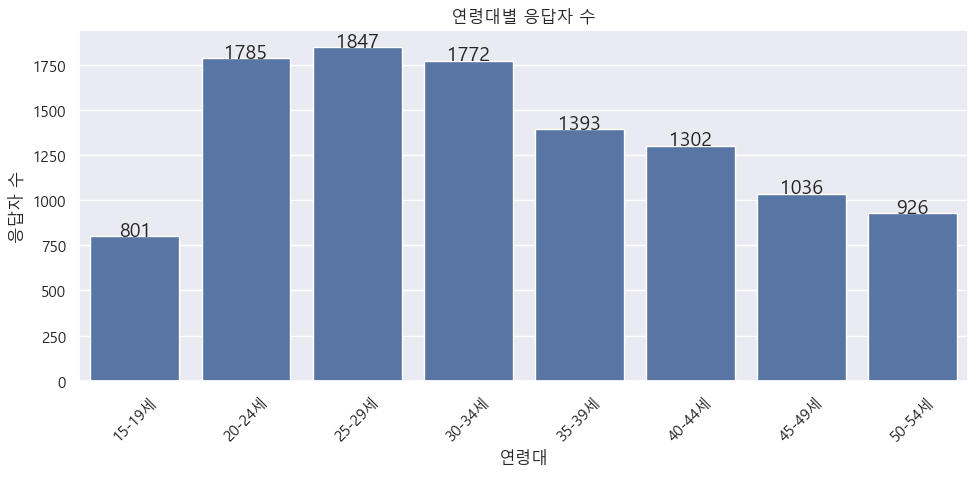

In [17]:
# 연령대 응답자 수
age_counts = df_common.drop_duplicates(subset='user_id')["age"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(x=age_counts.index, y=age_counts.values)
plt.title("연령대별 응답자 수")
plt.xlabel("연령대")
plt.ylabel("응답자 수")
plt.xticks(rotation=45)
for i, v in enumerate(age_counts.values):
    plt.text(i, v + 1, str(v), ha='center')
plt.tight_layout()
plt.show()

In [18]:
# 성별과 연령대별 응답자 수 교차표
pd.crosstab(
    df_common.drop_duplicates(subset='user_id')["age"],
    df_common.drop_duplicates(subset='user_id')["gender"]
).sort_index()

gender,남성,여성
age,,
15-19세,407,394
20-24세,825,960
25-29세,823,1024
30-34세,841,931
35-39세,692,701
40-44세,700,602
45-49세,557,479
50-54세,513,413


In [19]:
# 국가 응답자 수
df_common.drop_duplicates(subset='user_id')["nation"].value_counts().sort_index()

nation
대만       1009
멕시코      1505
미국       2015
브라질      1505
영국       1515
인도네시아    1512
일본       1801
Name: count, dtype: int64

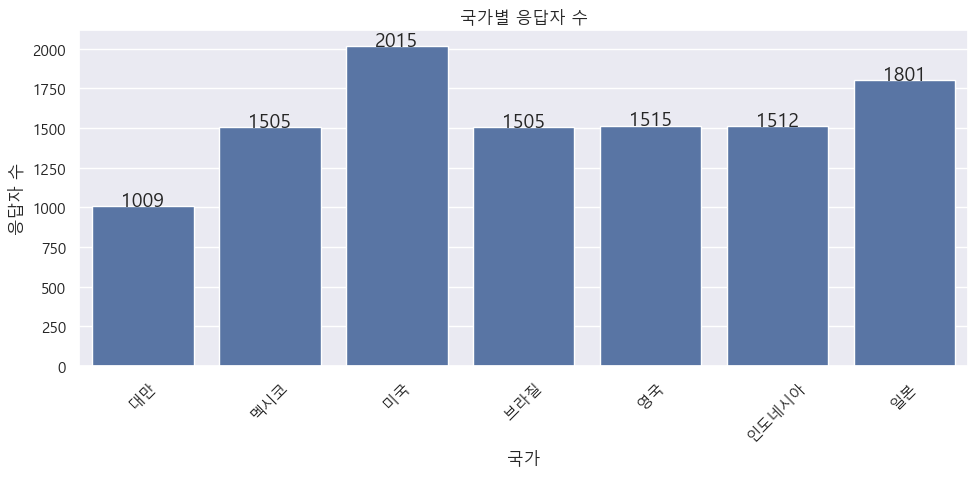

In [20]:
# 국가 응답자 수
nation_counts = df_common.drop_duplicates(subset='user_id')["nation"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(x=nation_counts.index, y=nation_counts.values)
plt.title("국가별 응답자 수")
plt.xlabel("국가")
plt.ylabel("응답자 수")
plt.xticks(rotation=45)
for i, v in enumerate(nation_counts.values):
    plt.text(i, v + 1, str(v), ha='center')
plt.tight_layout()
plt.show()

### 전체 콘텐츠 유형별 이용 현황

In [21]:
# 콘텐츠 컬럼
viewed_cols = [
    "viewed_series", "viewed_movie", "viewed_variety", "viewed_music",
    "viewed_animation", "viewed_webtoon", "viewed_webnovel", "viewed_game"
]

# 시각화용 한글 레이블
col_name_map = {
    "viewed_series": "드라마/시리즈물",
    "viewed_movie": "영화",
    "viewed_variety": "예능/버라이어티",
    "viewed_music": "음악",
    "viewed_animation": "애니메이션",
    "viewed_webtoon": "웹툰",
    "viewed_webnovel": "웹소설",
    "viewed_game": "게임/e-스포츠"
}
# 그룹 컬럼명 한글 변환
group_col_labels = {
    "nation": "국가",
    "gender": "성별",
    "age": "연령"
}

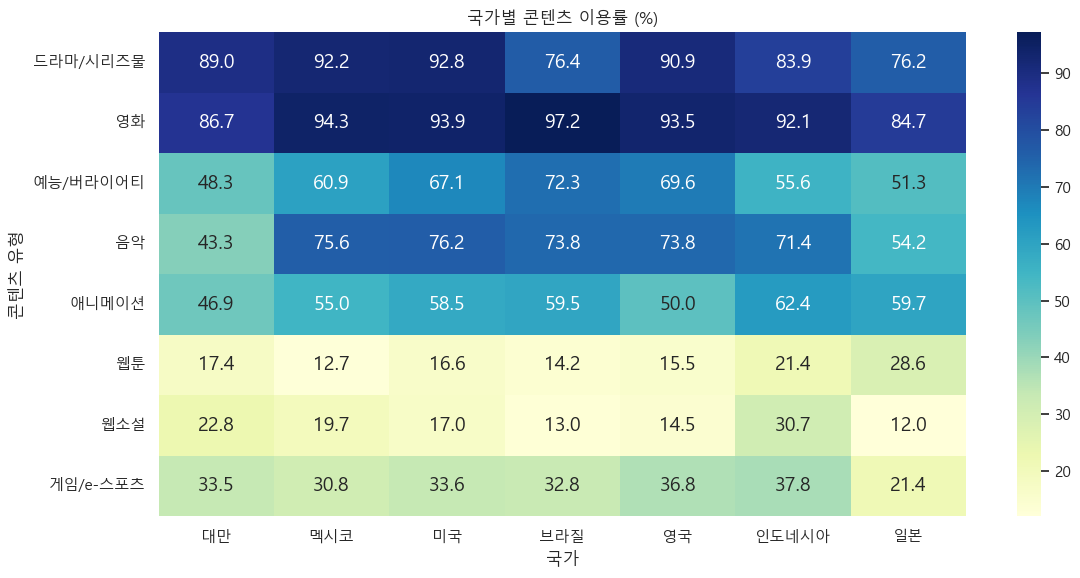

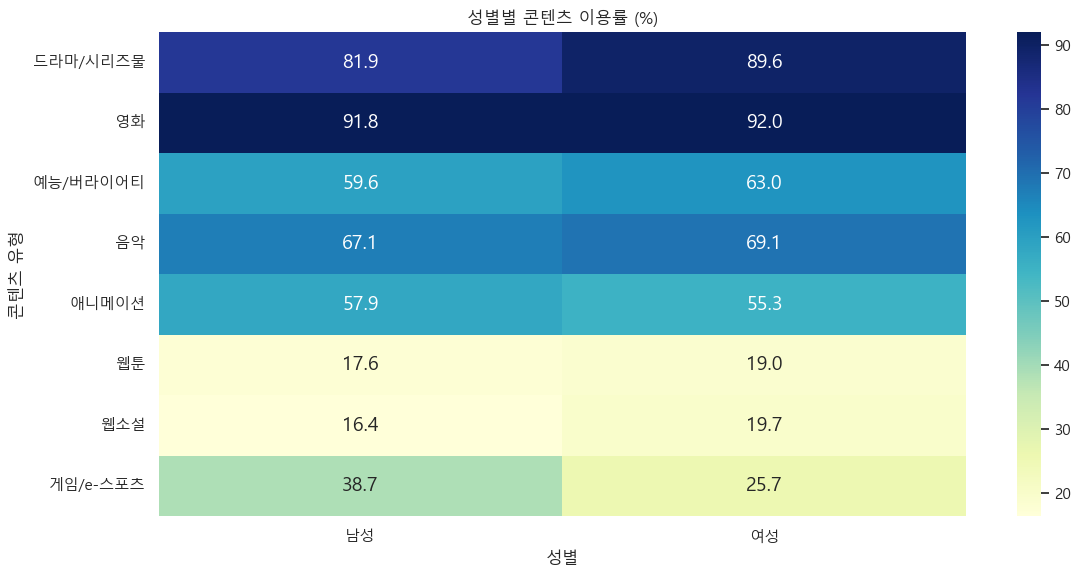

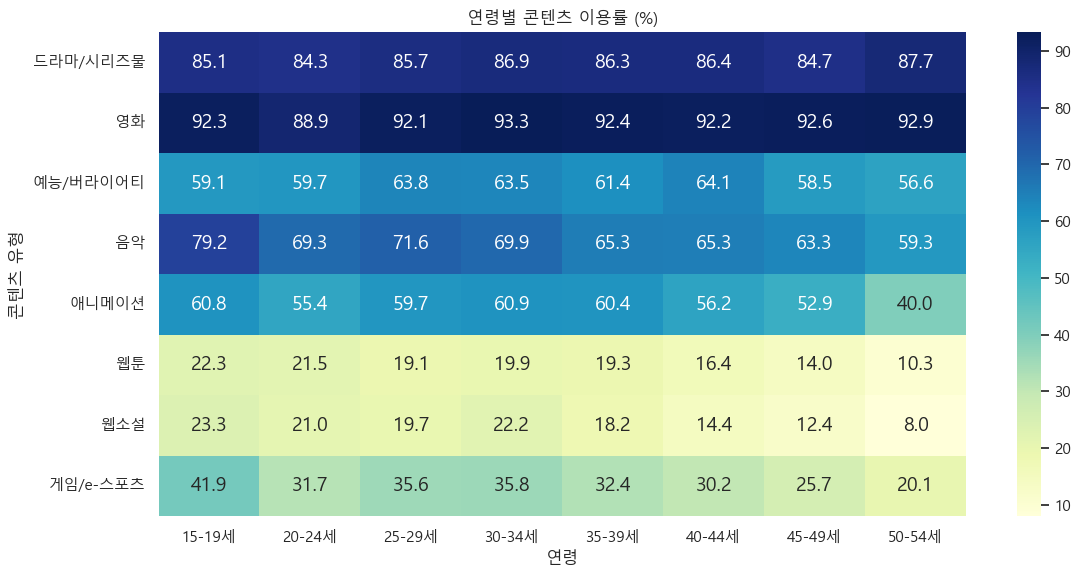

In [22]:
# 히트맵 함수
def plot_heatmap_with_korean_labels(df, group_col):
    grouped = df.groupby(group_col)[viewed_cols].mean().T * 100
    grouped.index = [col_name_map.get(col, col) for col in grouped.index]
    plt.figure(figsize=(12, 6))
    sns.heatmap(grouped, annot=True, fmt=".1f", cmap="YlGnBu")
    plt.title(f"{group_col_labels.get(group_col, group_col)}별 콘텐츠 이용률 (%)")
    plt.xlabel(group_col_labels.get(group_col, group_col))
    plt.ylabel("콘텐츠 유형")
    plt.tight_layout()
    plt.show()

# 실행 예시
plot_heatmap_with_korean_labels(df_common, "nation")
plot_heatmap_with_korean_labels(df_common, "gender")
plot_heatmap_with_korean_labels(df_common, "age")

In [23]:
def get_viewed_ratio_table(df, group_col):
    """
    group_col 별 콘텐츠 이용률(%) 테이블을 반환
    """
    grouped = df.groupby(group_col)[viewed_cols].mean().T * 100
    grouped.index = [col_name_map.get(col, col) for col in grouped.index]
    grouped.columns.name = group_col_labels.get(group_col, group_col)
    return grouped.round(1)  # 소수점 첫째자리까지 반올림
# 결과 테이블
table_by_nation = get_viewed_ratio_table(df_common, "nation")
table_by_gender = get_viewed_ratio_table(df_common, "gender")
table_by_age = get_viewed_ratio_table(df_common, "age")

# 출력
import pandas as pd
from IPython.display import display

print("🌍 국가별 콘텐츠 이용률 (%)")
display(table_by_nation)

print("\n👤 성별 콘텐츠 이용률 (%)")
display(table_by_gender)

print("\n🎂 연령대별 콘텐츠 이용률 (%)")
display(table_by_age)


🌍 국가별 콘텐츠 이용률 (%)


국가,대만,멕시코,미국,브라질,영국,인도네시아,일본
드라마/시리즈물,89.0,92.2,92.8,76.4,90.9,83.9,76.2
영화,86.7,94.3,93.9,97.2,93.5,92.1,84.7
예능/버라이어티,48.3,60.9,67.1,72.3,69.6,55.6,51.3
음악,43.3,75.6,76.2,73.8,73.8,71.4,54.2
애니메이션,46.9,55.0,58.5,59.5,50.0,62.4,59.7
웹툰,17.4,12.7,16.6,14.2,15.5,21.4,28.6
웹소설,22.8,19.7,17.0,13.0,14.5,30.7,12.0
게임/e-스포츠,33.5,30.8,33.6,32.8,36.8,37.8,21.4



👤 성별 콘텐츠 이용률 (%)


성별,남성,여성
드라마/시리즈물,81.9,89.6
영화,91.8,92.0
예능/버라이어티,59.6,63.0
음악,67.1,69.1
애니메이션,57.9,55.3
웹툰,17.6,19.0
웹소설,16.4,19.7
게임/e-스포츠,38.7,25.7



🎂 연령대별 콘텐츠 이용률 (%)


연령,15-19세,20-24세,25-29세,30-34세,35-39세,40-44세,45-49세,50-54세
드라마/시리즈물,85.1,84.3,85.7,86.9,86.3,86.4,84.7,87.7
영화,92.3,88.9,92.1,93.3,92.4,92.2,92.6,92.9
예능/버라이어티,59.1,59.7,63.8,63.5,61.4,64.1,58.5,56.6
음악,79.2,69.3,71.6,69.9,65.3,65.3,63.3,59.3
애니메이션,60.8,55.4,59.7,60.9,60.4,56.2,52.9,40.0
웹툰,22.3,21.5,19.1,19.9,19.3,16.4,14.0,10.3
웹소설,23.3,21.0,19.7,22.2,18.2,14.4,12.4,8.0
게임/e-스포츠,41.9,31.7,35.6,35.8,32.4,30.2,25.7,20.1


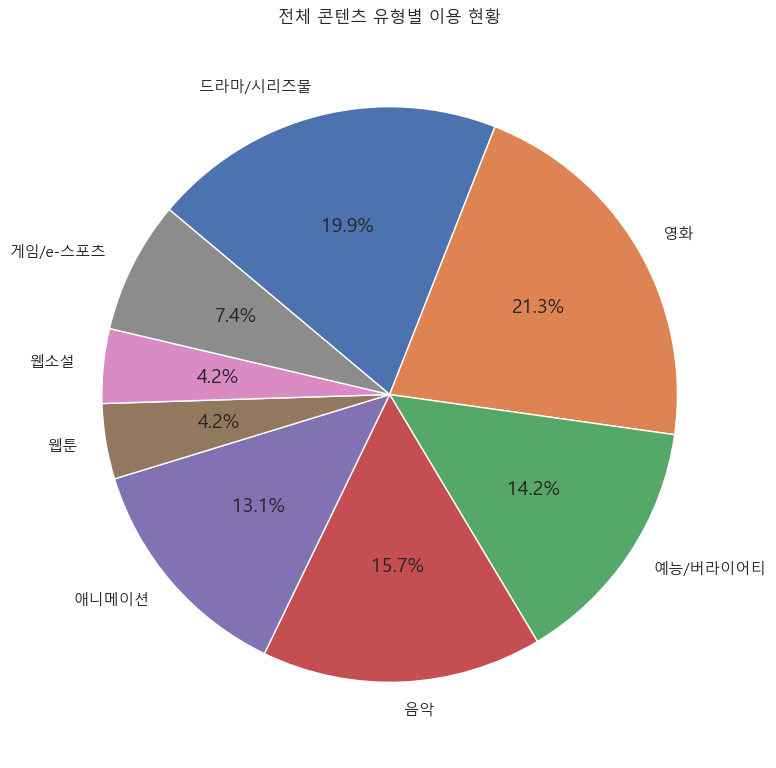

In [24]:
# 전체 응답자 기준 콘텐츠 이용률 평균 계산
content_mean = df_common[viewed_cols].mean() * 100

# 그래프용 라벨
labels = [col_name_map[col] for col in content_mean.index]
sizes = content_mean.values

# 원형 차트 시각화
plt.figure(figsize=(8, 8))
plt.pie(sizes, labels=labels, autopct="%.1f%%", startangle=140, counterclock=False)
plt.title("전체 콘텐츠 유형별 이용 현황")
plt.axis("equal") 
plt.tight_layout()
plt.show()

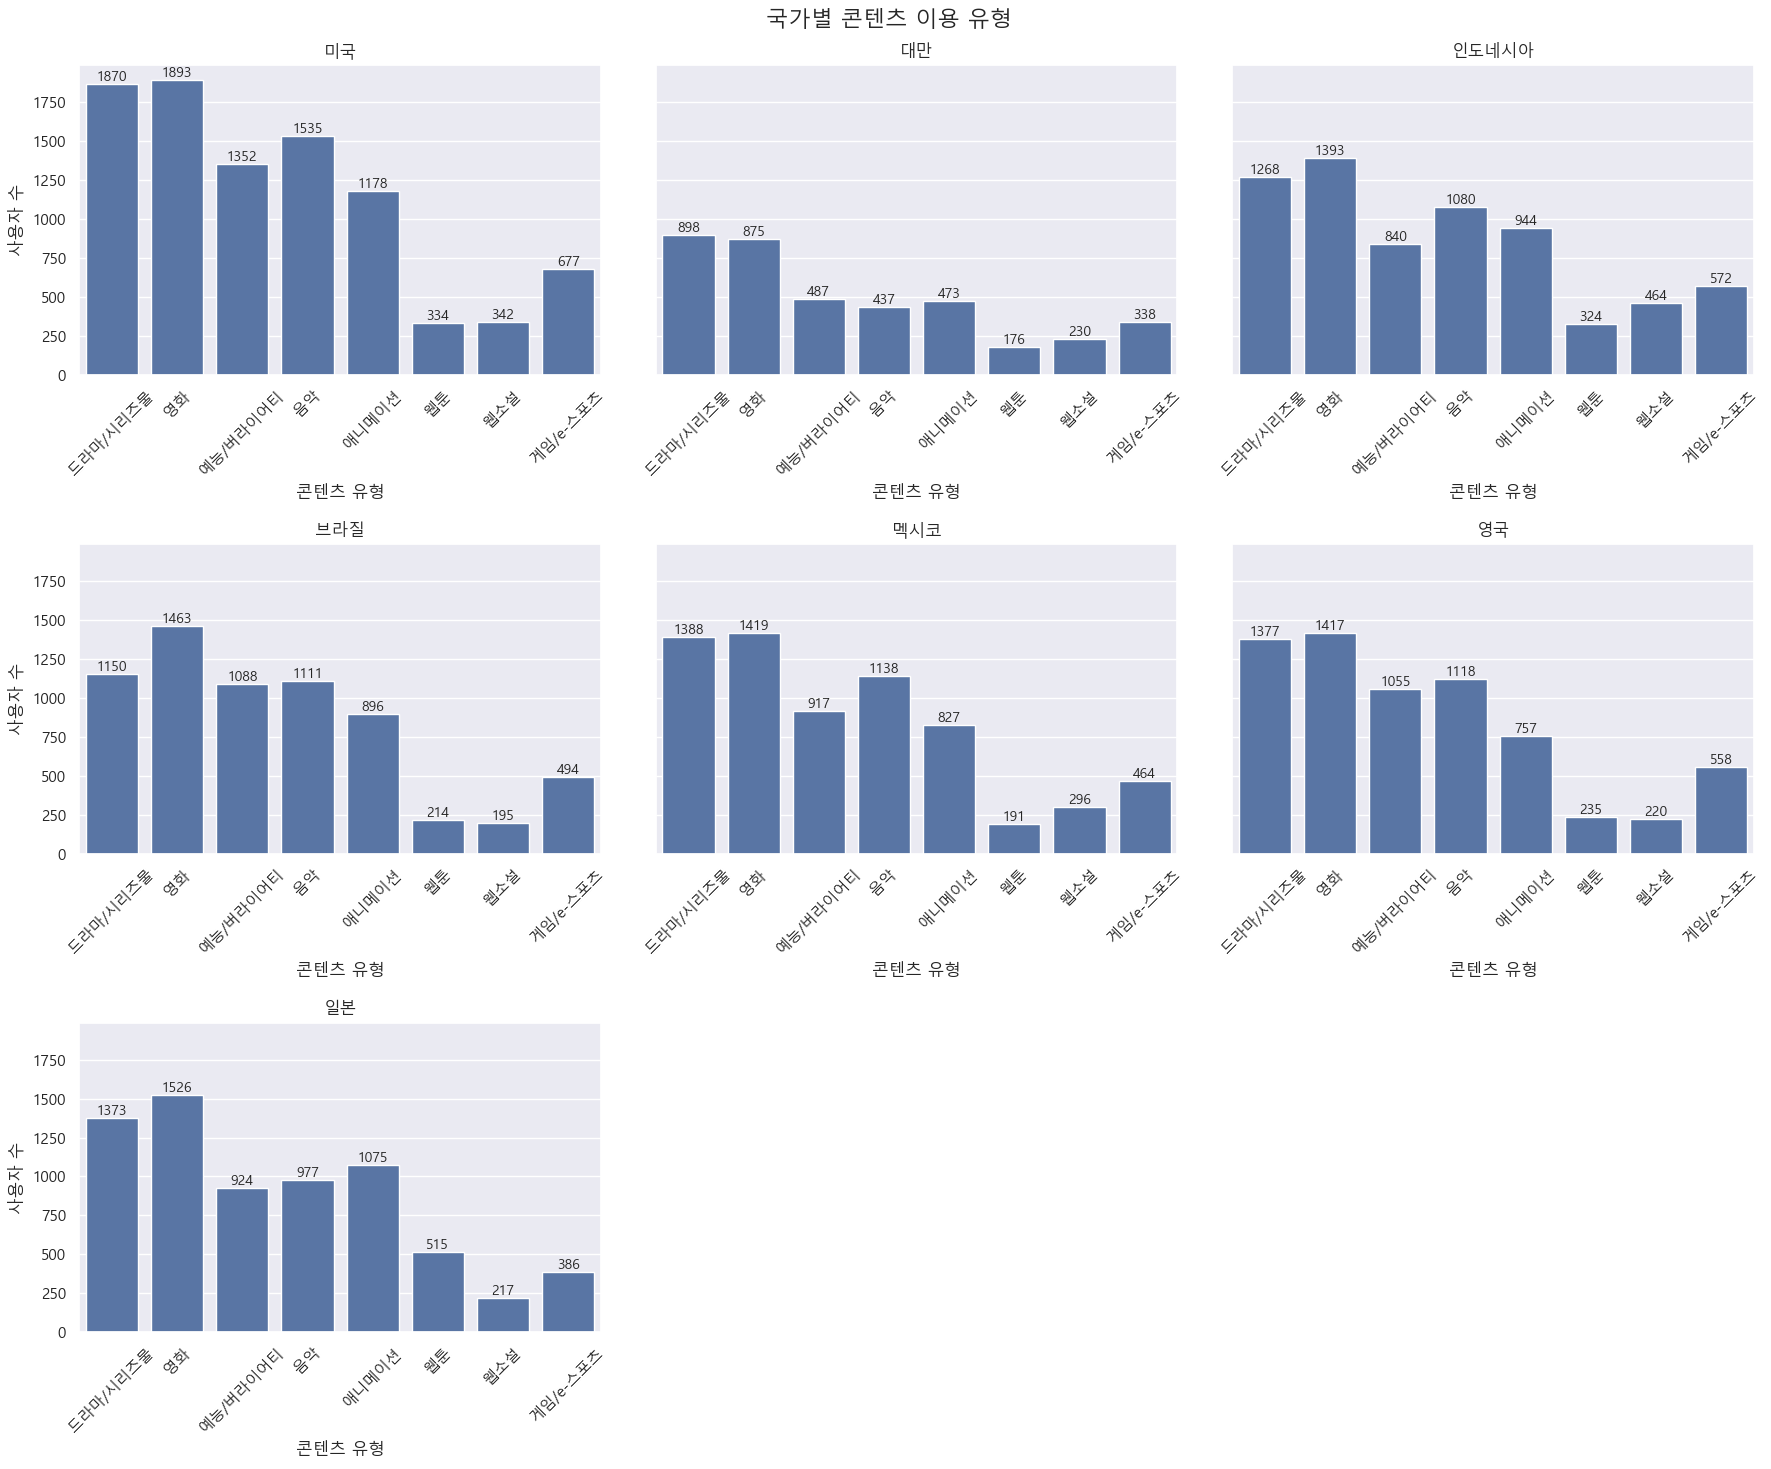

In [25]:
# 데이터 long-format으로 변환
df_melted = df_common.melt(
    id_vars=["nation", "gender", "age"],
    value_vars=viewed_cols,
    var_name="콘텐츠코드",
    value_name="이용여부"
)

# 컬럼 이름 매핑 (그래프용)
df_melted["콘텐츠"] = df_melted["콘텐츠코드"].map(col_name_map)


# 콘텐츠 이용한 사용자만 필터링
df_used = df_melted[df_melted["이용여부"] == 1]

# 국가 목록
nations = df_used["nation"].unique()

# subplot 설정
n_cols = 3
n_rows = (len(nations) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*6, n_rows*5), sharey=True)
axes = axes.flatten()

# 그래프 그리기
for i, nation in enumerate(nations):
    ax = axes[i]
    subset = df_used[df_used["nation"] == nation]
    sns.countplot(data=subset, x="콘텐츠", order=list(col_name_map.values()), ax=ax)
    ax.set_title(f"{nation}")
    ax.set_xlabel("콘텐츠 유형")
    ax.set_ylabel("사용자 수")
    ax.tick_params(axis='x', rotation=45)

    # 막대 위에 수치 표시
    for container in ax.containers:
        ax.bar_label(container, label_type='edge', fontsize=10)

# 나머지 빈 subplot 제거
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("국가별 콘텐츠 이용 유형", fontsize=16)
plt.tight_layout()
plt.show()

In [26]:
# 콘텐츠 이름 매핑 적용된 상태에서 콘텐츠 이용자만 추출
df_used = df_common.melt(
    id_vars=["nation"],
    value_vars=viewed_cols,
    var_name="콘텐츠코드",
    value_name="이용여부"
)
df_used["콘텐츠"] = df_used["콘텐츠코드"].map(col_name_map)
df_used = df_used[df_used["이용여부"] == 1]

# 국가별 콘텐츠 이용자 수 집계
df_usage_table = (
    df_used.groupby(["nation", "콘텐츠"])
    .size()
    .unstack(fill_value=0)
    .T  # 보기 좋게 전치
)

# 정렬 (원하는 콘텐츠 순서 유지)
df_usage_table = df_usage_table.loc[list(col_name_map.values())]

# 출력
import pandas as pd
from IPython.display import display

print("🌍 국가별 콘텐츠 이용자 수")
display(df_usage_table)

🌍 국가별 콘텐츠 이용자 수


nation,대만,멕시코,미국,브라질,영국,인도네시아,일본
콘텐츠,,,,,,,
드라마/시리즈물,898,1388,1870,1150,1377,1268,1373
영화,875,1419,1893,1463,1417,1393,1526
예능/버라이어티,487,917,1352,1088,1055,840,924
음악,437,1138,1535,1111,1118,1080,977
애니메이션,473,827,1178,896,757,944,1075
웹툰,176,191,334,214,235,324,515
웹소설,230,296,342,195,220,464,217
게임/e-스포츠,338,464,677,494,558,572,386


In [27]:
# # 연령대 목록 (정렬 순서 고정)
# age_order = [
#     "15-19세", "20-24세", "25-29세", "30-34세",
#     "35-39세", "40-44세", "45-49세", "50-54세"
# ]

# df_used["age"] = df_used["age"].str.strip() 
# df_used["age"] = pd.Categorical(df_used["age"], categories=age_order, ordered=True)
# ages = age_order  # 순서 고정

# # subplot 설정
# n_cols = 3
# n_rows = (len(ages) + n_cols - 1) // n_cols
# fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*6, n_rows*5), sharey=True)
# axes = axes.flatten()


# # 연령대별 subplot 그리기
# for i, age in enumerate(ages):
#     ax = axes[i]
#     subset = df_used[df_used["age"] == age]
#     sns.countplot(data=subset, x="콘텐츠", order=list(col_name_map.values()), ax=ax)
#     ax.set_title(f"{age}")
#     ax.set_xlabel("콘텐츠 유형")
#     ax.set_ylabel("사용자 수")
#     ax.tick_params(axis='x', rotation=45)
#     for container in ax.containers:
#         ax.bar_label(container, label_type='edge', fontsize=10)

# # 남은 subplot 제거
# for j in range(i+1, len(axes)):
#     fig.delaxes(axes[j])

# fig.suptitle("연령대별 콘텐츠 이용 유형", fontsize=16)
# plt.tight_layout()
# plt.show()

In [28]:
# # 콘텐츠 이용한 사람만 필터링된 df_used 사용
# genders = df_used["gender"].dropna().unique()

# # subplot 설정
# n_cols = 2
# n_rows = (len(genders) + n_cols - 1) // n_cols
# fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 5), sharey=True)
# axes = axes.flatten()

# # 성별별 subplot 그리기
# for i, gender in enumerate(genders):
#     ax = axes[i]
#     subset = df_used[df_used["gender"] == gender]
#     sns.countplot(data=subset, x="콘텐츠", order=list(col_name_map.values()), ax=ax)
#     ax.set_title(f"{gender}별 콘텐츠 이용")
#     ax.set_xlabel("콘텐츠 유형")
#     ax.set_ylabel("사용자 수")
#     ax.tick_params(axis="x", rotation=45)

#     # 막대 위에 수치 표시
#     for container in ax.containers:
#         ax.bar_label(container, label_type="edge", fontsize=10)

# # 남은 subplot 제거
# for j in range(i + 1, len(axes)):
#     fig.delaxes(axes[j])

# fig.suptitle("성별 콘텐츠 이용 유형 비교", fontsize=16)
# plt.tight_layout()
# plt.show()

### OTT 콘텐츠 이용 빈도 (드라마/시리즈물)

In [29]:
freq_order = [
    '매일',
    '1주일에 5~6일',
    '1주일에 3~4일',
    '1주일에 1~2일',
    '한 달에 1~3일',
    '2~3달에 1~2일 이하',
    '이용안함'
]

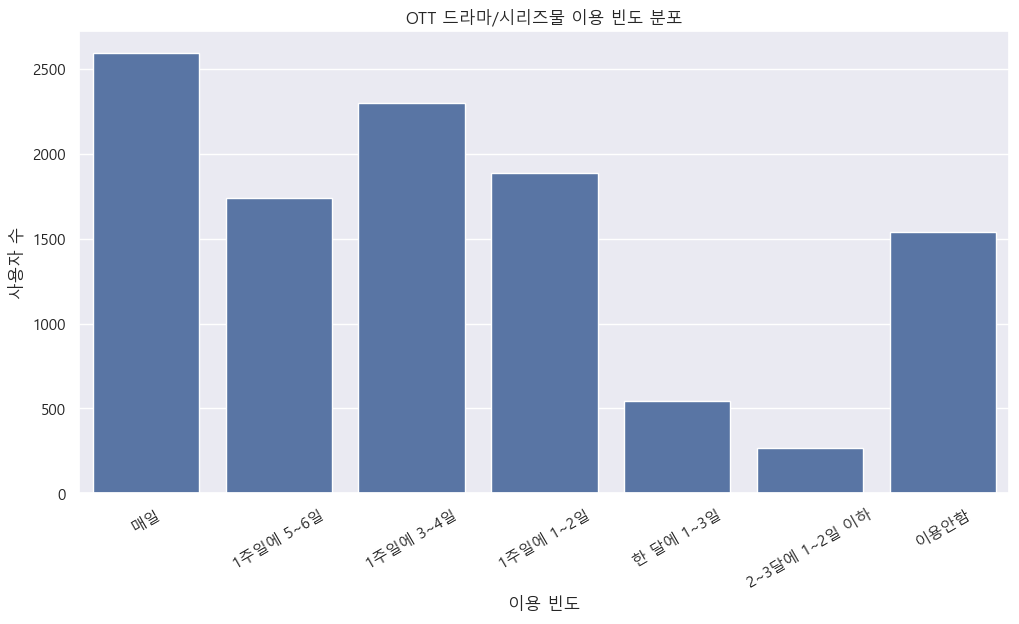

In [30]:
df_common.loc[:, 'frequency_series'] = pd.Categorical(
    df_common['frequency_series'],
    categories=freq_order,
    ordered=True
)

sns.countplot(data=df_common, x='frequency_series', order=freq_order)
plt.title("OTT 드라마/시리즈물 이용 빈도 분포")
plt.xlabel("이용 빈도")
plt.ylabel("사용자 수")
plt.xticks(rotation=30)
plt.show()

In [31]:
df_common['frequency_series'].value_counts()

frequency_series
매일               2589
1주일에 3~4일        2299
1주일에 1~2일        1887
1주일에 5~6일        1740
이용안함             1538
한 달에 1~3일         544
2~3달에 1~2일 이하     265
Name: count, dtype: int64

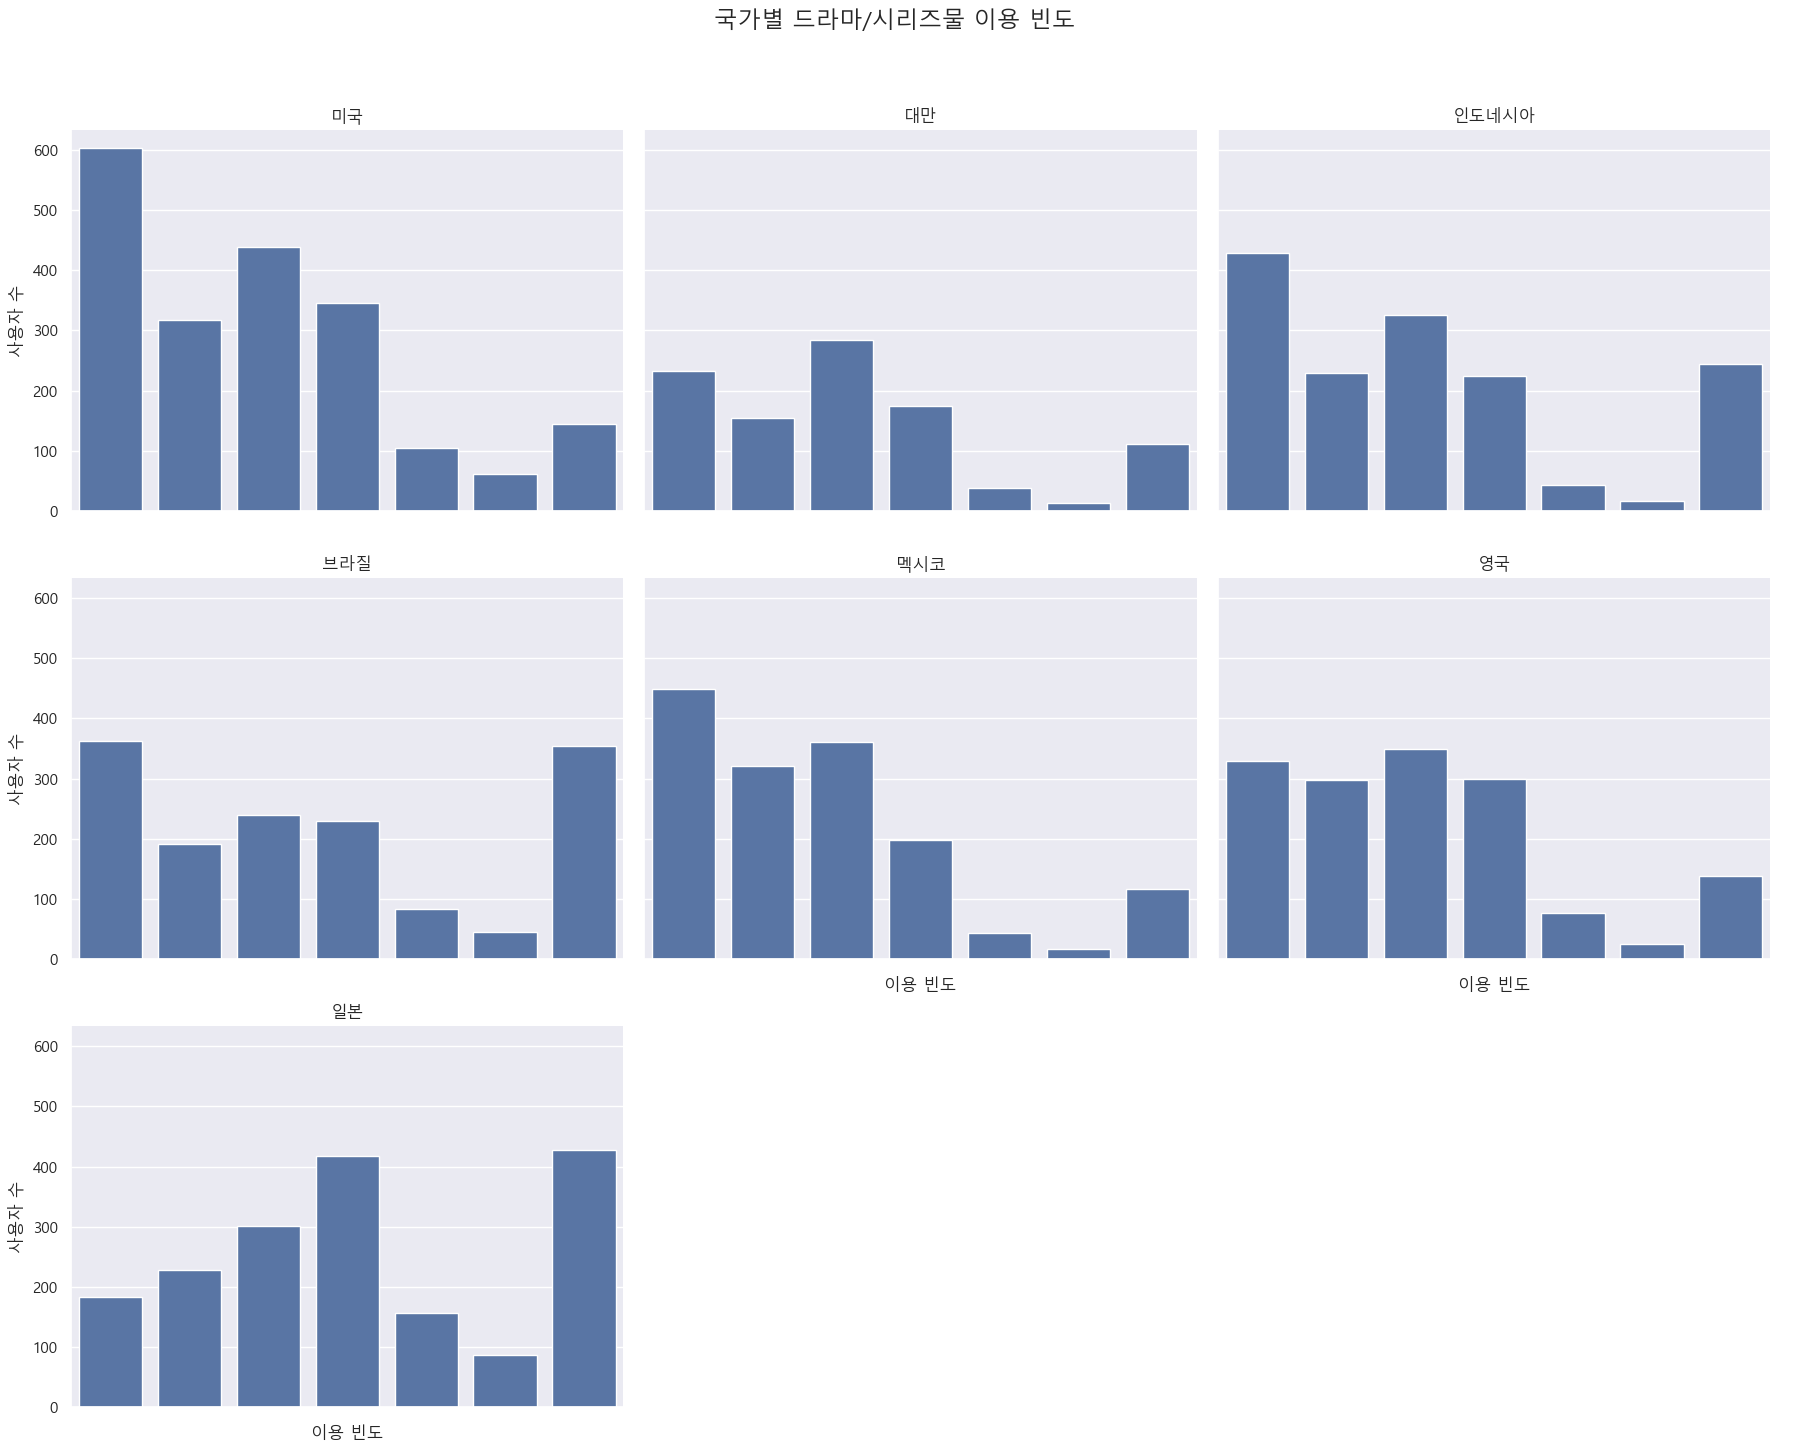

In [32]:
g = sns.catplot(
    data=df_common,
    x="frequency_series",
    kind="count",
    col="nation",
    order=freq_order,
    col_wrap=3,      # 열 개수 조정 (나라 수 많으면 3~4 권장)
    height=5,
    aspect=1.2
)
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45)
g.set_axis_labels("이용 빈도", "사용자 수")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("국가별 드라마/시리즈물 이용 빈도")
plt.show()

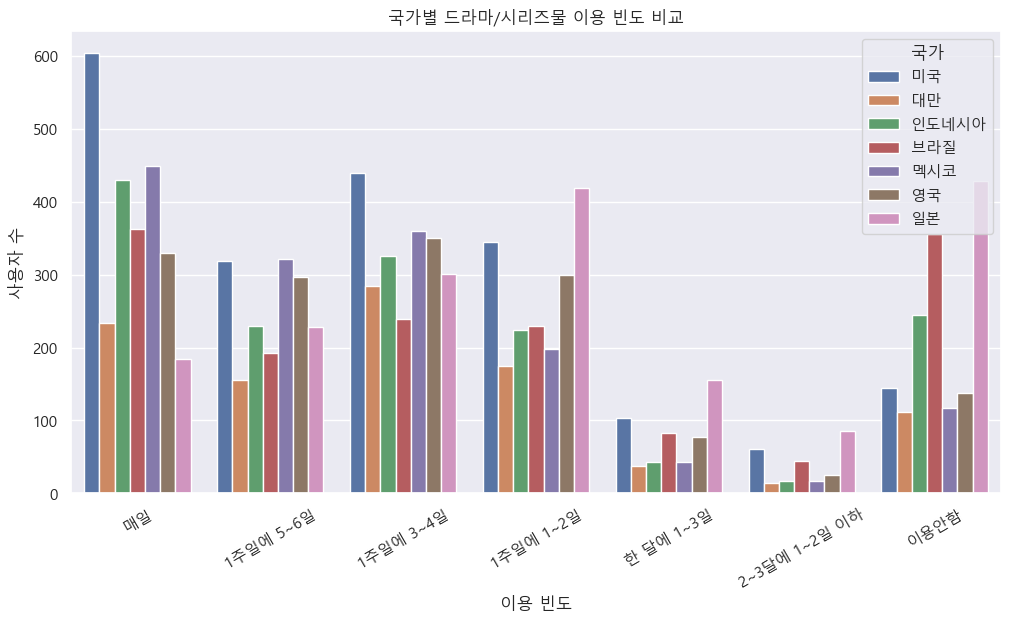

In [33]:
sns.countplot(
    data=df_common,
    x='frequency_series',
    hue='nation',
    order=freq_order
)
plt.title("국가별 드라마/시리즈물 이용 빈도 비교")
plt.xlabel("이용 빈도")
plt.ylabel("사용자 수")
plt.xticks(rotation=30)
plt.legend(title='국가')
plt.show()

In [34]:
df_common.groupby('nation')['frequency_series'].value_counts()

nation  frequency_series
대만      1주일에 3~4일           284
        매일                  233
        1주일에 1~2일           174
        1주일에 5~6일           155
        이용안함                111
        한 달에 1~3일            38
        2~3달에 1~2일 이하        14
멕시코     매일                  449
        1주일에 3~4일           360
        1주일에 5~6일           321
        1주일에 1~2일           198
        이용안함                117
        한 달에 1~3일            43
        2~3달에 1~2일 이하        17
미국      매일                  603
        1주일에 3~4일           439
        1주일에 1~2일           345
        1주일에 5~6일           318
        이용안함                145
        한 달에 1~3일           104
        2~3달에 1~2일 이하        61
브라질     매일                  362
        이용안함                355
        1주일에 3~4일           239
        1주일에 1~2일           229
        1주일에 5~6일           192
        한 달에 1~3일            83
        2~3달에 1~2일 이하        45
영국      1주일에 3~4일           350
        매일                  329
        1주일에 1~

C:\Users\User\AppData\Local\Temp\ipykernel_9840\3951659426.py:5: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g_gender = sns.catplot(


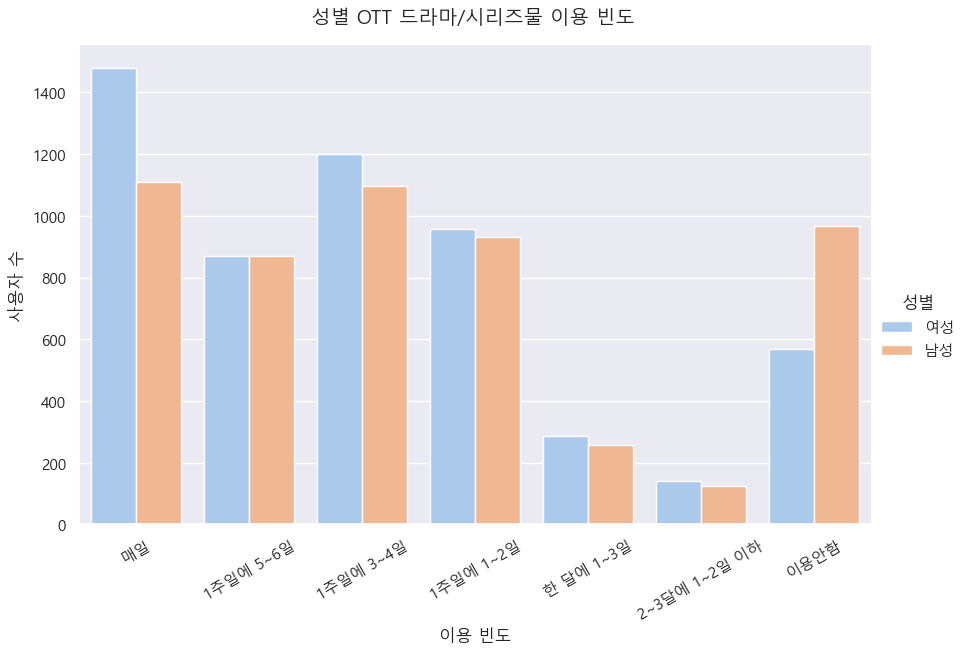

In [35]:
# 파스텔톤 색상 팔레트 설정
pastel_palette = sns.color_palette("pastel")

# 성별별 분포
g_gender = sns.catplot(
    data=df_common,
    x="frequency_series",
    kind="count",
    hue="gender",
    order=freq_order,
    height=6,
    aspect=1.5,
    palette=pastel_palette
)

# 축 및 제목 설정
g_gender.set_axis_labels("이용 빈도", "사용자 수")
g_gender.set_xticklabels(rotation=30)
g_gender._legend.set_title("성별")

# 제목 설정 (위치 조정 포함)
g_gender.fig.suptitle("성별 OTT 드라마/시리즈물 이용 빈도", fontsize=14)
g_gender.fig.subplots_adjust(top=0.92)  # ← 제목과 그래프 간 간격 조절

plt.show()


C:\Users\User\AppData\Local\Temp\ipykernel_9840\331795317.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g_age = sns.catplot(
C:\Users\User\AppData\Local\Temp\ipykernel_9840\331795317.py:2: UserWarning: The palette list has more values (10) than needed (7), which may not be intended.
  g_age = sns.catplot(


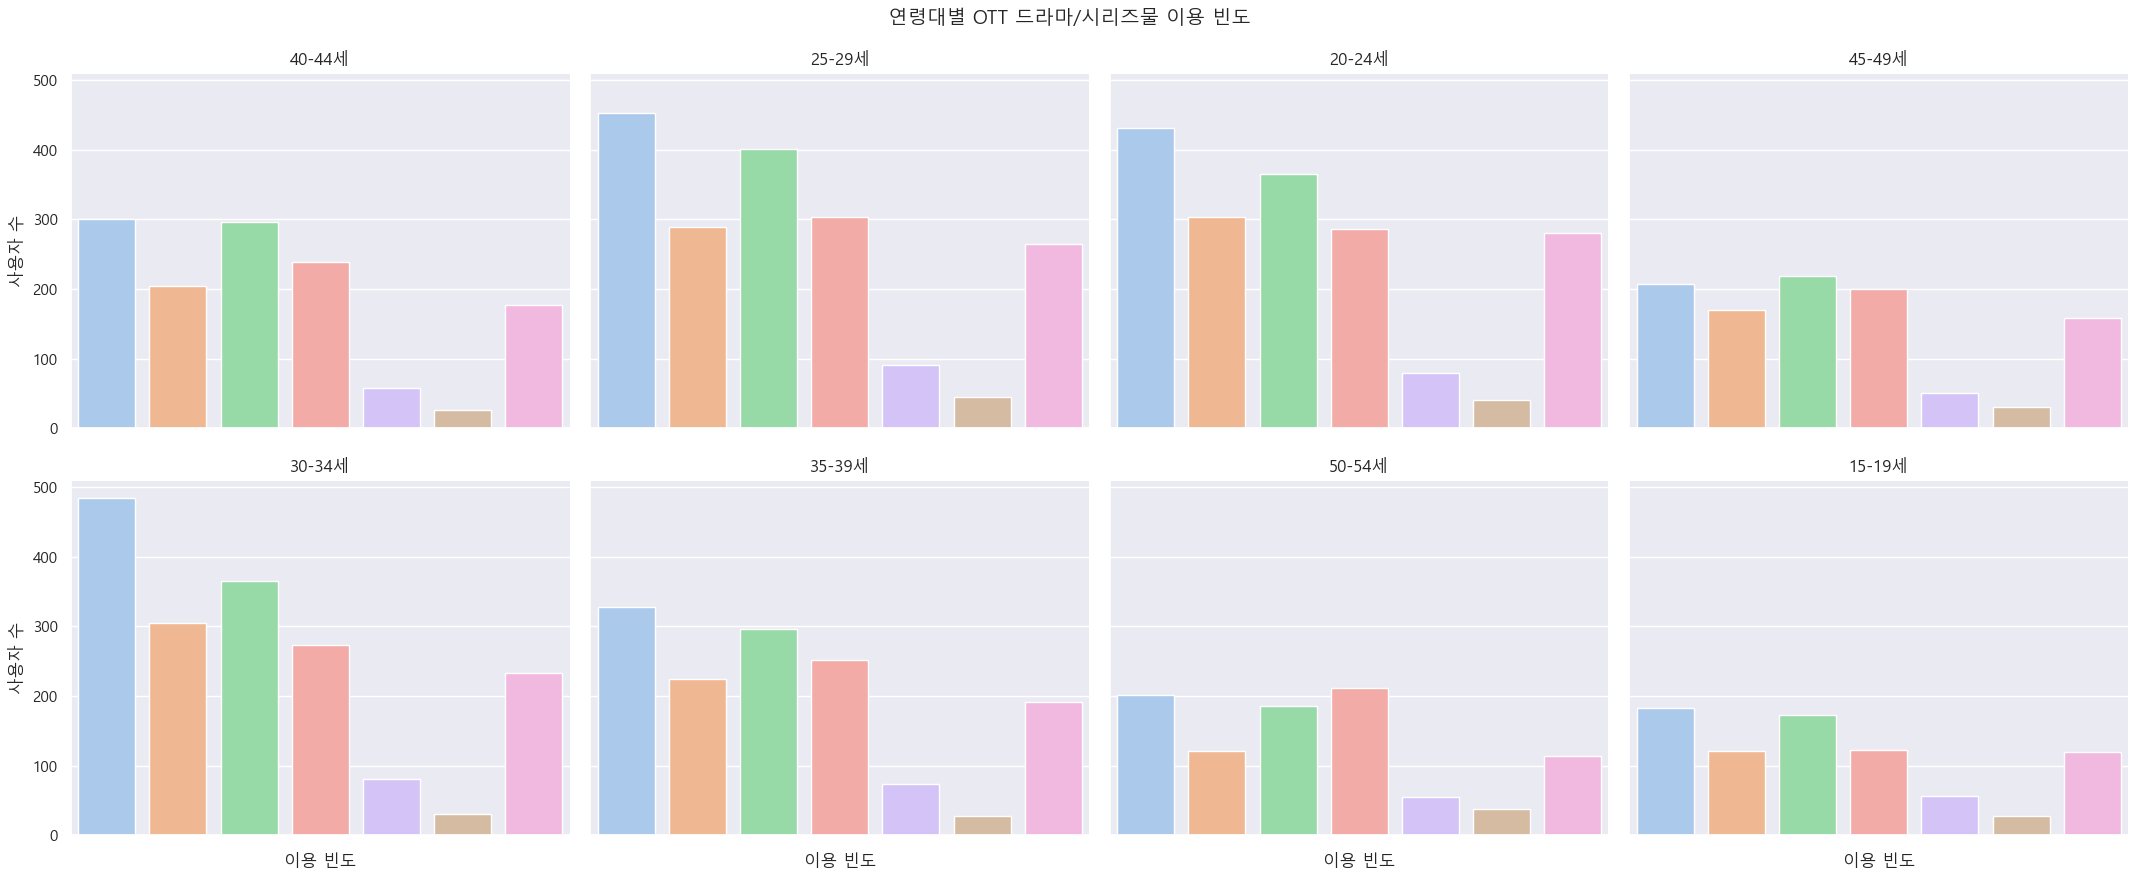

In [36]:
# 연령대별 subplot
g_age = sns.catplot(
    data=df_common,
    x="frequency_series",
    kind="count",
    col="age",
    order=freq_order,
    col_wrap=4,
    height=4.5,
    aspect=1.2,
    palette=pastel_palette
)

g_age.set_titles("{col_name}")
g_age.set_xticklabels(rotation=45)
g_age.set_axis_labels("이용 빈도", "사용자 수")
g_age.fig.subplots_adjust(top=0.9)
g_age.fig.suptitle("연령대별 OTT 드라마/시리즈물 이용 빈도", fontsize=14)
plt.tight_layout()
plt.show()

### OTT 콘텐츠 이용 빈도 (영화)

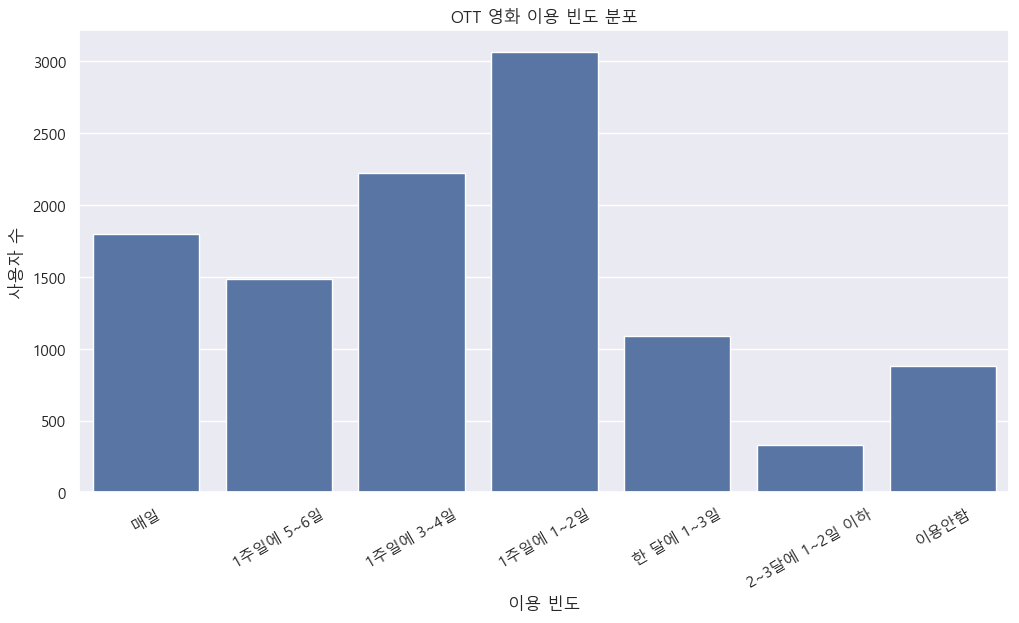

In [37]:
df_common.loc[:, 'frequency_movie'] = pd.Categorical(
    df_common['frequency_movie'],
    categories=freq_order,
    ordered=True
)

sns.countplot(data=df_common, x='frequency_movie', order=freq_order)
plt.title("OTT 영화 이용 빈도 분포")
plt.xlabel("이용 빈도")
plt.ylabel("사용자 수")
plt.xticks(rotation=30)
plt.show()

In [38]:
df_common['frequency_movie'].value_counts()

frequency_movie
1주일에 1~2일        3060
1주일에 3~4일        2224
매일               1798
1주일에 5~6일        1483
한 달에 1~3일        1090
이용안함              876
2~3달에 1~2일 이하     331
Name: count, dtype: int64

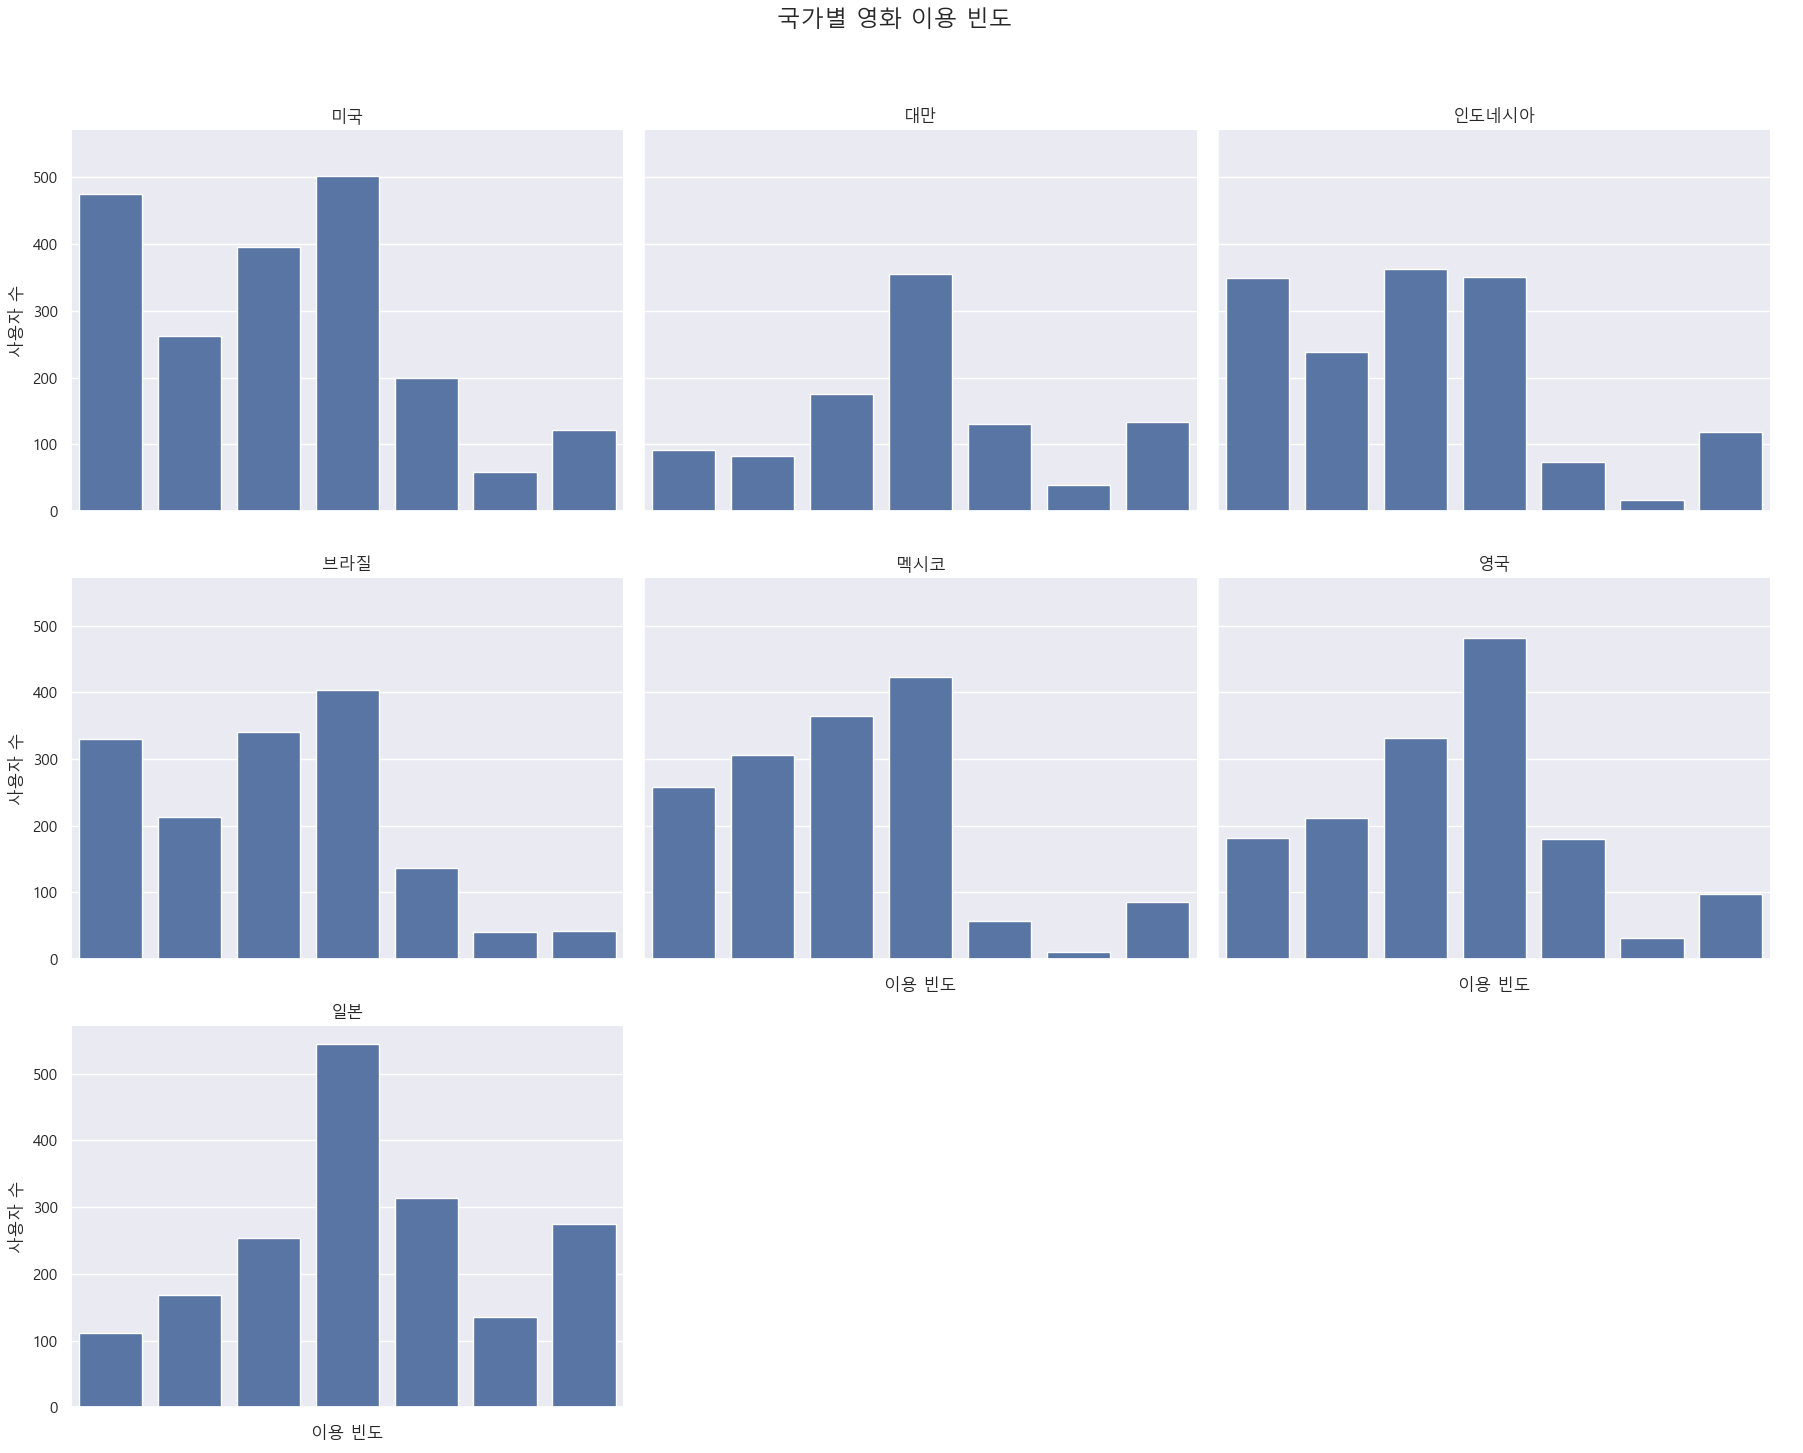

In [39]:
g = sns.catplot(
    data=df_common,
    x="frequency_movie",
    kind="count",
    col="nation",
    order=freq_order,
    col_wrap=3,      # 열 개수 조정 (나라 수 많으면 3~4 권장)
    height=5,
    aspect=1.2
)
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45)
g.set_axis_labels("이용 빈도", "사용자 수")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("국가별 영화 이용 빈도")
plt.show()

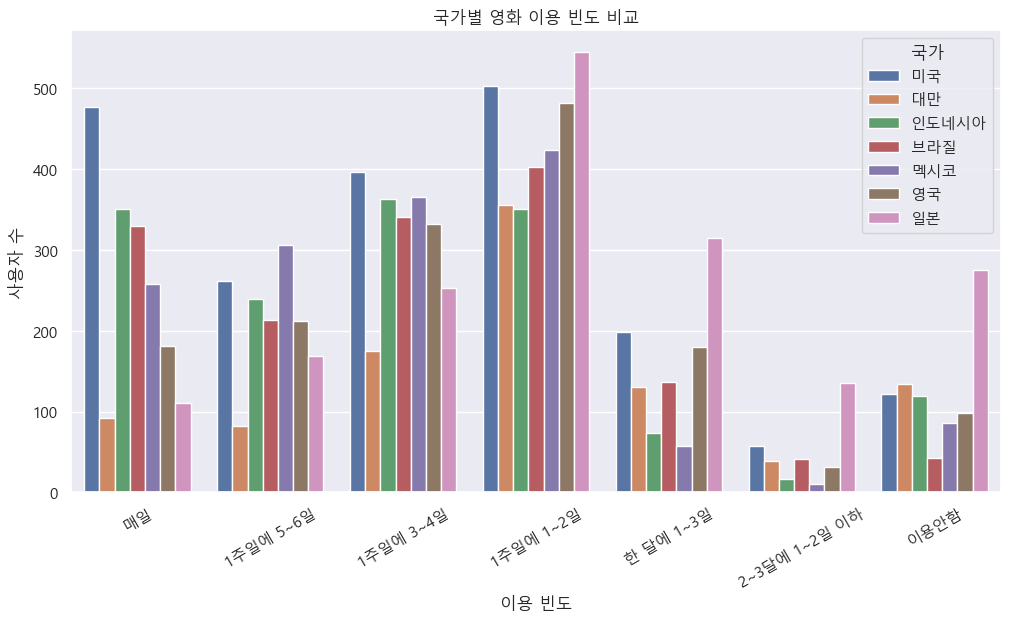

In [40]:
sns.countplot(
    data=df_common,
    x='frequency_movie',
    hue='nation',
    order=freq_order
)
plt.title("국가별 영화 이용 빈도 비교")
plt.xlabel("이용 빈도")
plt.ylabel("사용자 수")
plt.xticks(rotation=30)
plt.legend(title='국가')
plt.show()

In [41]:
df_common.groupby('nation')['frequency_movie'].value_counts()

nation  frequency_movie
대만      1주일에 1~2일          356
        1주일에 3~4일          175
        이용안함               134
        한 달에 1~3일          131
        매일                  92
        1주일에 5~6일           82
        2~3달에 1~2일 이하       39
멕시코     1주일에 1~2일          423
        1주일에 3~4일          365
        1주일에 5~6일          306
        매일                 258
        이용안함                86
        한 달에 1~3일           57
        2~3달에 1~2일 이하       10
미국      1주일에 1~2일          502
        매일                 476
        1주일에 3~4일          396
        1주일에 5~6일          262
        한 달에 1~3일          199
        이용안함               122
        2~3달에 1~2일 이하       58
브라질     1주일에 1~2일          403
        1주일에 3~4일          340
        매일                 330
        1주일에 5~6일          213
        한 달에 1~3일          136
        이용안함                42
        2~3달에 1~2일 이하       41
영국      1주일에 1~2일          481
        1주일에 3~4일          332
        1주일에 5~6일          212
        매일     

C:\Users\User\AppData\Local\Temp\ipykernel_9840\2366848400.py:2: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g_movie_gender = sns.catplot(


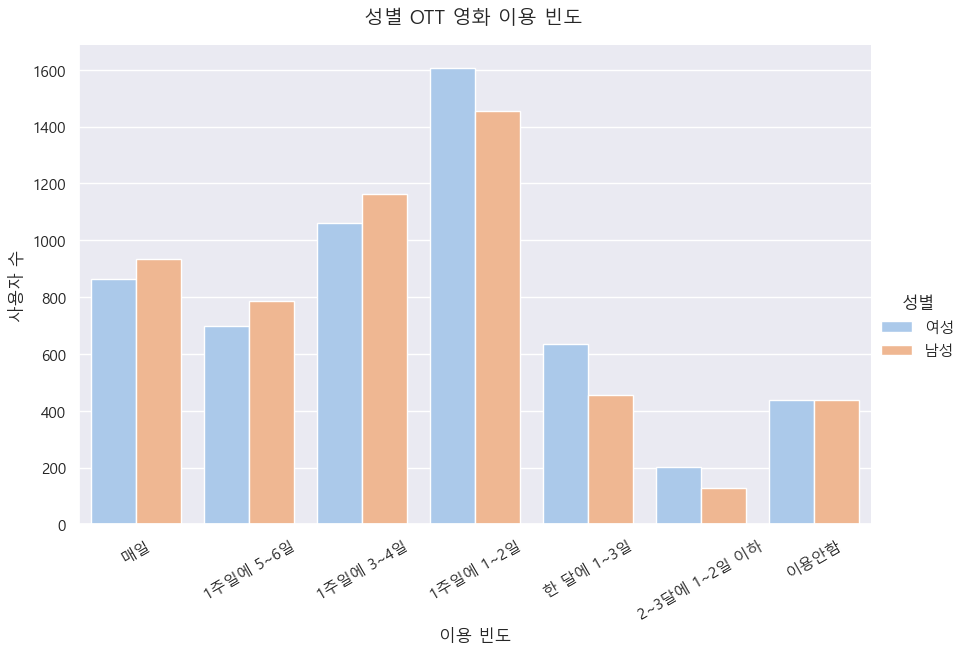

In [42]:
# 성별별 분포 시각화
g_movie_gender = sns.catplot(
    data=df_common,
    x="frequency_movie",
    kind="count",
    hue="gender",
    order=freq_order,
    height=6,
    aspect=1.5,
    palette=pastel_palette
)

# 축 및 제목 설정
g_movie_gender.set_axis_labels("이용 빈도", "사용자 수")
g_movie_gender.set_xticklabels(rotation=30)
g_movie_gender._legend.set_title("성별")
g_movie_gender.fig.suptitle("성별 OTT 영화 이용 빈도", fontsize=14)
g_movie_gender.fig.subplots_adjust(top=0.92)

plt.show()

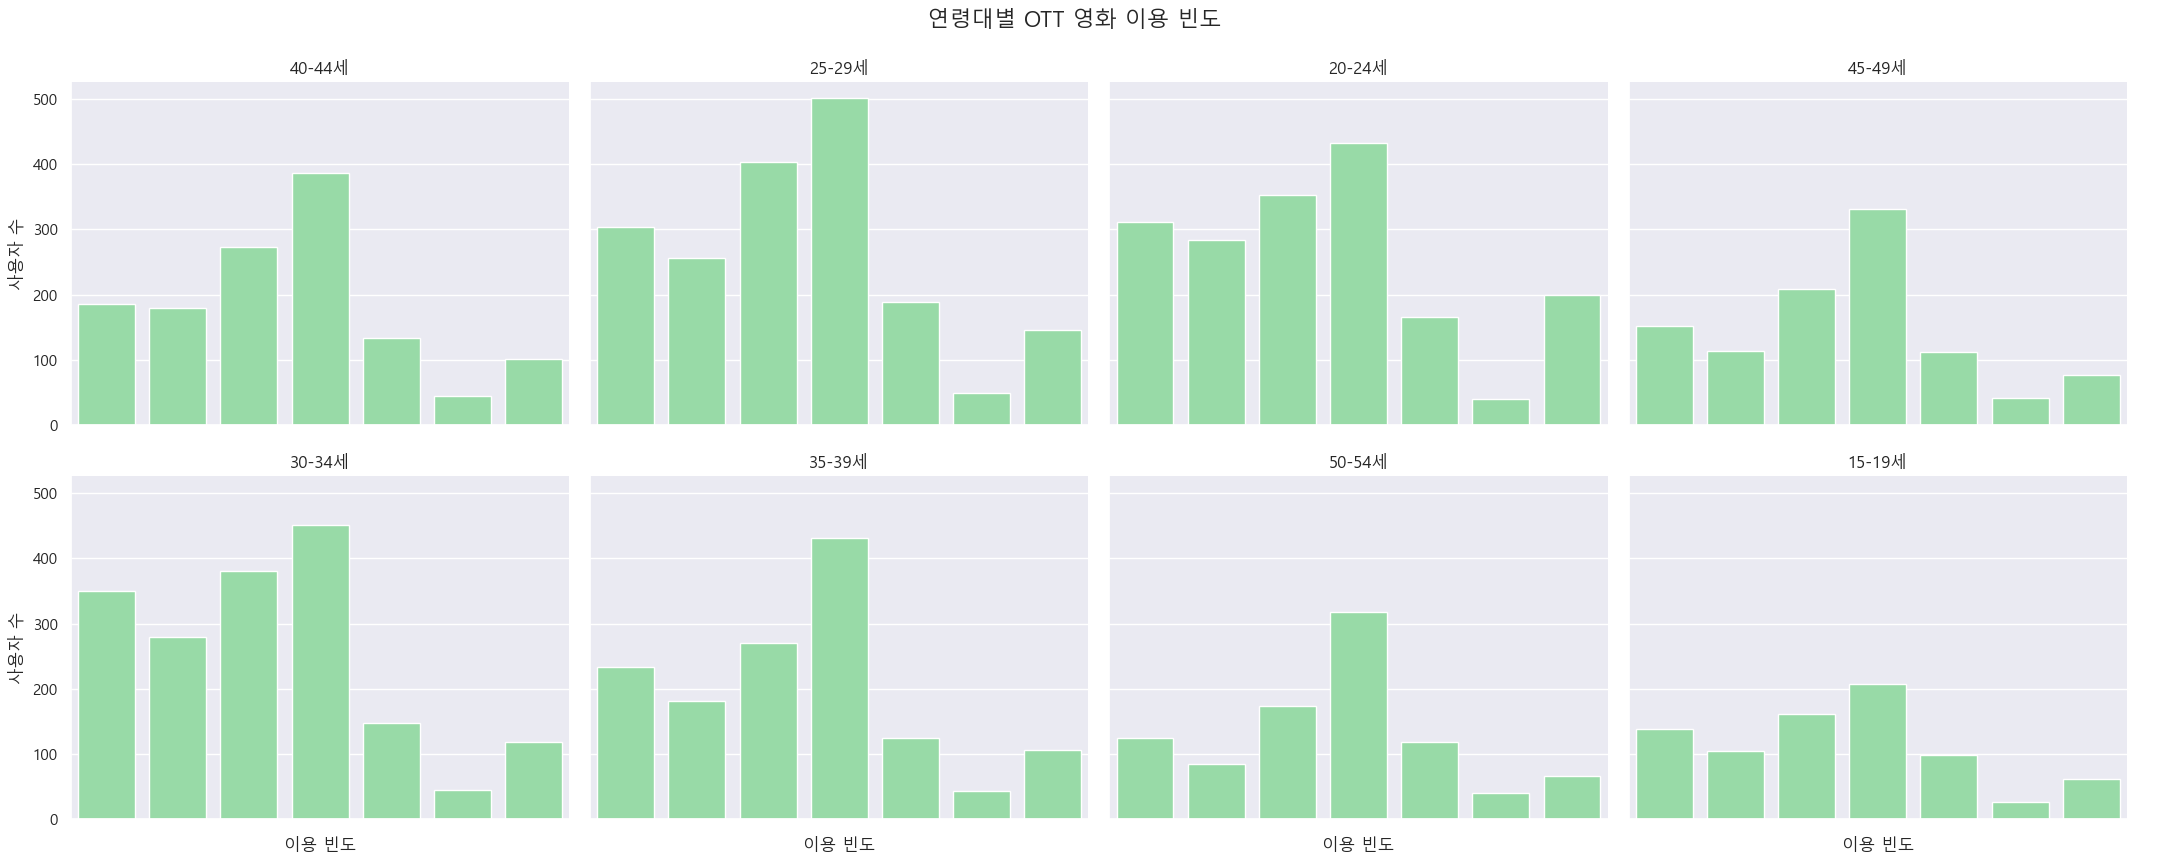

In [43]:
# 연령대별 영화 이용 빈도 분포
g_movie_age = sns.catplot(
    data=df_common,
    x="frequency_movie",
    kind="count",
    col="age",           # 연령대별 subplot
    order=freq_order,
    col_wrap=4,          # 한 줄당 subplot 개수
    height=4.5,
    aspect=1.2,
    color=pastel_palette[2]  # 예쁜 파스텔 계열 중 하나 선택
)

# 시각화 설정
g_movie_age.set_titles("{col_name}")
g_movie_age.set_xticklabels(rotation=45)
g_movie_age.set_axis_labels("이용 빈도", "사용자 수")
g_movie_age.fig.subplots_adjust(top=0.9)
g_movie_age.fig.suptitle("연령대별 OTT 영화 이용 빈도", fontsize=16)

plt.show()

### OTT 콘텐츠 이용 빈도 (예능/버라이어티)

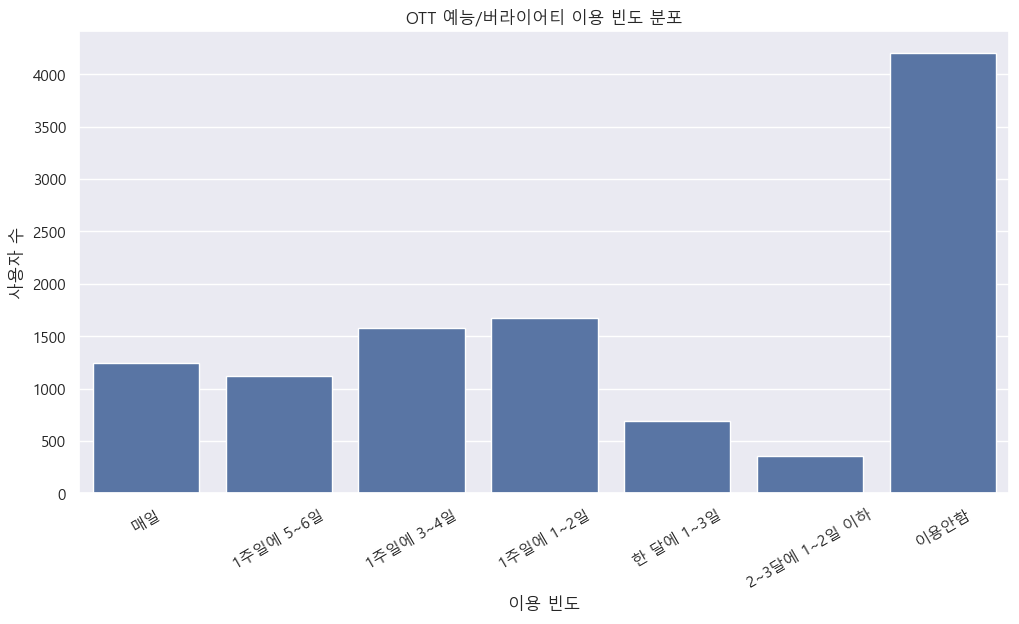

In [44]:
df_common.loc[:, 'frequency_variety'] = pd.Categorical(
    df_common['frequency_variety'],
    categories=freq_order,
    ordered=True
)

sns.countplot(data=df_common, x='frequency_variety', order=freq_order)
plt.title("OTT 예능/버라이어티 이용 빈도 분포")
plt.xlabel("이용 빈도")
plt.ylabel("사용자 수")
plt.xticks(rotation=30)
plt.show()

In [45]:
df_common['frequency_variety'].value_counts()

frequency_variety
이용안함             4199
1주일에 1~2일        1679
1주일에 3~4일        1575
매일               1245
1주일에 5~6일        1119
한 달에 1~3일         687
2~3달에 1~2일 이하     358
Name: count, dtype: int64

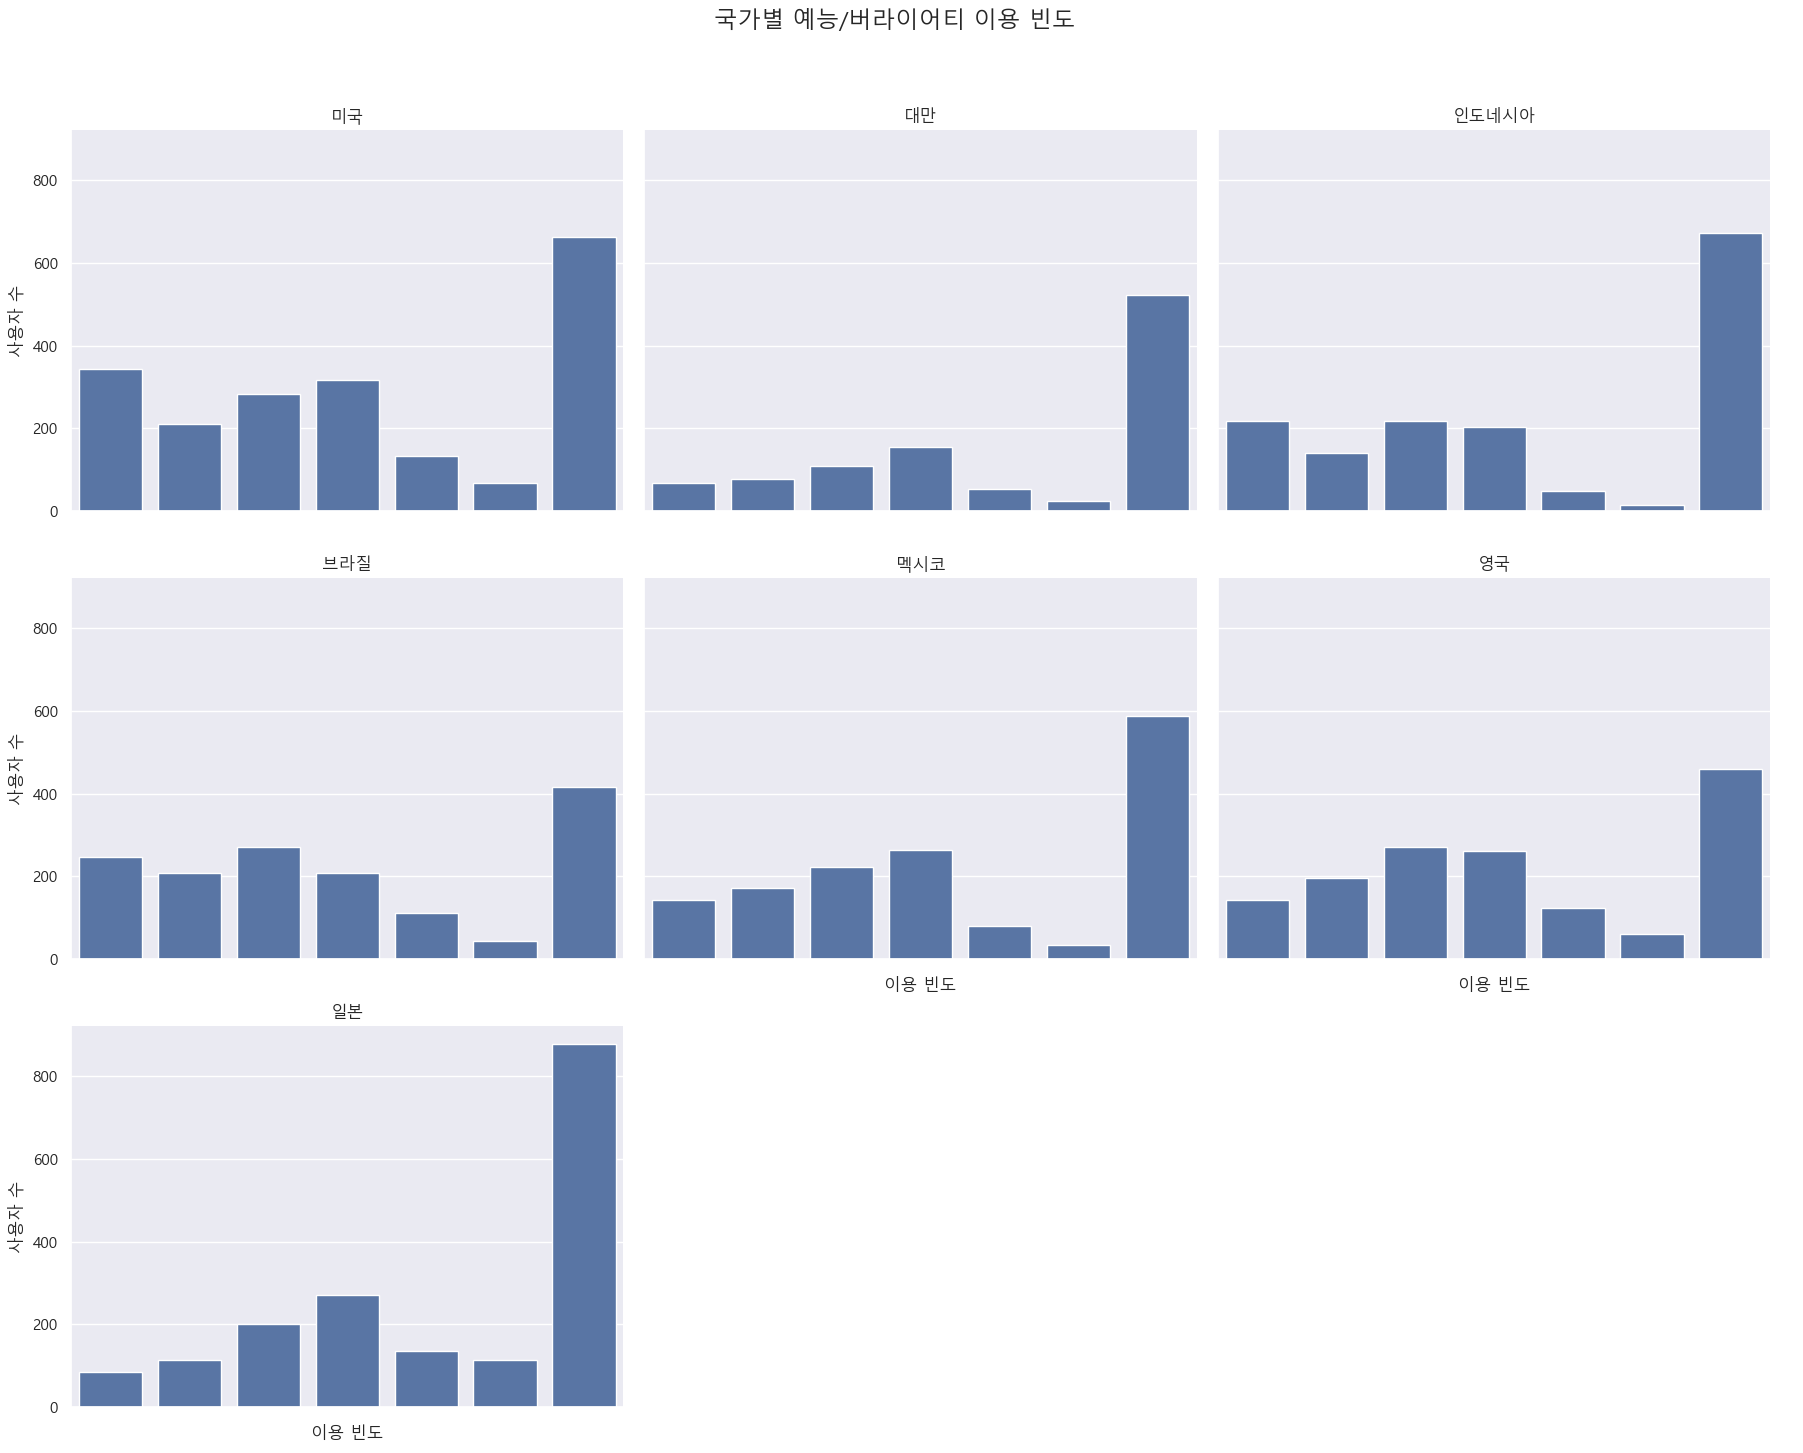

In [46]:
g = sns.catplot(
    data=df_common,
    x="frequency_variety",
    kind="count",
    col="nation",
    order=freq_order,
    col_wrap=3,      # 열 개수 조정 (나라 수 많으면 3~4 권장)
    height=5,
    aspect=1.2
)
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45)
g.set_axis_labels("이용 빈도", "사용자 수")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("국가별 예능/버라이어티 이용 빈도")
plt.show()

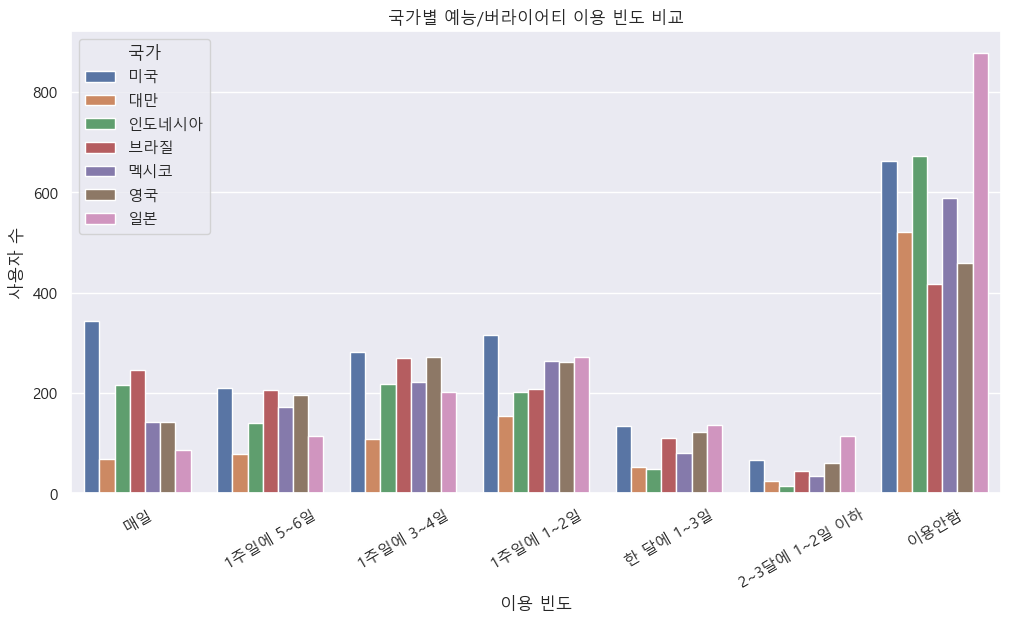

In [47]:
sns.countplot(
    data=df_common,
    x='frequency_variety',
    hue='nation',
    order=freq_order
)
plt.title("국가별 예능/버라이어티 이용 빈도 비교")
plt.xlabel("이용 빈도")
plt.ylabel("사용자 수")
plt.xticks(rotation=30)
plt.legend(title='국가')
plt.show()

In [48]:
df_common.groupby('nation')['frequency_variety'].value_counts()

nation  frequency_variety
대만      이용안함                 522
        1주일에 1~2일            155
        1주일에 3~4일            109
        1주일에 5~6일             78
        매일                    68
        한 달에 1~3일             53
        2~3달에 1~2일 이하         24
멕시코     이용안함                 588
        1주일에 1~2일            264
        1주일에 3~4일            222
        1주일에 5~6일            173
        매일                   142
        한 달에 1~3일             81
        2~3달에 1~2일 이하         35
미국      이용안함                 663
        매일                   343
        1주일에 1~2일            316
        1주일에 3~4일            282
        1주일에 5~6일            210
        한 달에 1~3일            134
        2~3달에 1~2일 이하         67
브라질     이용안함                 417
        1주일에 3~4일            270
        매일                   247
        1주일에 1~2일            209
        1주일에 5~6일            207
        한 달에 1~3일            111
        2~3달에 1~2일 이하         44
영국      이용안함                 460
        1주일에 3~4일

C:\Users\User\AppData\Local\Temp\ipykernel_9840\3506293848.py:2: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g_variety_gender = sns.catplot(


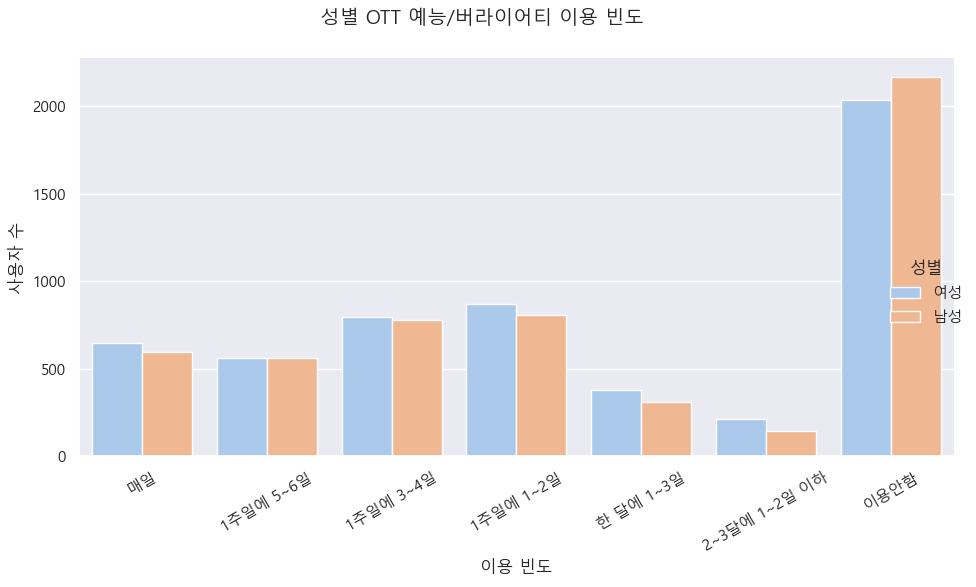

In [49]:
# 성별별 분포
g_variety_gender = sns.catplot(
    data=df_common,
    x="frequency_variety",
    kind="count",
    hue="gender",
    order=freq_order,
    height=6,
    aspect=1.5,
    palette=pastel_palette
)

g_variety_gender.set_axis_labels("이용 빈도", "사용자 수")
g_variety_gender.set_xticklabels(rotation=30)
g_variety_gender._legend.set_title("성별")
g_variety_gender.fig.suptitle("성별 OTT 예능/버라이어티 이용 빈도", fontsize=14)
plt.tight_layout()
plt.show()


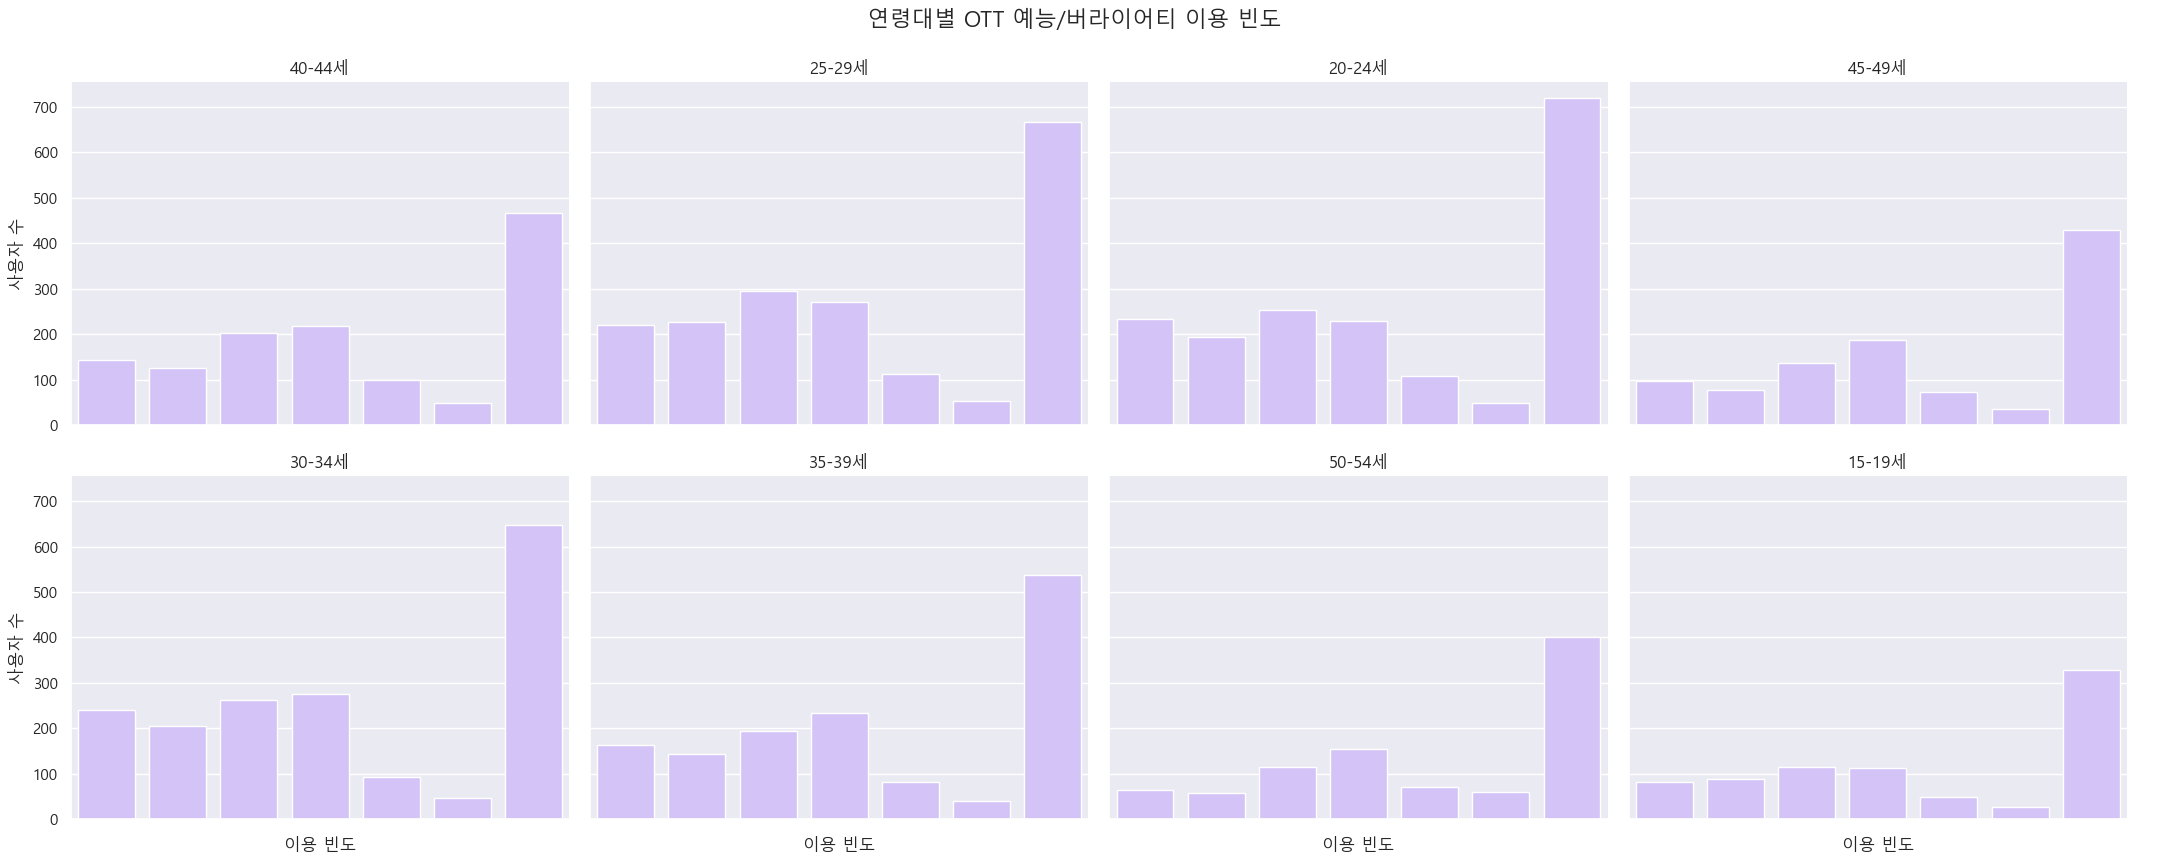

In [50]:
# 연령대별 subplot 분포
g_variety_age = sns.catplot(
    data=df_common,
    x="frequency_variety",
    kind="count",
    col="age",
    order=freq_order,
    col_wrap=4,
    height=4.5,
    aspect=1.2,
    color=pastel_palette[4]
)

g_variety_age.set_titles("{col_name}")
g_variety_age.set_xticklabels(rotation=45)
g_variety_age.set_axis_labels("이용 빈도", "사용자 수")
g_variety_age.fig.subplots_adjust(top=0.9)
g_variety_age.fig.suptitle("연령대별 OTT 예능/버라이어티 이용 빈도", fontsize=16)
plt.show()

### OTT 콘텐츠 이용 빈도 (음악)

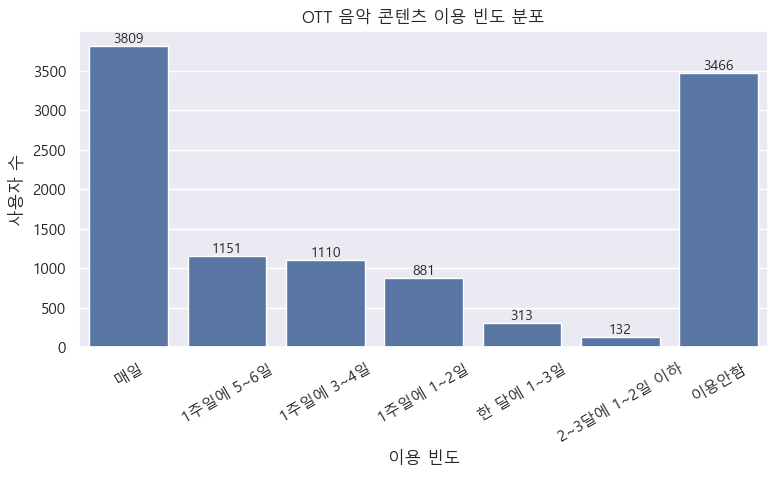

In [51]:
# 범주형 순서 지정
df_common.loc[:, 'frequency_music'] = pd.Categorical(
    df_common['frequency_music'],
    categories=freq_order,
    ordered=True
)

# 시각화
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_common, x='frequency_music', order=freq_order)

# 막대 위에 수치 표시
for container in ax.containers:
    ax.bar_label(container, label_type='edge', fontsize=10)

# 제목 및 축 설정
plt.title("OTT 음악 콘텐츠 이용 빈도 분포")
plt.xlabel("이용 빈도")
plt.ylabel("사용자 수")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_9840\2261070481.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_common['frequency_music'] = pd.Categorical(


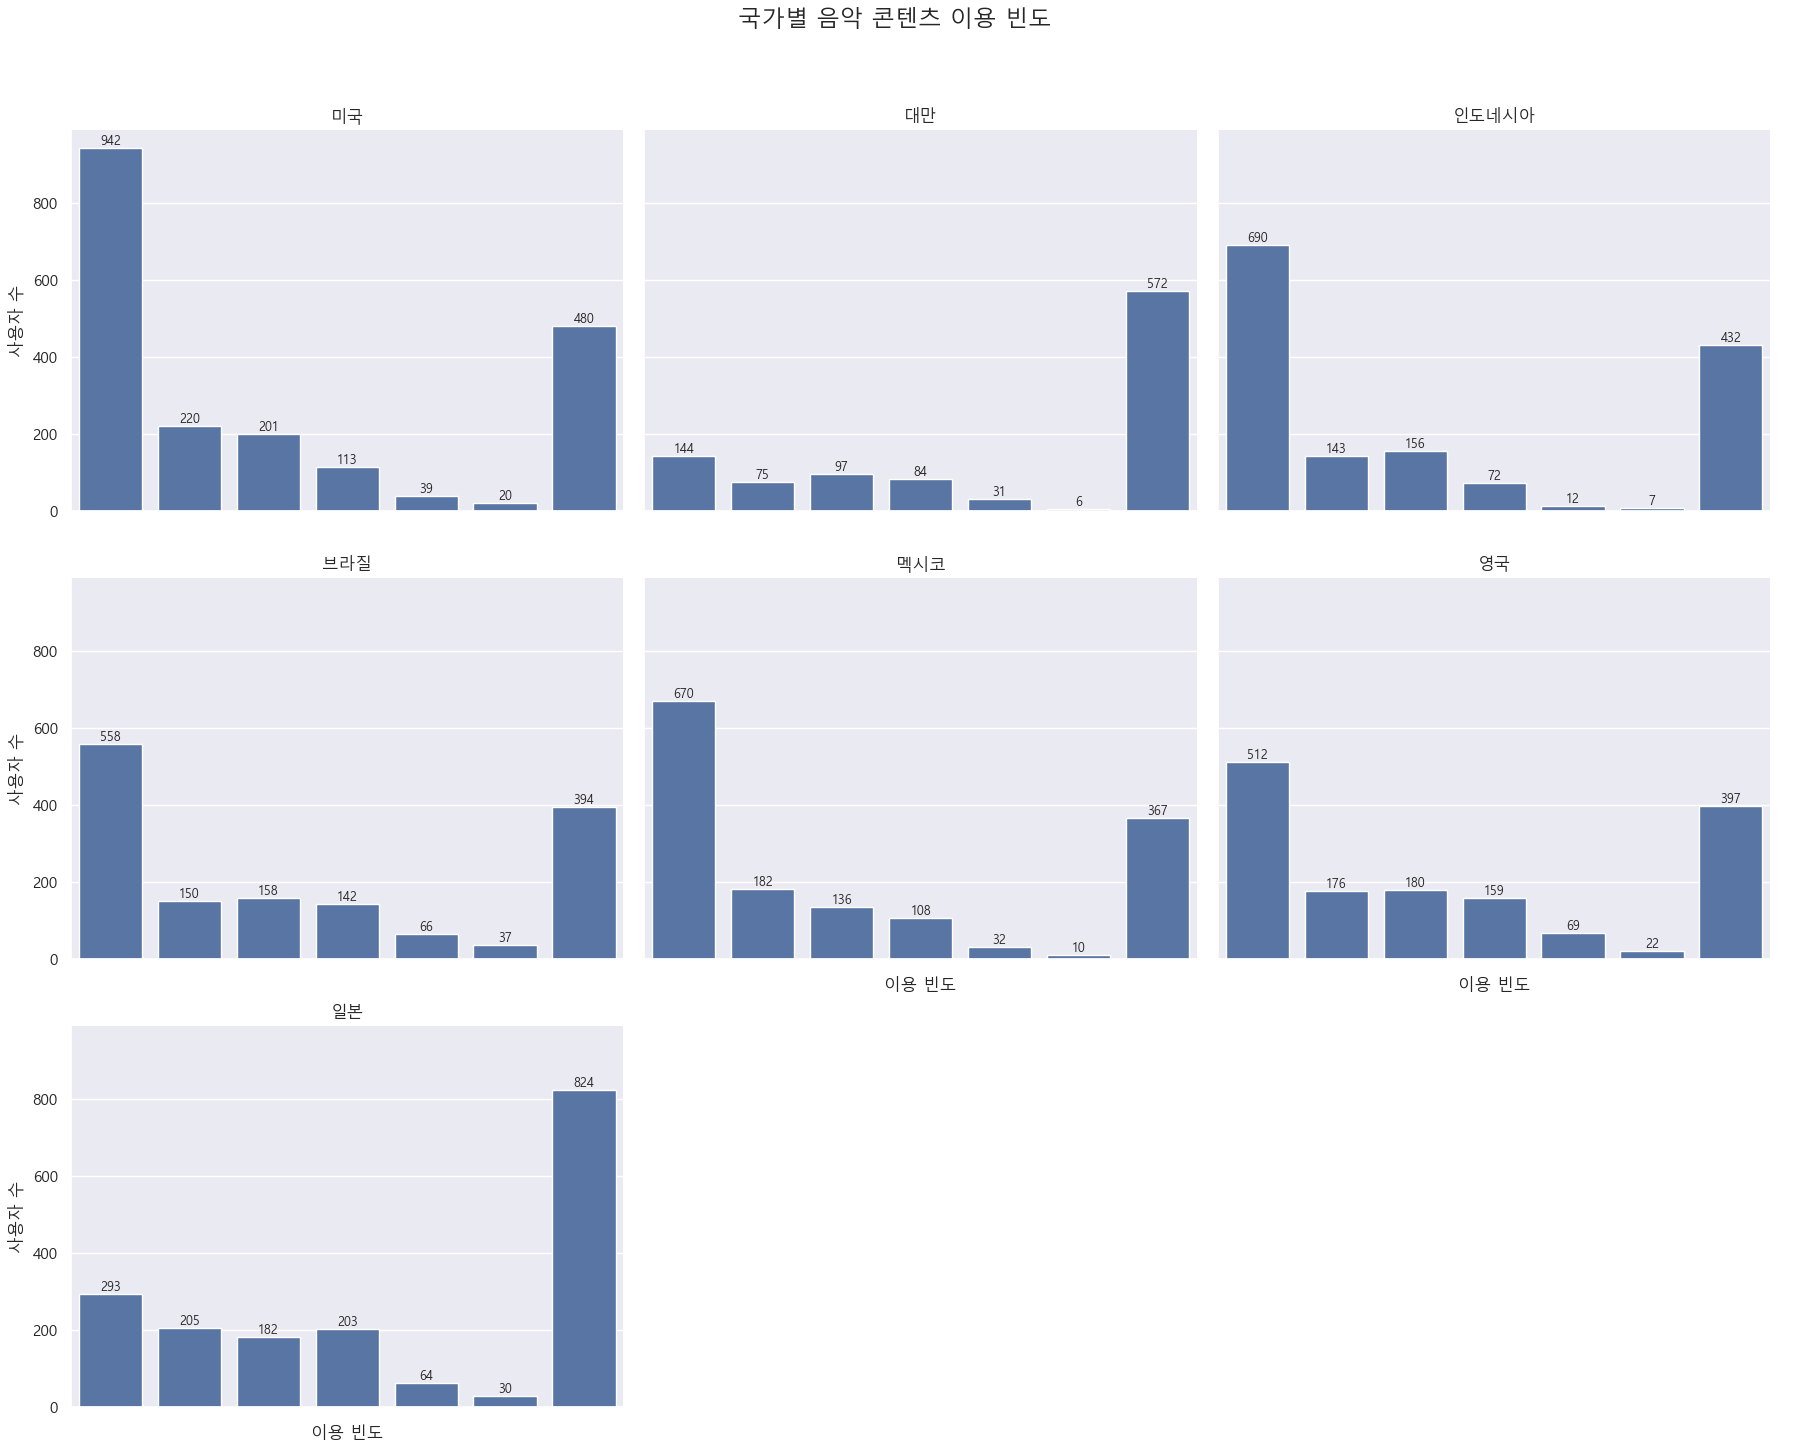

In [52]:
# 범주 순서 지정
df_common['frequency_music'] = pd.Categorical(
    df_common['frequency_music'],
    categories=freq_order,
    ordered=True
)

# catplot 생성
g = sns.catplot(
    data=df_common,
    x="frequency_music",
    kind="count",
    col="nation",
    order=freq_order,
    col_wrap=3,
    height=5,
    aspect=1.2
)

# 타이틀 및 축 설정
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45)
g.set_axis_labels("이용 빈도", "사용자 수")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("국가별 음악 콘텐츠 이용 빈도")

# 막대 위 수치 표시
for ax in g.axes.flatten():
    for container in ax.containers:
        ax.bar_label(container, label_type='edge', fontsize=9)

plt.show()


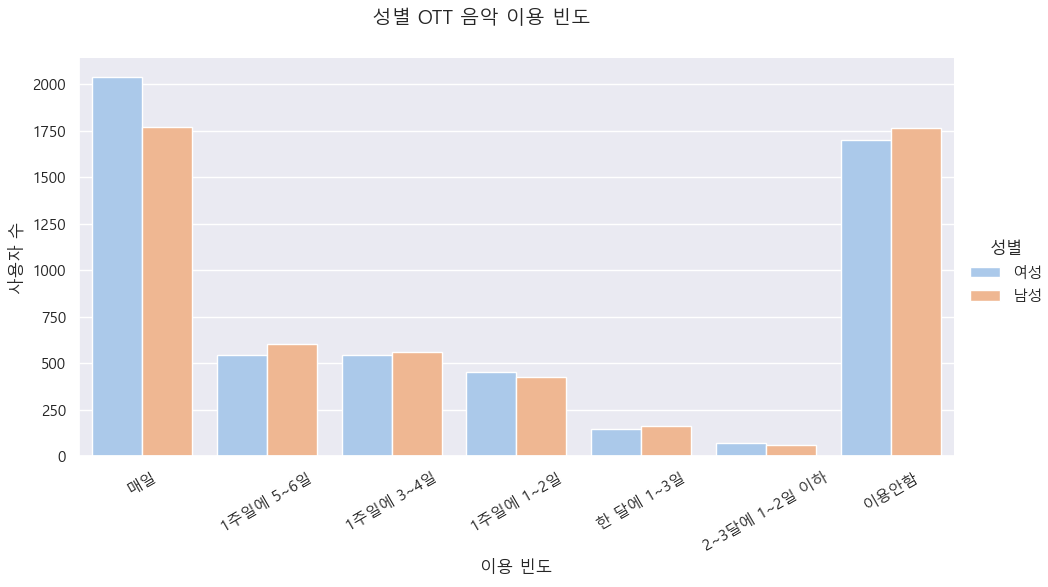

In [53]:
g = sns.catplot(
    data=df_common,
    x="frequency_music",
    kind="count",
    hue="gender",
    order=freq_order,
    height=6,
    aspect=1.5,
    palette="pastel"
)

g.set_axis_labels("이용 빈도", "사용자 수")
g.set_xticklabels(rotation=30)
g._legend.set_title("성별")
g._legend.set_bbox_to_anchor((0.97, 0.6))
g._legend.set_loc("upper left")

g.fig.suptitle("성별 OTT 음악 이용 빈도", fontsize=14)
plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_9840\3633450949.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g_age = sns.catplot(


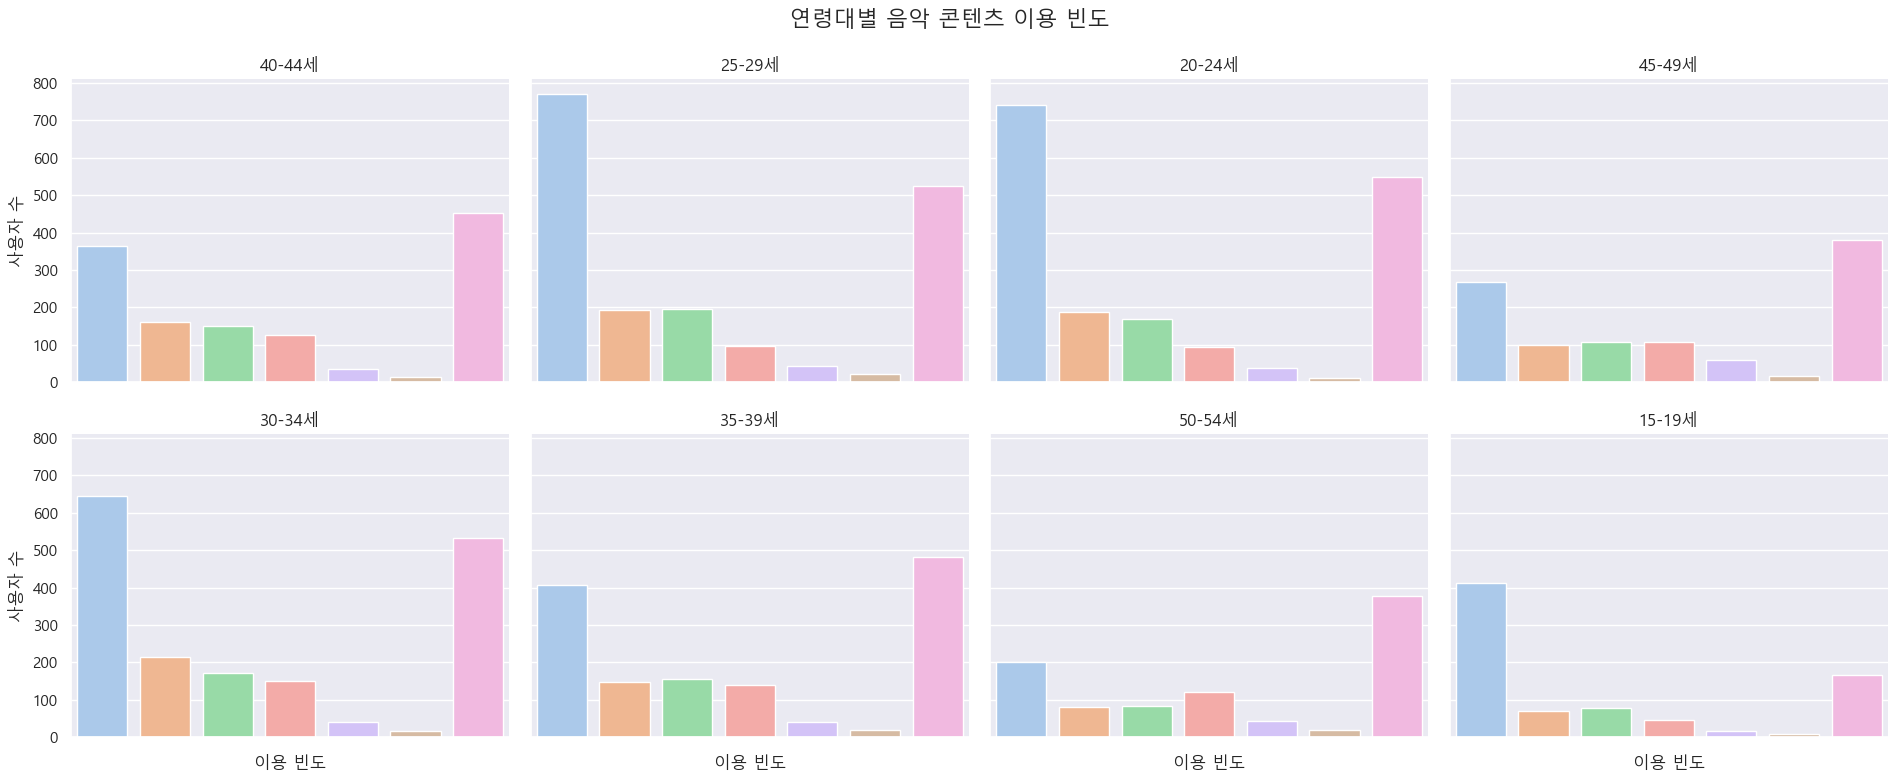

In [54]:
g_age = sns.catplot(
    data=df_common,
    x="frequency_music",
    col="age",
    kind="count",
    col_wrap=4,
    order=freq_order,
    height=4,
    aspect=1.2,
    palette="pastel"
)

# 축 및 제목 설정
g_age.set_titles("{col_name}")  # 개별 서브플롯 제목
g_age.set_axis_labels("이용 빈도", "사용자 수")  # 공통 축 라벨
g_age.set_xticklabels(rotation=30)

# 전체 제목
g_age.fig.subplots_adjust(top=0.9)
g_age.fig.suptitle("연령대별 음악 콘텐츠 이용 빈도", fontsize=16)

plt.tight_layout()
plt.show()

### OTT 콘텐츠 이용 빈도 (웹소설)

C:\Users\User\AppData\Local\Temp\ipykernel_9840\1004869901.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_common['frequency_webnovel'] = pd.Categorical(df_common['frequency_webnovel'], categories=freq_order, ordered=True)


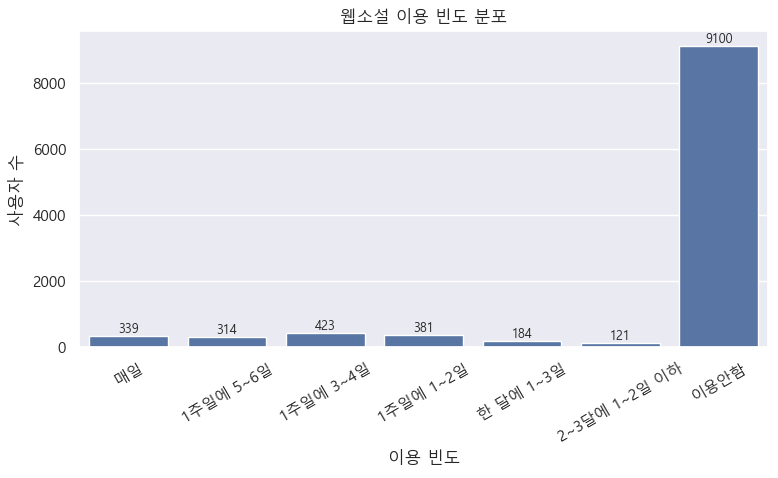

In [55]:
df_common['frequency_webnovel'] = pd.Categorical(df_common['frequency_webnovel'], categories=freq_order, ordered=True)

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_common, x='frequency_webnovel', order=freq_order)
plt.title("웹소설 이용 빈도 분포")
plt.xlabel("이용 빈도")
plt.ylabel("사용자 수")
plt.xticks(rotation=30)

# 수치 표시
for container in ax.containers:
    ax.bar_label(container, label_type='edge', fontsize=9)

plt.tight_layout()
plt.show()

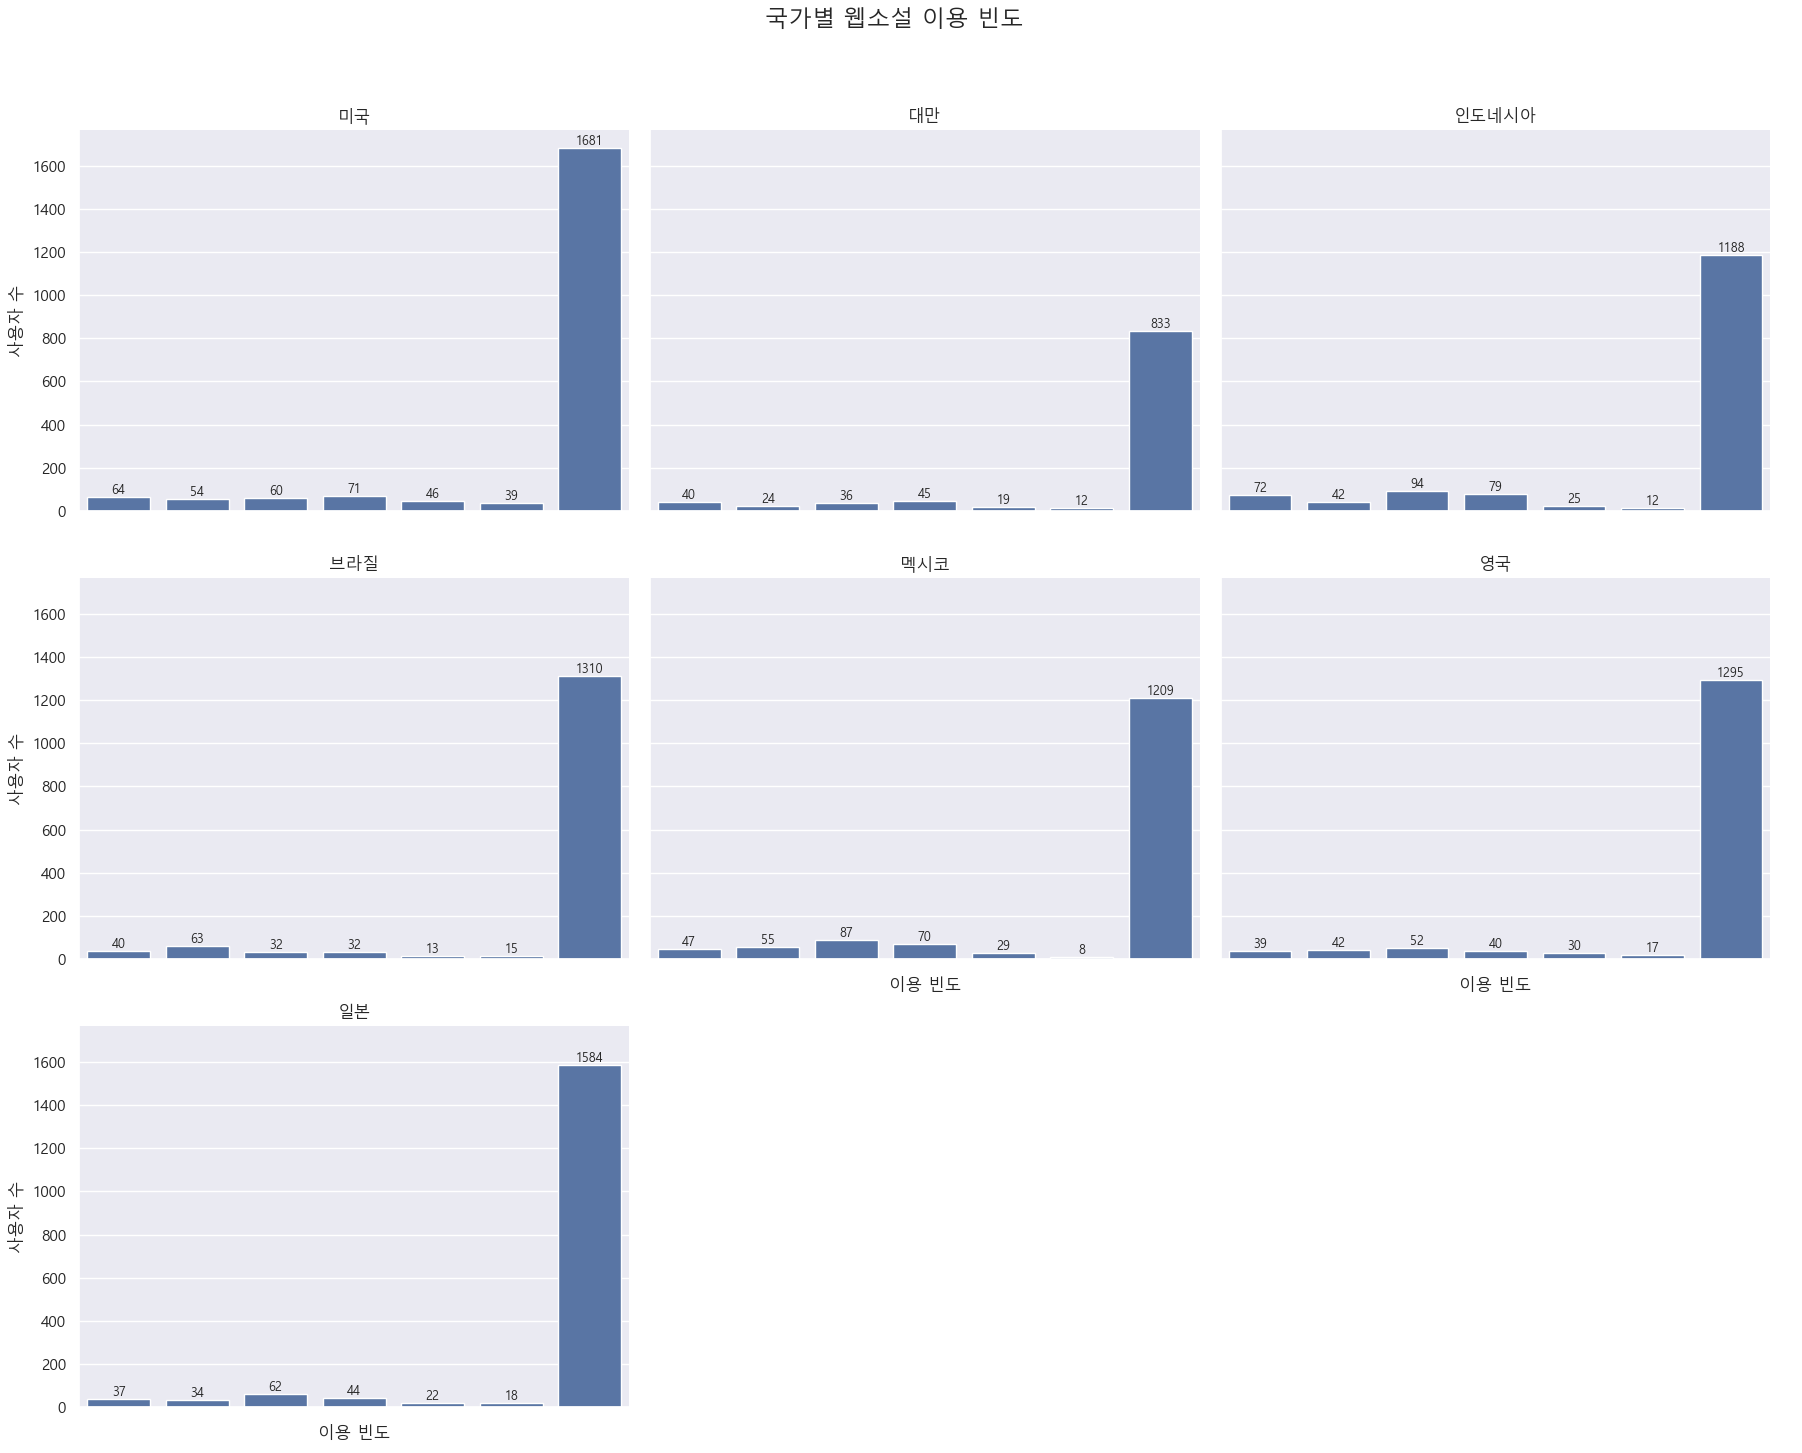

In [56]:
g = sns.catplot(
    data=df_common,
    x="frequency_webnovel",
    kind="count",
    col="nation",
    order=freq_order,
    col_wrap=3,
    height=5,
    aspect=1.2
)
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45)
g.set_axis_labels("이용 빈도", "사용자 수")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("국가별 웹소설 이용 빈도")

# 수치 표시
for ax in g.axes.flatten():
    for container in ax.containers:
        ax.bar_label(container, label_type='edge', fontsize=9)

plt.show()

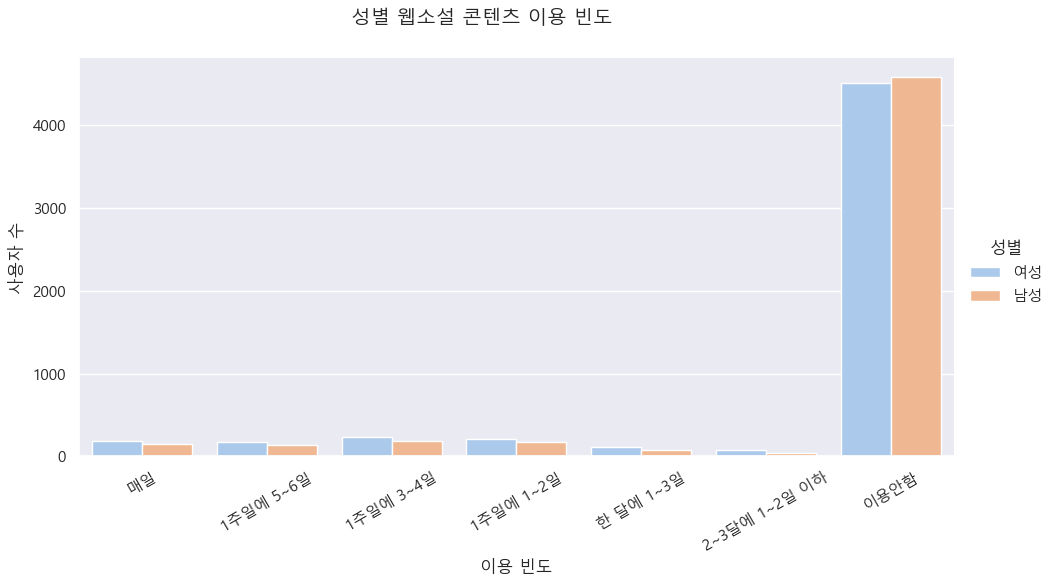

In [57]:
g_webnovel_gender = sns.catplot(
    data=df_common,
    x="frequency_webnovel",
    kind="count",
    hue="gender",
    order=freq_order,
    height=6,
    aspect=1.5,
    palette="pastel"
)
g_webnovel_gender.set_axis_labels("이용 빈도", "사용자 수")
g_webnovel_gender.set_xticklabels(rotation=30)
g_webnovel_gender._legend.set_title("성별")
g_webnovel_gender._legend.set_bbox_to_anchor((0.97, 0.6))
g_webnovel_gender._legend.set_loc("upper left")
g_webnovel_gender.fig.suptitle("성별 웹소설 콘텐츠 이용 빈도", fontsize=14)
plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_9840\1343498477.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g_webnovel_age = sns.catplot(


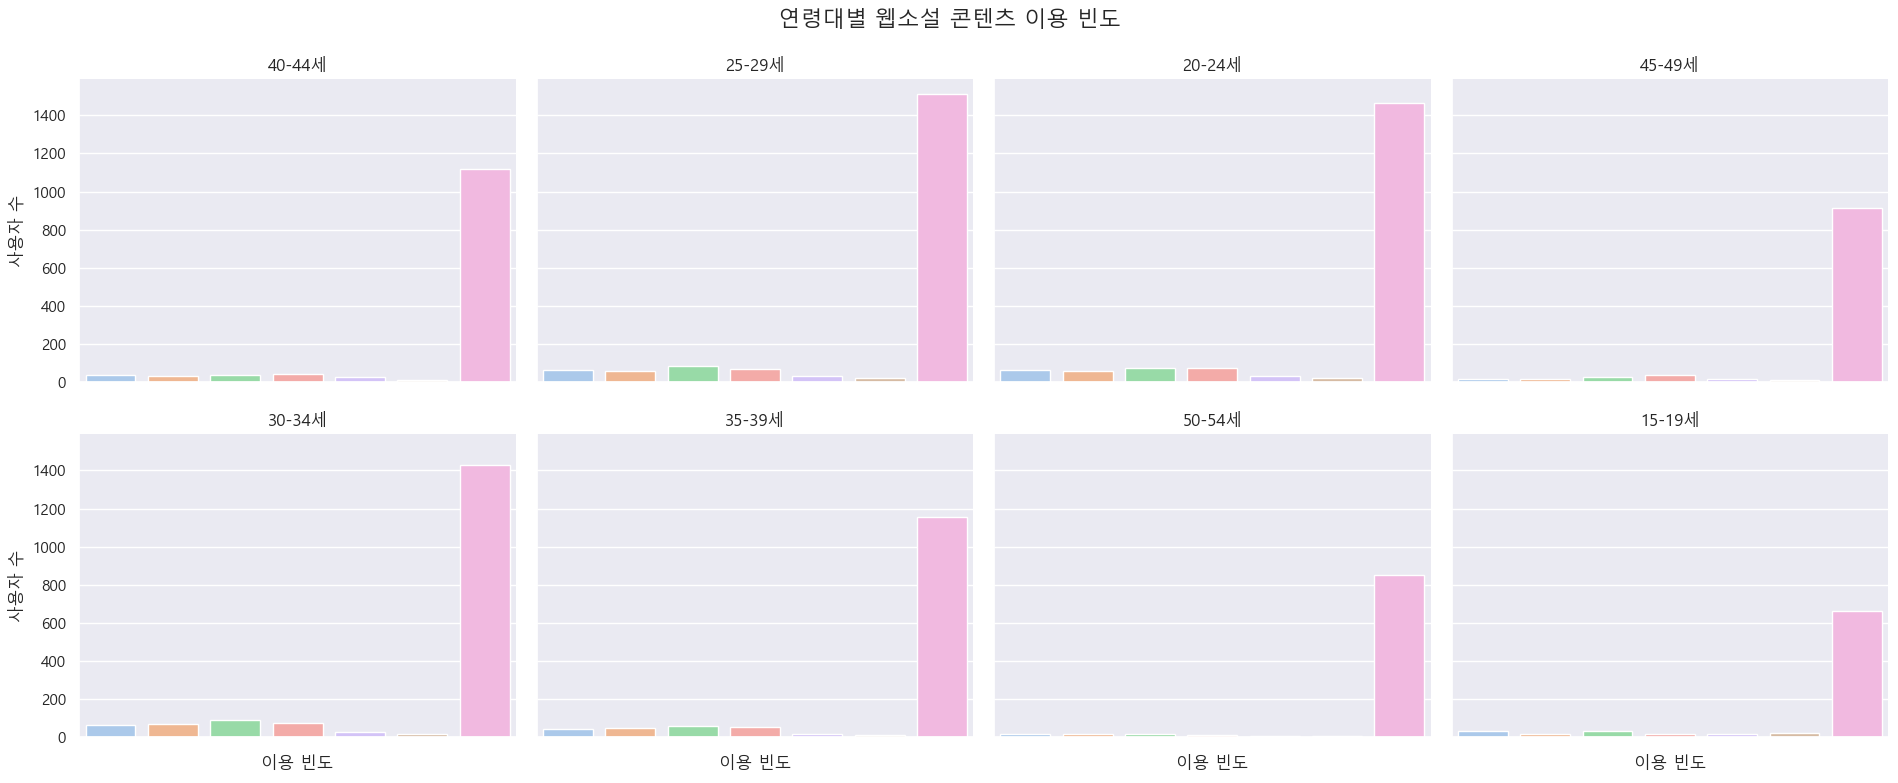

In [58]:
g_webnovel_age = sns.catplot(
    data=df_common,
    x="frequency_webnovel",
    col="age",
    kind="count",
    col_wrap=4,
    order=freq_order,
    height=4,
    aspect=1.2,
    palette="pastel"
)
g_webnovel_age.set_titles("{col_name}")
g_webnovel_age.set_axis_labels("이용 빈도", "사용자 수")
g_webnovel_age.set_xticklabels(rotation=30)
g_webnovel_age.fig.subplots_adjust(top=0.9)
g_webnovel_age.fig.suptitle("연령대별 웹소설 콘텐츠 이용 빈도", fontsize=16)
plt.tight_layout()
plt.show()

### OTT 콘텐츠 이용 빈도 (웹툰)

C:\Users\User\AppData\Local\Temp\ipykernel_9840\4001966224.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_common['frequency_webtoon'] = pd.Categorical(df_common['frequency_webtoon'], categories=freq_order, ordered=True)


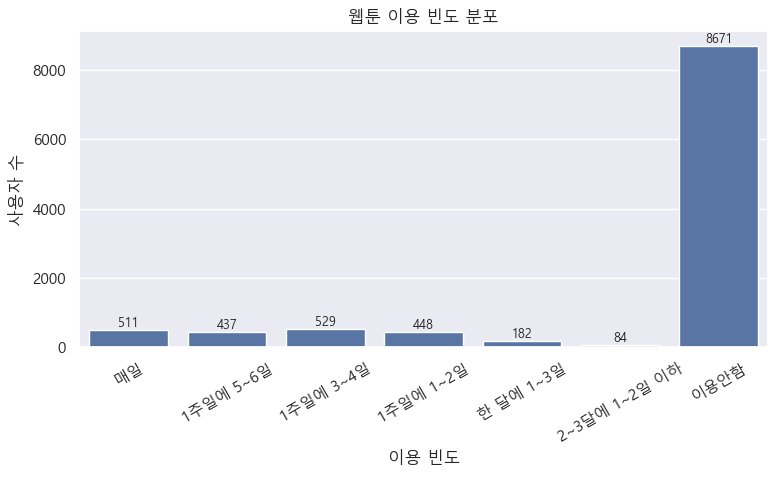

In [59]:
df_common['frequency_webtoon'] = pd.Categorical(df_common['frequency_webtoon'], categories=freq_order, ordered=True)

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_common, x='frequency_webtoon', order=freq_order)
plt.title("웹툰 이용 빈도 분포")
plt.xlabel("이용 빈도")
plt.ylabel("사용자 수")
plt.xticks(rotation=30)

# 수치 표시
for container in ax.containers:
    ax.bar_label(container, label_type='edge', fontsize=9)

plt.tight_layout()
plt.show()


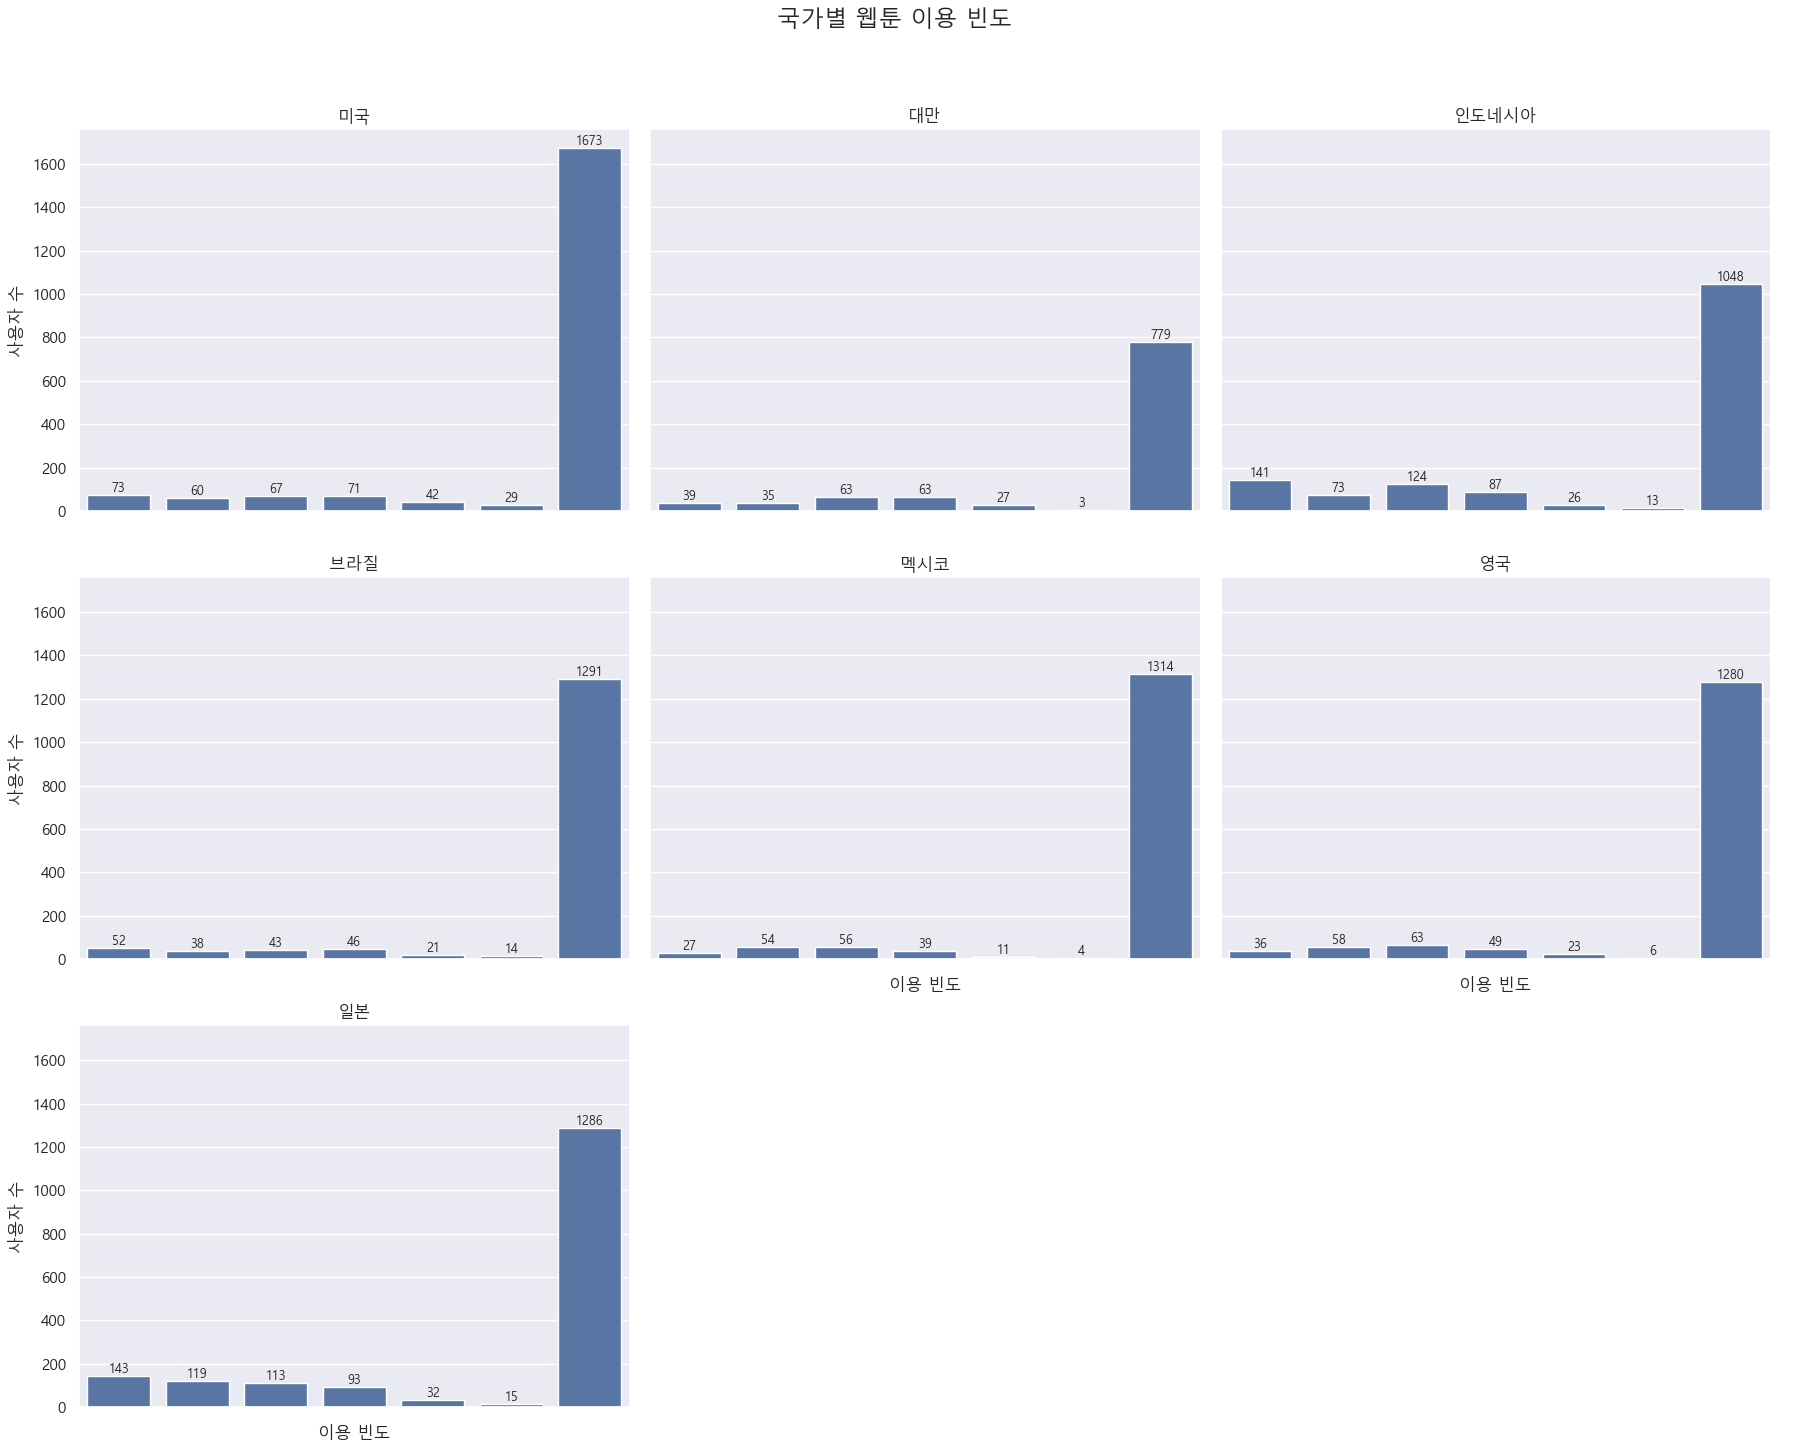

In [60]:
g = sns.catplot(
    data=df_common,
    x="frequency_webtoon",
    kind="count",
    col="nation",
    order=freq_order,
    col_wrap=3,
    height=5,
    aspect=1.2
)
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45)
g.set_axis_labels("이용 빈도", "사용자 수")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("국가별 웹툰 이용 빈도")

# 수치 표시
for ax in g.axes.flatten():
    for container in ax.containers:
        ax.bar_label(container, label_type='edge', fontsize=9)

plt.show()

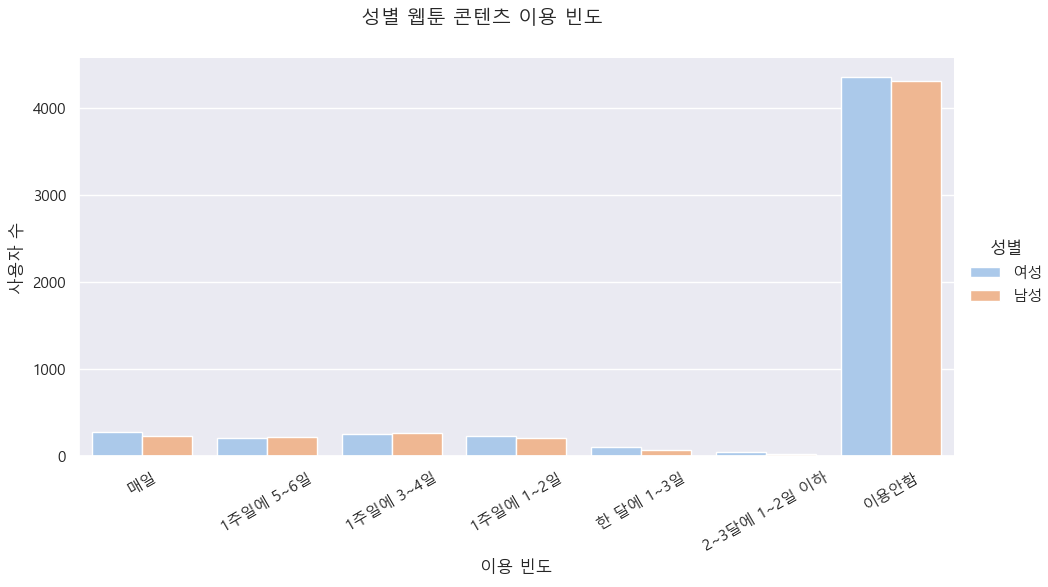

In [61]:
g_webtoon_gender = sns.catplot(
    data=df_common,
    x="frequency_webtoon",
    kind="count",
    hue="gender",
    order=freq_order,
    height=6,
    aspect=1.5,
    palette="pastel"
)
g_webtoon_gender.set_axis_labels("이용 빈도", "사용자 수")
g_webtoon_gender.set_xticklabels(rotation=30)
g_webtoon_gender._legend.set_title("성별")
g_webtoon_gender._legend.set_bbox_to_anchor((0.97, 0.6))
g_webtoon_gender._legend.set_loc("upper left")
g_webtoon_gender.fig.suptitle("성별 웹툰 콘텐츠 이용 빈도", fontsize=14)
plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_9840\1394144149.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g_webtoon_age = sns.catplot(


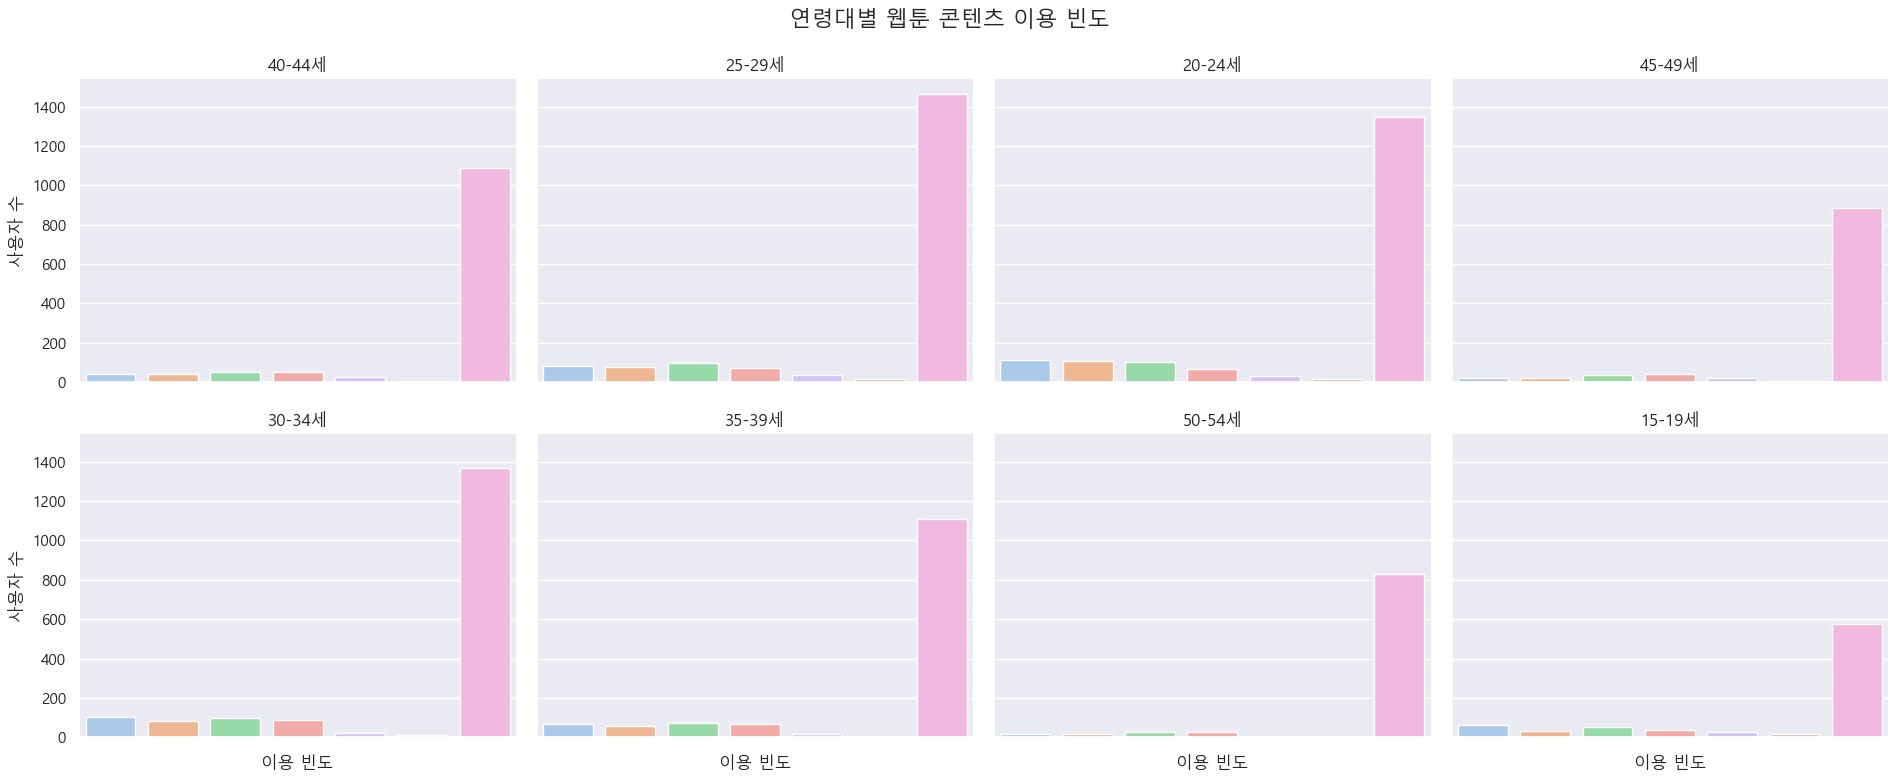

In [62]:
g_webtoon_age = sns.catplot(
    data=df_common,
    x="frequency_webtoon",
    col="age",
    kind="count",
    col_wrap=4,
    order=freq_order,
    height=4,
    aspect=1.2,
    palette="pastel"
)
g_webtoon_age.set_titles("{col_name}")
g_webtoon_age.set_axis_labels("이용 빈도", "사용자 수")
g_webtoon_age.set_xticklabels(rotation=30)
g_webtoon_age.fig.subplots_adjust(top=0.9)
g_webtoon_age.fig.suptitle("연령대별 웹툰 콘텐츠 이용 빈도", fontsize=16)
plt.tight_layout()
plt.show()

### OTT 장르 선호도 비교

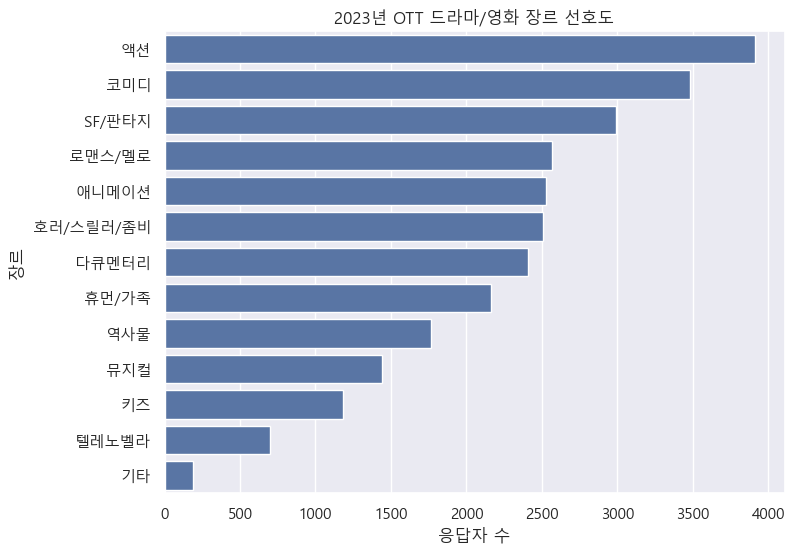

In [63]:
genre_cols_2023 = [col for col in df_2023.columns if col.startswith("genre_series_movie_") and col.endswith("_2023")]
col_to_kor = {
    "genre_series_movie_rom_2023": "로맨스/멜로",
    "genre_series_movie_fant_2023": "SF/판타지",
    "genre_series_movie_action_2023": "액션",
    "genre_series_movie_horr_2023": "호러/스릴러/좀비",
    "genre_series_movie_history_2023": "역사물",
    "genre_series_movie_human_2023": "휴먼/가족",
    "genre_series_movie_docu_2023": "다큐멘터리",
    "genre_series_movie_musical_2023": "뮤지컬",
    "genre_series_movie_comedy_2023": "코미디",
    "genre_series_movie_ani_2023": "애니메이션",
    "genre_series_movie_kids_2023": "키즈",
    "genre_series_movie_teleno_2023": "텔레노벨라",
    "genre_series_movie_etc_2023": "기타"
}

# melt
df_genre = df_2023[genre_cols_2023].melt(var_name="장르코드", value_name="선택")
df_genre = df_genre[df_genre["선택"] == 1]
df_genre["장르"] = df_genre["장르코드"].map(col_to_kor)

# 그래프
plt.figure(figsize=(8, 6))
sns.countplot(data=df_genre, y="장르", order=df_genre["장르"].value_counts().index)
plt.title("2023년 OTT 드라마/영화 장르 선호도")
plt.xlabel("응답자 수")
plt.ylabel("장르")
plt.show()

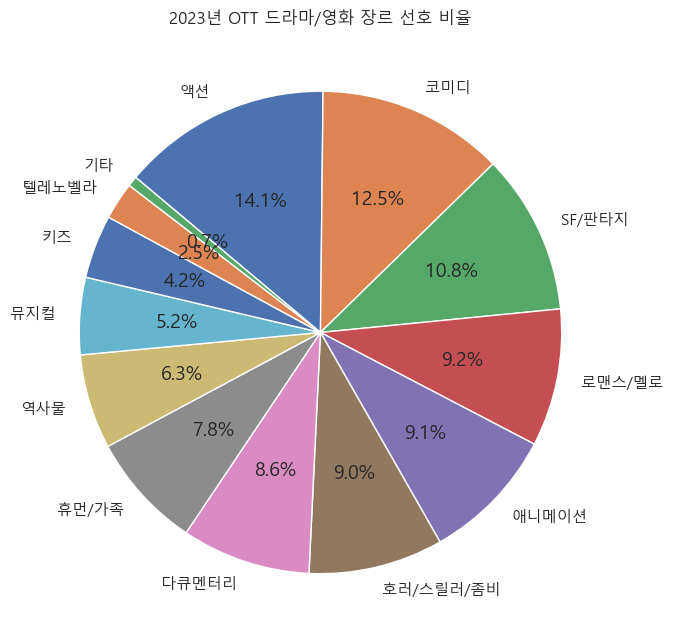

In [64]:
# 장르별 비율 계산
genre_counts_2023 = df_genre["장르"].value_counts()
genre_ratio_2023 = genre_counts_2023 / genre_counts_2023.sum()

# 파이차트 시각화
plt.figure(figsize=(7, 7))
plt.pie(
    genre_ratio_2023,
    labels=genre_ratio_2023.index,
    autopct='%1.1f%%',
    startangle=140,
    counterclock=False
)
plt.title("2023년 OTT 드라마/영화 장르 선호 비율")
plt.tight_layout()
plt.show()

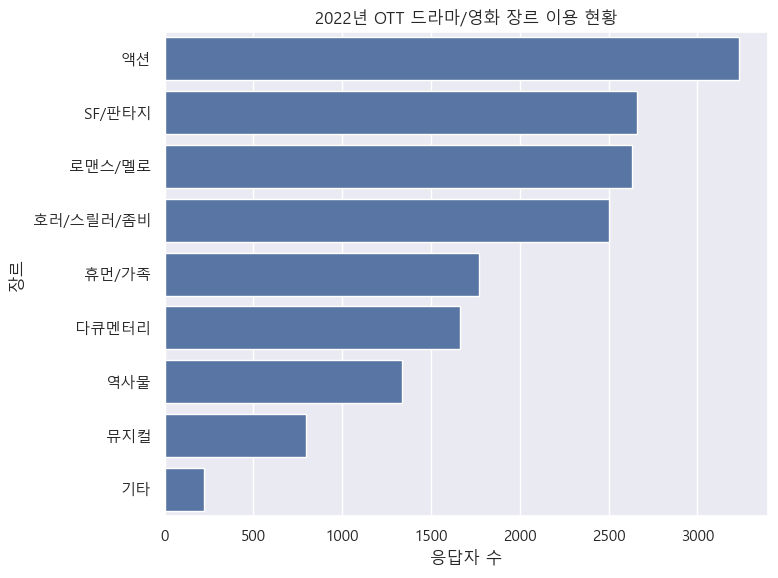

In [65]:
# 2022년 장르 관련 컬럼 추출
genre_cols_2022 = [col for col in df_2022.columns if col.startswith("genre_series_movie_") and col.endswith("_2022")]

# 컬럼명 매핑 (2022용)
col_to_kor_2022 = {
    "genre_series_movie_rom_2022": "로맨스/멜로",
    "genre_series_movie_fant_2022": "SF/판타지",
    "genre_series_movie_action_2022": "액션",
    "genre_series_movie_horr_2022": "호러/스릴러/좀비",
    "genre_series_movie_history_2022": "역사물",
    "genre_series_movie_human_2022": "휴먼/가족",
    "genre_series_movie_docu_2022": "다큐멘터리",
    "genre_series_movie_musical_2022": "뮤지컬",
    "genre_series_movie_etc_2022": "기타"
}

# melt
df_genre_2022 = df_2022[genre_cols_2022].melt(var_name="장르코드", value_name="선택")
df_genre_2022 = df_genre_2022[df_genre_2022["선택"] == 1]
df_genre_2022["장르"] = df_genre_2022["장르코드"].map(col_to_kor_2022)

# 시각화
plt.figure(figsize=(8, 6))
sns.countplot(data=df_genre_2022, y="장르", order=df_genre_2022["장르"].value_counts().index)
plt.title("2022년 OTT 드라마/영화 장르 이용 현황")
plt.xlabel("응답자 수")
plt.ylabel("장르")
plt.tight_layout()
plt.show()

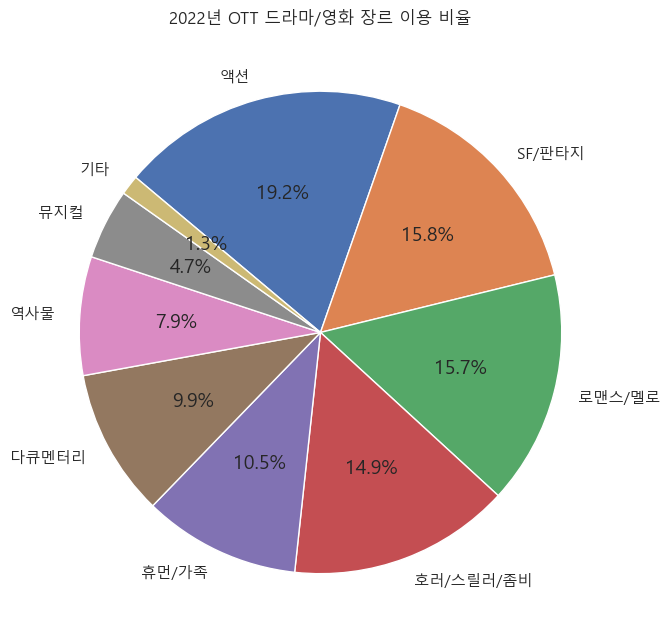

In [66]:
# 장르별 비율 계산
genre_counts_2022 = df_genre_2022["장르"].value_counts()
genre_ratio_2022 = genre_counts_2022 / genre_counts_2022.sum()

# 파이차트 시각화
plt.figure(figsize=(7, 7))
plt.pie(
    genre_ratio_2022,
    labels=genre_ratio_2022.index,
    autopct='%1.1f%%',
    startangle=140,
    counterclock=False
)
plt.title("2022년 OTT 드라마/영화 장르 이용 비율")
plt.tight_layout()
plt.show()

In [67]:
# 1. 컬럼 리스트 지정
genre_cols_2022 = [col for col in df_2022.columns if col.startswith("genre_series_movie_") and col.endswith("_2022")]
genre_cols_2023 = [col for col in df_2023.columns if col.startswith("genre_series_movie_") and col.endswith("_2023")]

# 2. 컬럼 → 한글 매핑
col_to_kor_2022 = {col: val.replace("_2022", "") for col, val in col_to_kor.items() if col.endswith("_2022") or col.replace("_2023", "_2022") in col_to_kor}
col_to_kor_2023 = {col: val for col, val in col_to_kor.items() if col.endswith("_2023")}

# 3. melt 및 선택된 응답만 추출
df_genre_2022 = df_2022[["user_id"] + genre_cols_2022].melt(id_vars="user_id", var_name="장르코드", value_name="선택")
df_genre_2022 = df_genre_2022[df_genre_2022["선택"] == 1]
df_genre_2022["장르"] = df_genre_2022["장르코드"].map(lambda x: col_to_kor_2022.get(x, x))

df_genre_2023 = df_2023[["user_id"] + genre_cols_2023].melt(id_vars="user_id", var_name="장르코드", value_name="선택")
df_genre_2023 = df_genre_2023[df_genre_2023["선택"] == 1]
df_genre_2023["장르"] = df_genre_2023["장르코드"].map(lambda x: col_to_kor_2023.get(x, x))

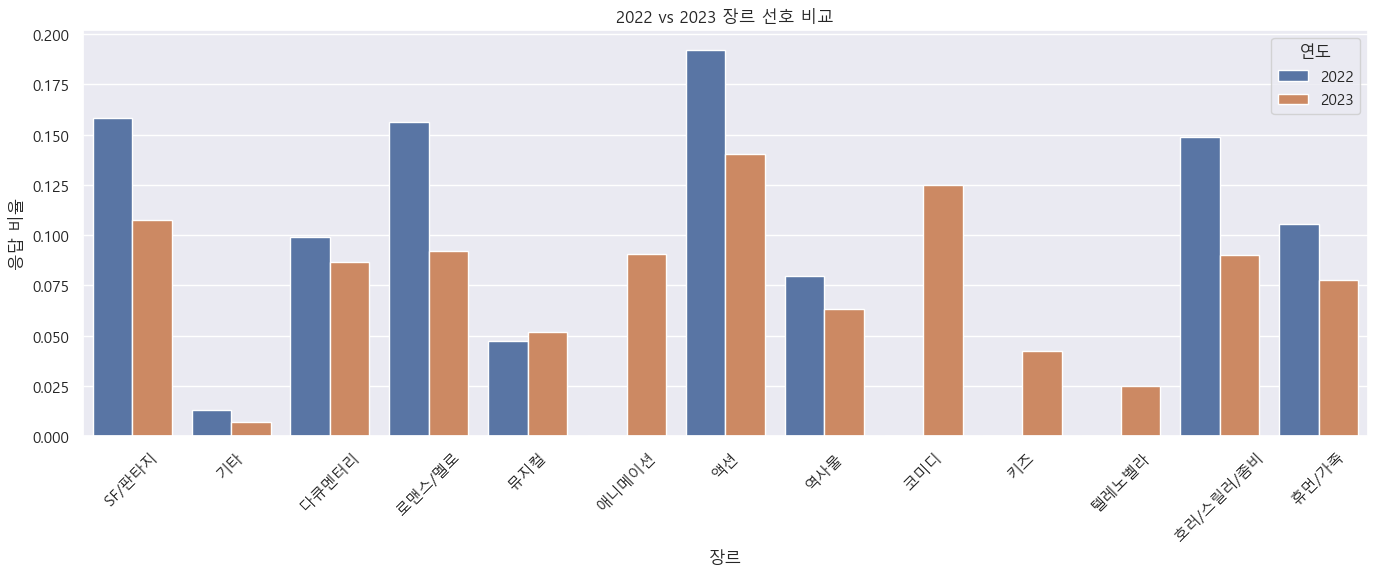

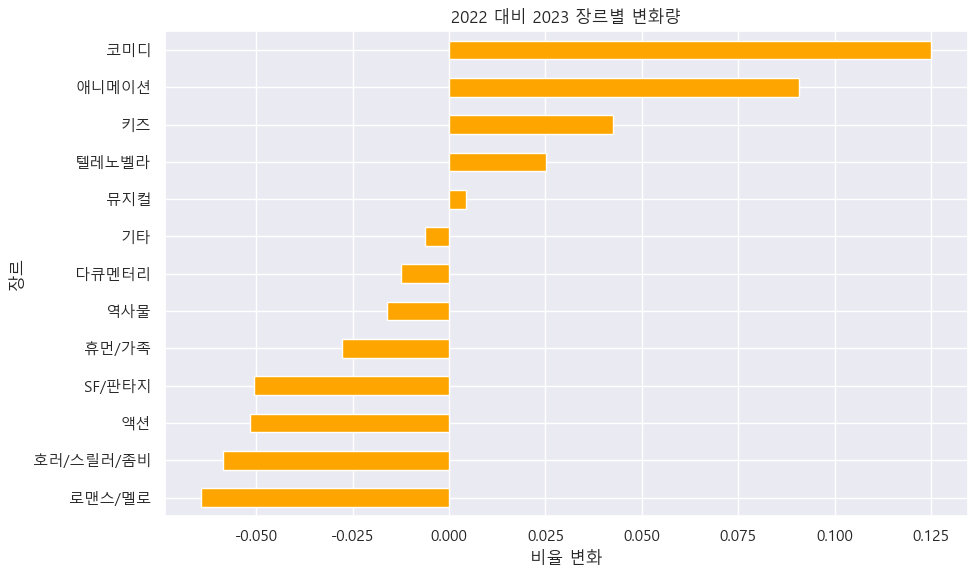

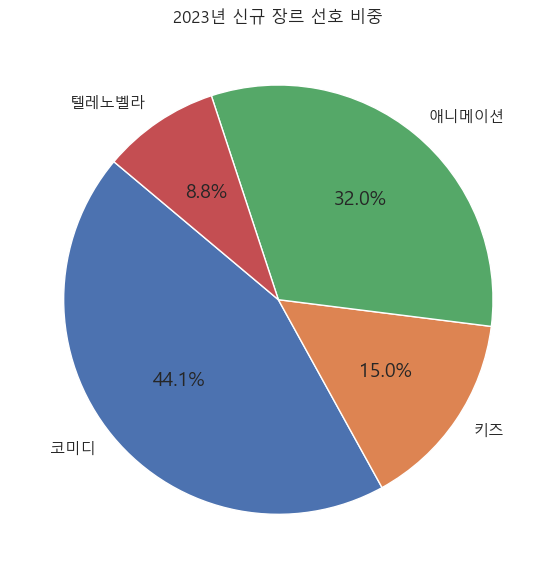

In [68]:
# 1. 라이브러리
import pandas as pd
import matplotlib.pyplot as plt

# 2. 한글 장르 매핑 (2022 컬럼명 -> 2023 형태로 바꿔서 매핑)
df_genre_2022["장르"] = df_genre_2022["장르코드"].str.replace("_2022", "_2023").map(col_to_kor)
df_genre_2023["장르"] = df_genre_2023["장르코드"].map(col_to_kor)

# 3. 응답값이 1인 장르만 필터링
df_genre_2022_used = df_genre_2022[df_genre_2022["선택"] == 1]
df_genre_2023_used = df_genre_2023[df_genre_2023["선택"] == 1]

# 4. 비율 계산
df_2022_pct = (
    df_genre_2022_used["장르"].value_counts(normalize=True)
    .sort_index()
    .rename("2022")
    .to_frame()
)

df_2023_pct = (
    df_genre_2023_used["장르"].value_counts(normalize=True)
    .sort_index()
    .rename("2023")
    .to_frame()
)

# 5. 병합 및 변화량 계산
df_compare = pd.merge(df_2022_pct, df_2023_pct, left_index=True, right_index=True, how="outer").fillna(0)
df_compare["변화량"] = df_compare["2023"] - df_compare["2022"]

# 6. 그룹형 막대그래프 (2022 vs 2023)
df_plot = df_compare[["2022", "2023"]].copy()
df_plot["장르"] = df_plot.index  # 인덱스를 컬럼으로
df_plot = df_plot.melt(id_vars="장르", var_name="연도", value_name="비율")
df_plot["연도"] = pd.Categorical(df_plot["연도"], categories=["2022", "2023"], ordered=True)
df_plot = df_plot.sort_values(by=["장르", "연도"])

plt.figure(figsize=(14, 6))
import seaborn as sns
sns.barplot(data=df_plot, x="장르", y="비율", hue="연도")
plt.title("2022 vs 2023 장르 선호 비교")
plt.xlabel("장르")
plt.ylabel("응답 비율")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. 증감 막대그래프
df_compare["변화량"].sort_values().plot(kind="barh", color="orange", figsize=(10, 6))
plt.title("2022 대비 2023 장르별 변화량")
plt.xlabel("비율 변화")
plt.ylabel("장르")
plt.tight_layout()
plt.show()

# 8. 2023년 신규 장르만 파이차트로 보기
new_genres = set(df_compare.index) - set(df_2022_pct.index)
if new_genres:
    df_new = df_compare.loc[list(new_genres)]
    plt.figure(figsize=(6, 6))
    plt.pie(df_new["2023"], labels=df_new.index, autopct="%1.1f%%", startangle=140)
    plt.title("2023년 신규 장르 선호 비중")
    plt.tight_layout()
    plt.show()


In [69]:
# 1. df_2023 재정의 (성별, 연령, 국가 포함)
cols_2023 = [col for col in df_contents.columns if col.endswith('_2023')]
df_2023 = df_contents[df_contents['user_id'].astype(str).str.startswith('2023')][['user_id', 'gender', 'age', 'nation'] + cols_2023]

# 2. 장르 컬럼만 추출
genre_cols_2023 = [col for col in df_2023.columns if col.startswith("genre_series_movie_") and col.endswith("_2023")]
col_to_kor = {
    "genre_series_movie_rom_2023": "로맨스/멜로",
    "genre_series_movie_fant_2023": "SF/판타지",
    "genre_series_movie_action_2023": "액션",
    "genre_series_movie_horr_2023": "호러/스릴러/좀비",
    "genre_series_movie_history_2023": "역사물",
    "genre_series_movie_human_2023": "휴먼/가족",
    "genre_series_movie_docu_2023": "다큐멘터리",
    "genre_series_movie_musical_2023": "뮤지컬",
    "genre_series_movie_comedy_2023": "코미디",
    "genre_series_movie_ani_2023": "애니메이션",
    "genre_series_movie_kids_2023": "키즈",
    "genre_series_movie_teleno_2023": "텔레노벨라",
    "genre_series_movie_etc_2023": "기타"
}

# 3. melt + 선택 == 1 필터링
df_genre_2023 = df_2023.melt(id_vars=["user_id", "gender", "age", "nation"], 
                             value_vars=genre_cols_2023,
                             var_name="장르코드", value_name="선택")

df_genre_2023_used = df_genre_2023[df_genre_2023["선택"] == 1].copy()
df_genre_2023_used["장르"] = df_genre_2023_used["장르코드"].map(col_to_kor)

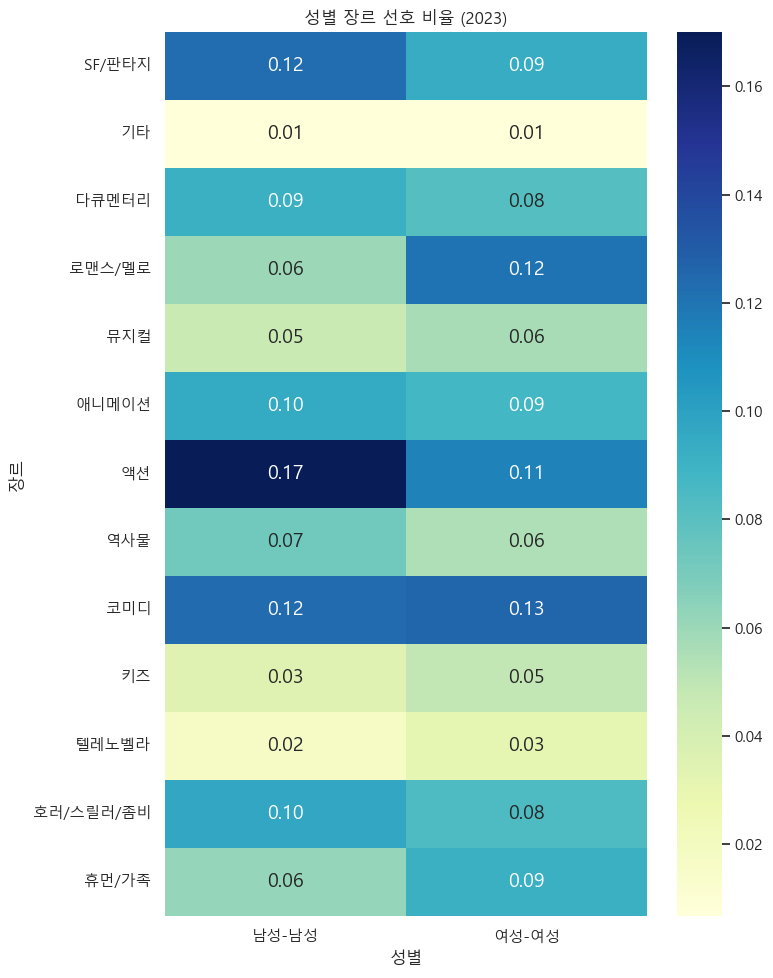

In [70]:
# 히트맵용 피벗 테이블 (장르가 index, 성별이 column)
gender_genre_t = (
    df_genre_2023_used.groupby(["gender", "장르"])
    .size()
    .groupby(level=0)
    .apply(lambda x: x / x.sum())  # 성별 내 비율
    .unstack()
).T  # 전치 (transpose)

# 히트맵 그리기 (가로형)
plt.figure(figsize=(8, 10))
sns.heatmap(gender_genre_t, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("성별 장르 선호 비율 (2023)")
plt.xlabel("성별")
plt.ylabel("장르")
plt.tight_layout()
plt.show()

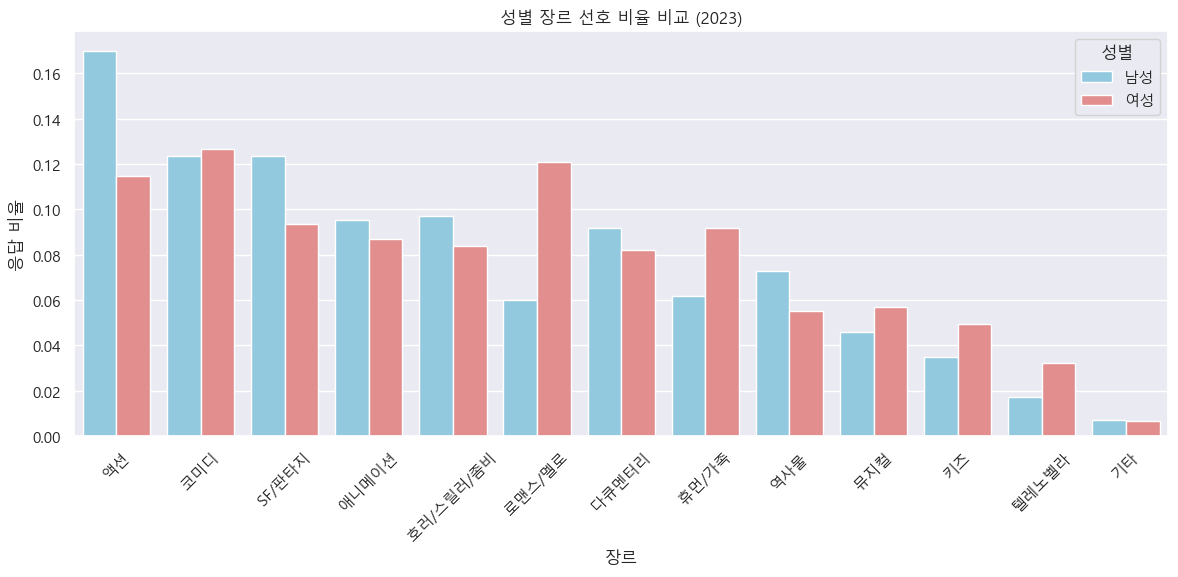

In [71]:
# 1. 성별-장르별 응답 수
gender_genre_counts = df_genre_2023_used.groupby(["gender", "장르"]).size().reset_index(name="count")

# 2. 성별 내 비율 계산
gender_totals = gender_genre_counts.groupby("gender")["count"].transform("sum")
gender_genre_counts["비율"] = gender_genre_counts["count"] / gender_totals

# ✅ 3. 정렬 기준 계산 (전체 성별 합 기준)
# 장르별 전체 응답 수 계산 → 높은 순서로 정렬
genre_order = (
    gender_genre_counts.groupby("장르")["비율"]
    .sum()
    .sort_values(ascending=False)
    .index
)

# 4. 시각화
plt.figure(figsize=(12, 6))
sns.barplot(
    data=gender_genre_counts,
    x="장르",
    y="비율",
    hue="gender",
    order=genre_order,  # ✅ 정렬된 장르 순서 반영
    palette={"남성": "skyblue", "여성": "lightcoral"}
)
plt.title("성별 장르 선호 비율 비교 (2023)")
plt.xlabel("장르")
plt.ylabel("응답 비율")
plt.xticks(rotation=45)
plt.legend(title="성별")
plt.tight_layout()
plt.show()

In [72]:
cols_2023 = [col for col in df_contents.columns if col.endswith("_2023")]
df_2023 = df_contents[df_contents['user_id'].astype(str).str.startswith('2023')][['user_id', 'nation', 'gender', 'age'] + cols_2023]

In [73]:
# 1. 필요한 컬럼 목록 정의
genre_cols_2023 = [col for col in df_2023.columns if col.startswith("genre_series_movie_") and col.endswith("_2023")]

# 2. 컬럼명 → 한글 장르 매핑
col_to_kor = {
    "genre_series_movie_rom_2023": "로맨스/멜로",
    "genre_series_movie_fant_2023": "SF/판타지",
    "genre_series_movie_action_2023": "액션",
    "genre_series_movie_horr_2023": "호러/스릴러/좀비",
    "genre_series_movie_history_2023": "역사물",
    "genre_series_movie_human_2023": "휴먼/가족",
    "genre_series_movie_docu_2023": "다큐멘터리",
    "genre_series_movie_musical_2023": "뮤지컬",
    "genre_series_movie_comedy_2023": "코미디",
    "genre_series_movie_ani_2023": "애니메이션",
    "genre_series_movie_kids_2023": "키즈",
    "genre_series_movie_teleno_2023": "텔레노벨라",
    "genre_series_movie_etc_2023": "기타"
}

In [74]:
# melt (국가 포함)
df_genre_nation = df_2023[["nation"] + genre_cols_2023].melt(
    id_vars="nation", var_name="장르코드", value_name="선택"
)

# 장르 선택한 사람만 필터링
df_genre_nation = df_genre_nation[df_genre_nation["선택"] == 1]
df_genre_nation["장르"] = df_genre_nation["장르코드"].map(col_to_kor)

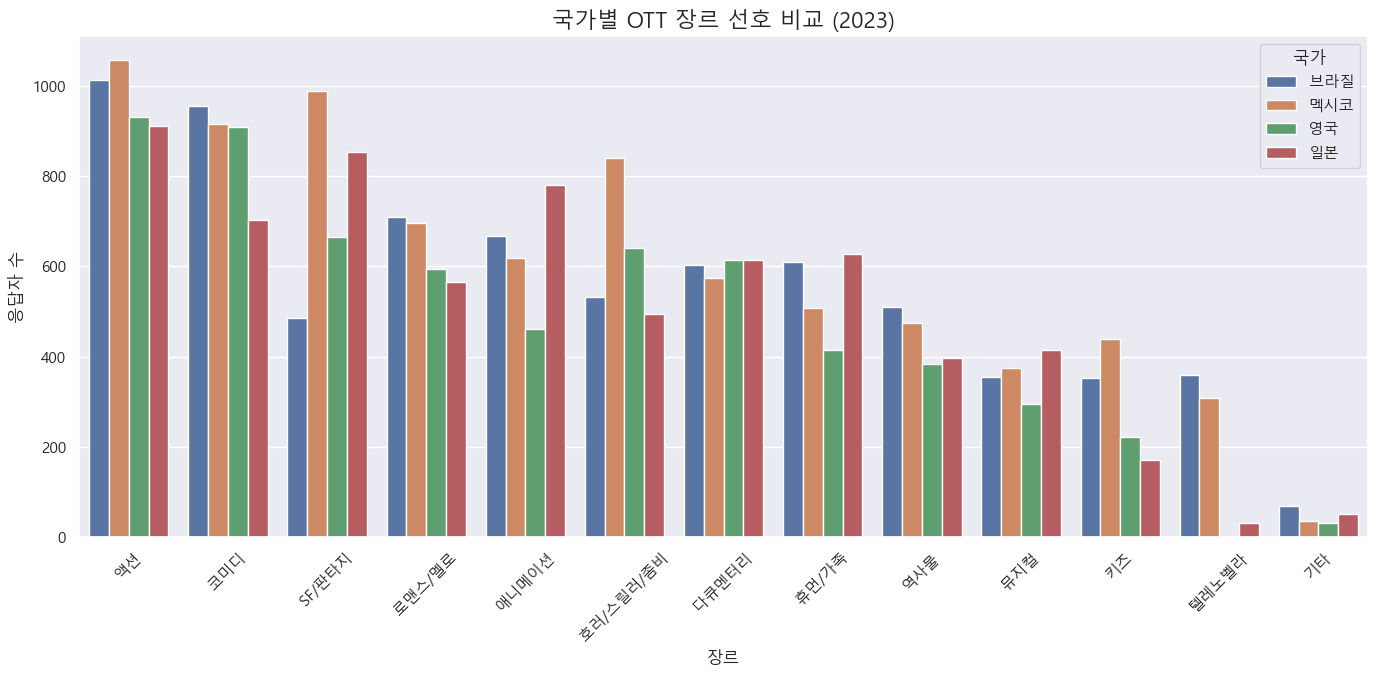

In [75]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))
sns.countplot(data=df_genre_nation, x="장르", hue="nation", order=df_genre_nation["장르"].value_counts().index)

plt.title("국가별 OTT 장르 선호 비교 (2023)", fontsize=16)
plt.xlabel("장르")
plt.ylabel("응답자 수")
plt.xticks(rotation=45)
plt.legend(title="국가")
plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_9840\270848271.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


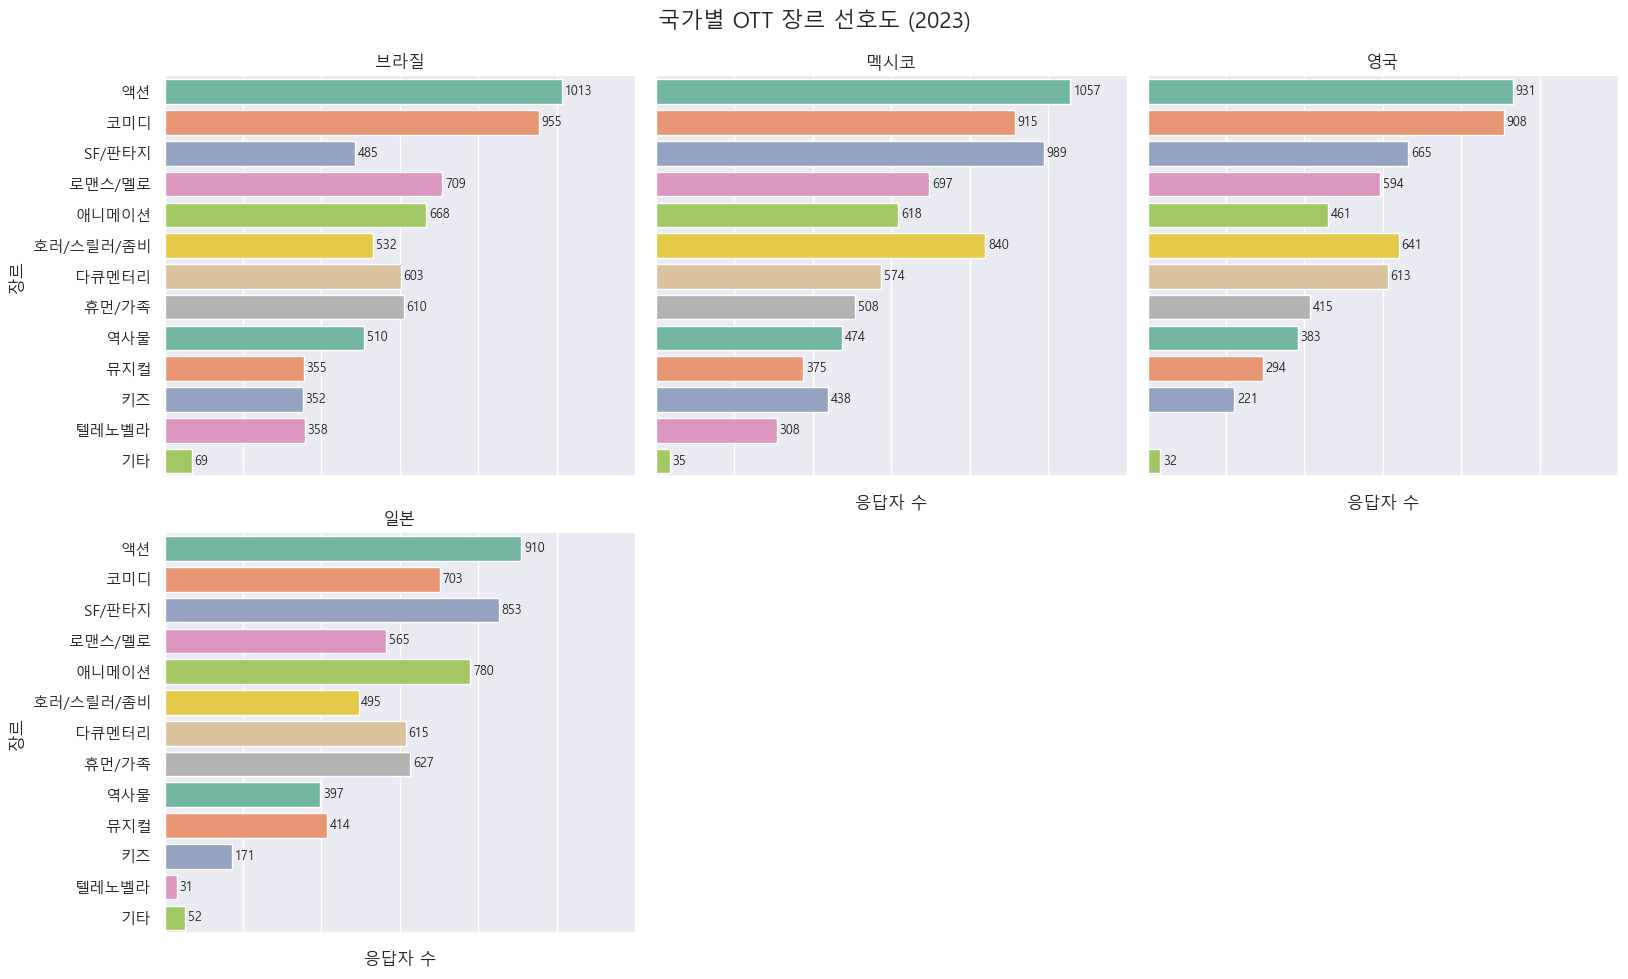

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt

# 장르 순서 고정
genre_order = df_genre_nation["장르"].value_counts().index.tolist()

# FacetGrid 국가별 장르 선호도
g = sns.catplot(
    data=df_genre_nation,
    y="장르",
    kind="count",
    col="nation",
    col_wrap=3,
    height=5,
    aspect=1.1,
    order=genre_order,
    palette="Set2"
)


# 스타일 지정
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45)
g.set_axis_labels("응답자 수", "장르")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("국가별 OTT 장르 선호도 (2023)", fontsize=16)

# 막대 위에 수치 표시 (응답 수)
for ax in g.axes.flatten():
    for container in ax.containers:
        ax.bar_label(container, label_type="edge", fontsize=9, padding=2)

plt.tight_layout()
plt.show()


C:\Users\User\AppData\Local\Temp\ipykernel_9840\3245816033.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


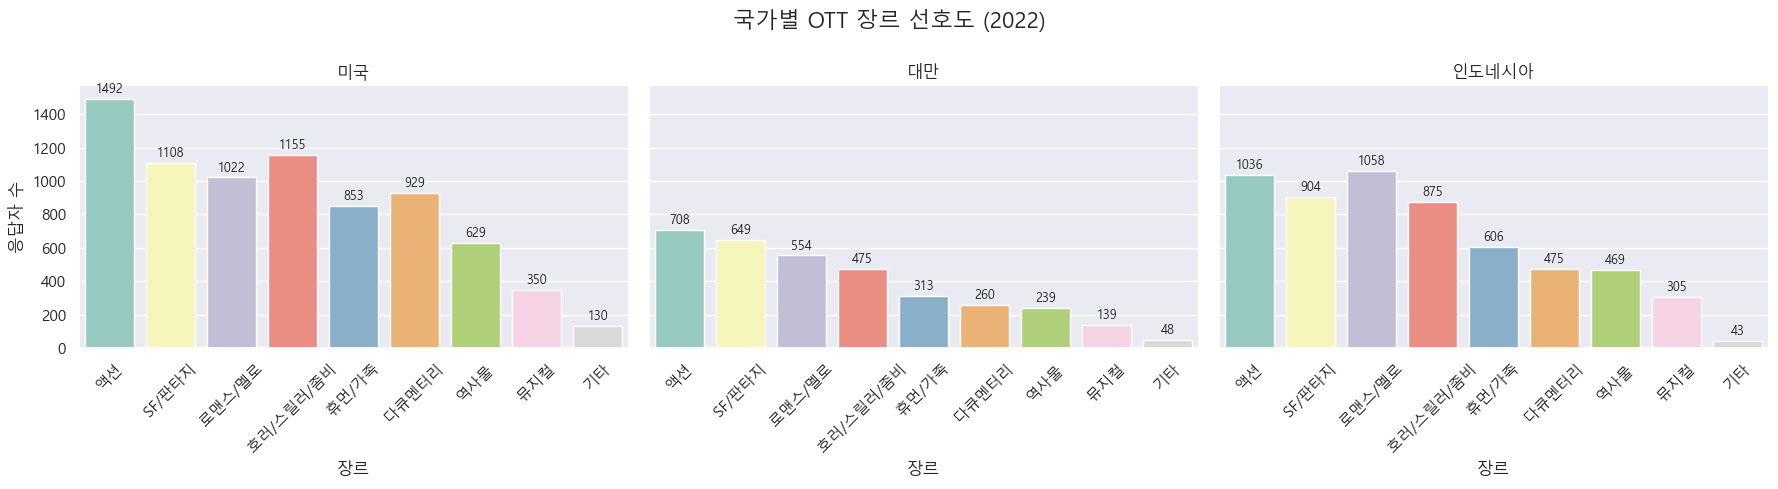

In [77]:
# 1. 장르 관련 컬럼 필터링
genre_cols_2022 = [col for col in df_2022.columns if col.startswith("genre_series_movie_") and col.endswith("_2022")]

# 2. 컬럼명 매핑 (한글)
col_to_kor_2022 = {
    "genre_series_movie_rom_2022": "로맨스/멜로",
    "genre_series_movie_fant_2022": "SF/판타지",
    "genre_series_movie_action_2022": "액션",
    "genre_series_movie_horr_2022": "호러/스릴러/좀비",
    "genre_series_movie_history_2022": "역사물",
    "genre_series_movie_human_2022": "휴먼/가족",
    "genre_series_movie_docu_2022": "다큐멘터리",
    "genre_series_movie_musical_2022": "뮤지컬",
    "genre_series_movie_etc_2022": "기타"
}

# 3. melt
df_genre_2022 = df_2022[["user_id", "nation", "gender", "age"] + genre_cols_2022].melt(
    id_vars=["user_id", "nation", "gender", "age"],
    value_vars=genre_cols_2022,
    var_name="장르코드",
    value_name="선택"
)

# 4. 응답값이 1인 경우만 필터링
df_genre_2022_used = df_genre_2022[df_genre_2022["선택"] == 1].copy()
df_genre_2022_used["장르"] = df_genre_2022_used["장르코드"].map(col_to_kor_2022)

# 5. 장르별 정렬 순서
genre_order_2022 = df_genre_2022_used["장르"].value_counts().index.tolist()

# 6. 국가별 장르 선호도 그래프
import seaborn as sns
import matplotlib.pyplot as plt

g = sns.catplot(
    data=df_genre_2022_used,
    x="장르",
    kind="count",
    col="nation",
    col_wrap=3,
    height=5,
    aspect=1.2,
    order=genre_order_2022,
    palette="Set3"
)

g.set_titles("{col_name}")
g.set_xticklabels(rotation=45)
g.set_axis_labels("장르", "응답자 수")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("국가별 OTT 장르 선호도 (2022)", fontsize=16)

# 수치 표시
for ax in g.axes.flatten():
    for container in ax.containers:
        ax.bar_label(container, label_type="edge", fontsize=9, padding=2)

plt.tight_layout()
plt.show()

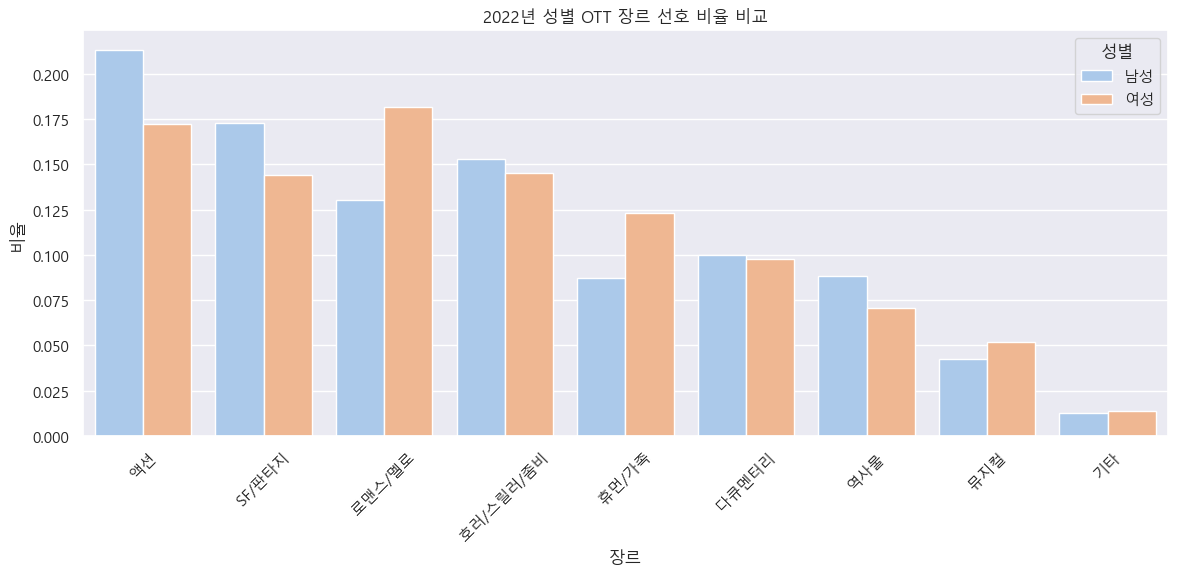

In [78]:
# 1. 성별별 장르 응답 비율 계산
temp = (
    df_genre_2022_used.groupby(["gender", "장르"])
    .size()
    .reset_index(name="count")
)

# 성별 내 비율 계산
total_by_gender = temp.groupby("gender")["count"].transform("sum")
temp["비율"] = temp["count"] / total_by_gender

# 2. 장르 순서 지정 (전체 기준)
genre_order_2022 = df_genre_2022_used["장르"].value_counts().index.tolist()
temp["장르"] = pd.Categorical(temp["장르"], categories=genre_order_2022, ordered=True)

# 3. 시각화
plt.figure(figsize=(12, 6))
sns.barplot(
    data=temp,
    x="장르",
    y="비율",
    hue="gender",
    order=genre_order_2022,
    palette="pastel"
)

plt.title("2022년 성별 OTT 장르 선호 비율 비교")
plt.xlabel("장르")
plt.ylabel("비율")
plt.xticks(rotation=45)
plt.legend(title="성별")
plt.tight_layout()
plt.show()



C:\Users\User\AppData\Local\Temp\ipykernel_9840\3939596291.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.assign(비율=x["size"] / x["size"].sum()))
C:\Users\User\AppData\Local\Temp\ipykernel_9840\3939596291.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


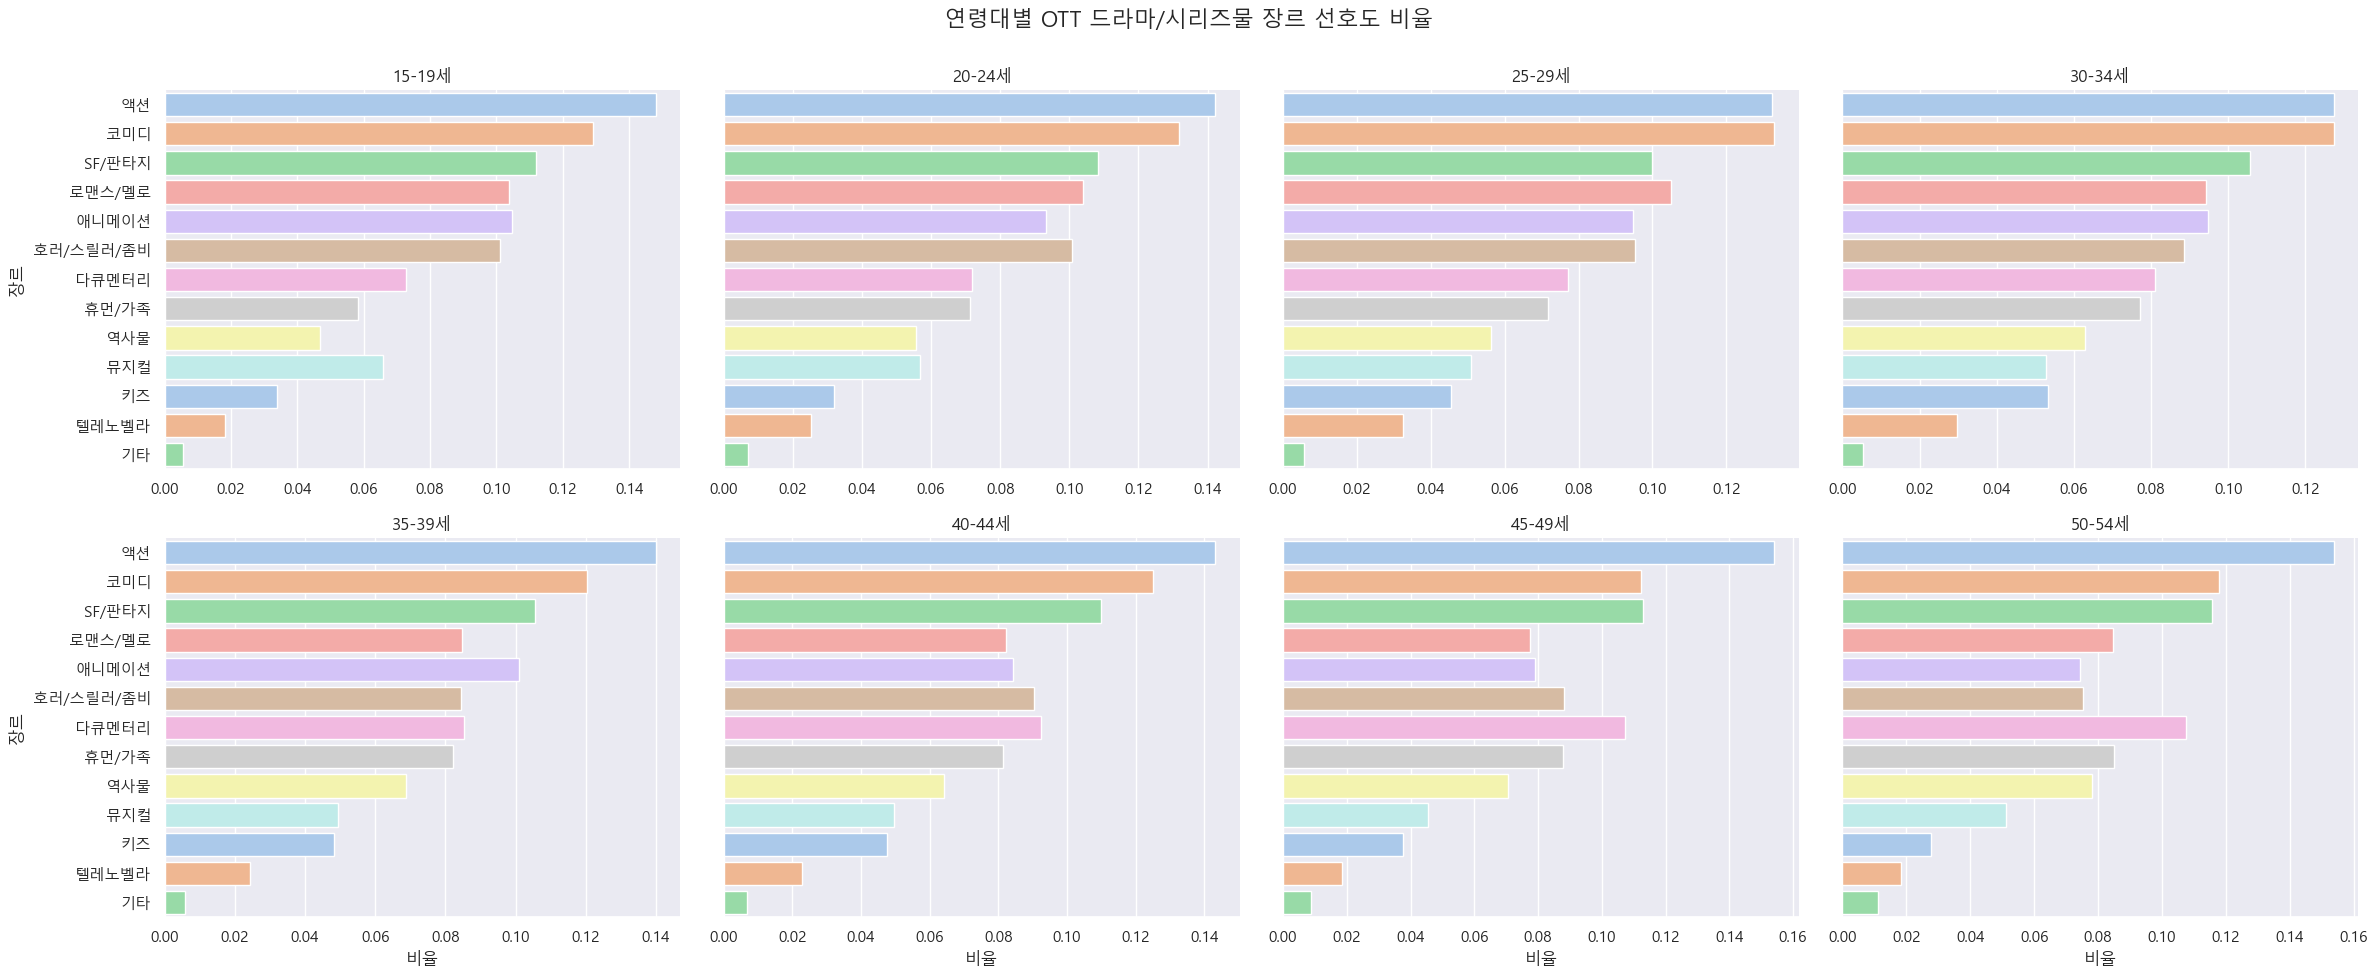

In [79]:

# 2. melt & 선택된 장르 필터링
df_genre = df_2023[["user_id", "age"] + genre_cols_2023].copy()
df_melt = df_genre.melt(id_vars=["user_id", "age"], var_name="장르코드", value_name="선택")
df_melt = df_melt[df_melt["선택"] == 1]
df_melt["장르"] = df_melt["장르코드"].map(col_to_kor)

# 3. 연령대별 장르 비율 계산
age_genre = (
    df_melt.groupby(["age", "장르"], as_index=False)
    .size()
    .groupby("age", as_index=False)
    .apply(lambda x: x.assign(비율=x["size"] / x["size"].sum()))
    .drop(columns="size")
)


# 4. 장르 순서 정렬 기준
genre_order = df_melt["장르"].value_counts().index.tolist()

# 5. 시각화 (Facet barplot)
g = sns.catplot(
    data=age_genre,
    x="비율",
    y="장르",
    col="age",
    kind="bar",
    col_wrap=4,
    sharex=False,
    order=genre_order,
    height=5,
    aspect=1.2,
    palette="pastel"
)
g.set_titles("{col_name}")
g.set_axis_labels("비율", "장르")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("연령대별 OTT 드라마/시리즈물 장르 선호도 비율", fontsize=16)
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_9840\2499920948.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.assign(비율=x["size"] / x["size"].sum()))
C:\Users\User\AppData\Local\Temp\ipykernel_9840\2499920948.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


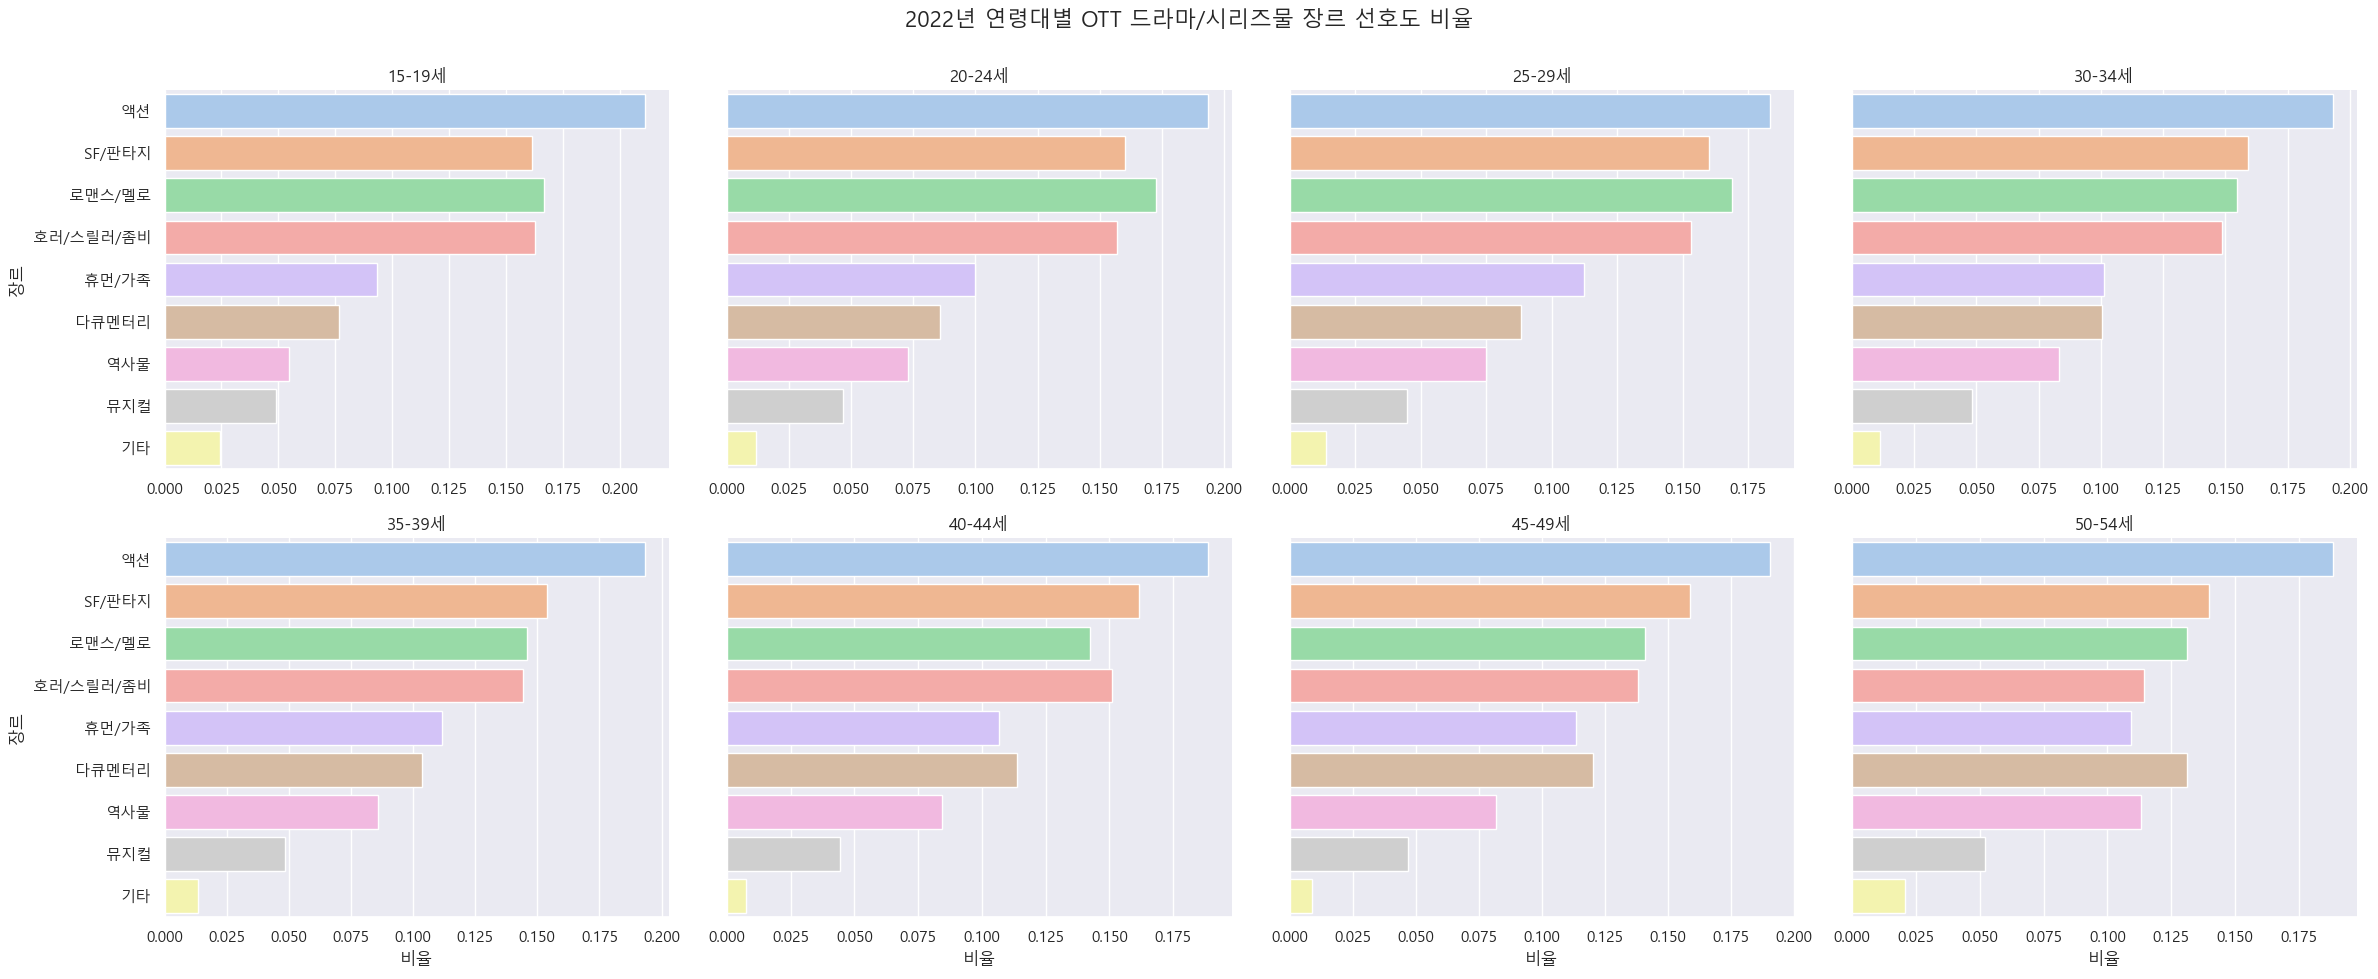

In [80]:
# 2. melt & 선택된 장르 필터링
df_genre_2022 = df_2022[["user_id", "age"] + genre_cols_2022].copy()
df_melt_2022 = df_genre_2022.melt(
    id_vars=["user_id", "age"], 
    var_name="장르코드", 
    value_name="선택"
)
df_melt_2022 = df_melt_2022[df_melt_2022["선택"] == 1]
df_melt_2022["장르"] = df_melt_2022["장르코드"].map(col_to_kor_2022)

# 3. 연령대별 장르 비율 계산
age_genre_2022 = (
    df_melt_2022.groupby(["age", "장르"], as_index=False)
    .size()
    .groupby("age", as_index=False)
    .apply(lambda x: x.assign(비율=x["size"] / x["size"].sum()))
    .drop(columns="size")
)

# 4. 장르 순서 정렬 기준
genre_order_2022 = df_melt_2022["장르"].value_counts().index.tolist()

# 5. 시각화 (Facet barplot)
import seaborn as sns
import matplotlib.pyplot as plt

g = sns.catplot(
    data=age_genre_2022,
    x="비율",
    y="장르",
    col="age",
    kind="bar",
    col_wrap=4,
    sharex=False,
    order=genre_order_2022,
    height=5,
    aspect=1.2,
    palette="pastel"
)
g.set_titles("{col_name}")
g.set_axis_labels("비율", "장르")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("2022년 연령대별 OTT 드라마/시리즈물 장르 선호도 비율", fontsize=16)
plt.show()



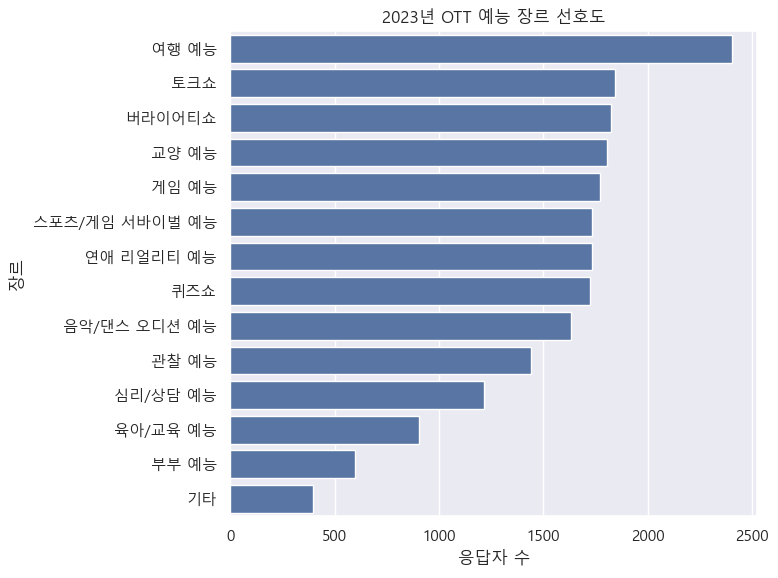

In [81]:
genre_cols_variety_2023 = [col for col in df_2023.columns if col.startswith("genre_variety_") and col.endswith("_2023")]

col_to_kor_variety_2023 = {
    "genre_variety_game_2023": "게임 예능",
    "genre_variety_travel_2023": "여행 예능",
    "genre_variety_observe_2023": "관찰 예능",
    "genre_variety_reality_2023": "연애 리얼리티 예능",
    "genre_variety_audition_2023": "음악/댄스 오디션 예능",
    "genre_variety_survival_2023": "스포츠/게임 서바이벌 예능",
    "genre_variety_culture_2023": "교양 예능",
    "genre_variety_etc_2023": "기타",
    "genre_variety_counsel_2023": "심리/상담 예능",
    "genre_variety_edu_2023": "육아/교육 예능",
    "genre_variety_talkshow_2023": "토크쇼",
    "genre_variety_quizshow_2023": "퀴즈쇼",
    "genre_variety_varshow_2023": "버라이어티쇼",
    "genre_variety_married_2023": "부부 예능"
}

df_variety_2023 = df_2023[genre_cols_variety_2023].melt(var_name="장르코드", value_name="선택")
df_variety_2023 = df_variety_2023[df_variety_2023["선택"] == 1]
df_variety_2023["장르"] = df_variety_2023["장르코드"].map(col_to_kor_variety_2023)

plt.figure(figsize=(8, 6))
sns.countplot(data=df_variety_2023, y="장르", order=df_variety_2023["장르"].value_counts().index)
plt.title("2023년 OTT 예능 장르 선호도")
plt.xlabel("응답자 수")
plt.ylabel("장르")
plt.tight_layout()
plt.show()

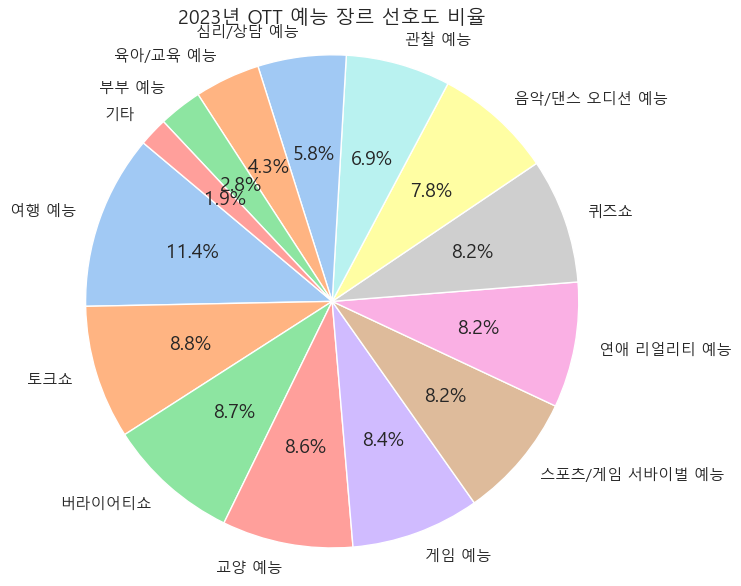

In [82]:
# 2. melt & 필터링
df_variety_2023 = df_2023[genre_cols_variety_2023].copy()
df_melt_2023 = df_variety_2023.melt(var_name="장르코드", value_name="선택")
df_melt_2023 = df_melt_2023[df_melt_2023["선택"] == 1]
df_melt_2023["장르"] = df_melt_2023["장르코드"].map(col_to_kor_variety_2023)

# 3. 비율 계산
genre_counts_2023 = df_melt_2023["장르"].value_counts(normalize=True)

# 4. 원그래프
plt.figure(figsize=(7, 7))
plt.pie(
    genre_counts_2023.values,
    labels=genre_counts_2023.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("pastel")
)
plt.title("2023년 OTT 예능 장르 선호도 비율", fontsize=14)
plt.axis("equal")
plt.show()

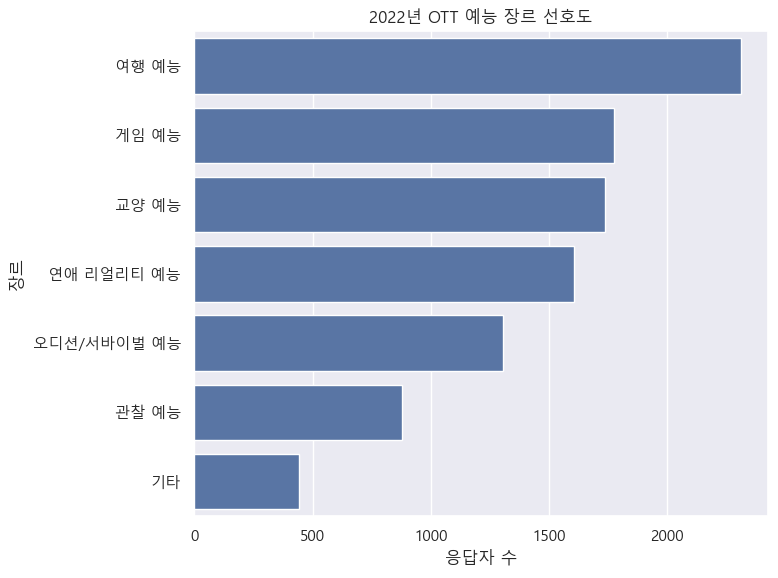

In [83]:
genre_cols_variety_2022 = [col for col in df_2022.columns if col.startswith("genre_variety_") and col.endswith("_2022")]

col_to_kor_variety_2022 = {
    "genre_variety_game_2022": "게임 예능",
    "genre_variety_travel_2022": "여행 예능",
    "genre_variety_observe_2022": "관찰 예능",
    "genre_variety_reality_2022": "연애 리얼리티 예능",
    "genre_variety_survival_2022": "오디션/서바이벌 예능",
    "genre_variety_culture_2022": "교양 예능",
    "genre_variety_etc_2022": "기타"
}

df_variety_2022 = df_2022[genre_cols_variety_2022].melt(var_name="장르코드", value_name="선택")
df_variety_2022 = df_variety_2022[df_variety_2022["선택"] == 1]
df_variety_2022["장르"] = df_variety_2022["장르코드"].map(col_to_kor_variety_2022)

plt.figure(figsize=(8, 6))
sns.countplot(data=df_variety_2022, y="장르", order=df_variety_2022["장르"].value_counts().index)
plt.title("2022년 OTT 예능 장르 선호도")
plt.xlabel("응답자 수")
plt.ylabel("장르")
plt.tight_layout()
plt.show()

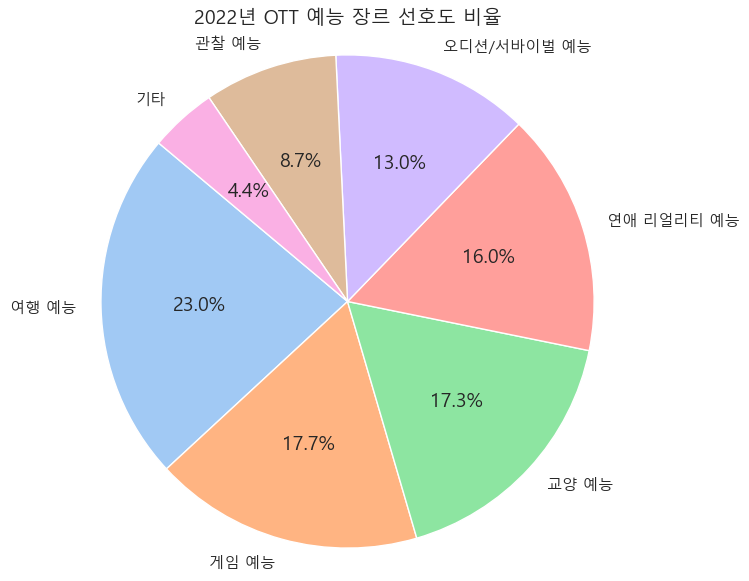

In [84]:
# 2. melt & 필터링
df_variety_2022 = df_2022[genre_cols_variety_2022].copy()
df_melt_2022 = df_variety_2022.melt(var_name="장르코드", value_name="선택")
df_melt_2022 = df_melt_2022[df_melt_2022["선택"] == 1]
df_melt_2022["장르"] = df_melt_2022["장르코드"].map(col_to_kor_variety_2022)

# 3. 비율 계산
genre_counts_2022 = df_melt_2022["장르"].value_counts(normalize=True)

# 4. 원그래프
plt.figure(figsize=(7, 7))
plt.pie(
    genre_counts_2022.values,
    labels=genre_counts_2022.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("pastel")
)
plt.title("2022년 OTT 예능 장르 선호도 비율", fontsize=14)
plt.axis("equal")
plt.show()

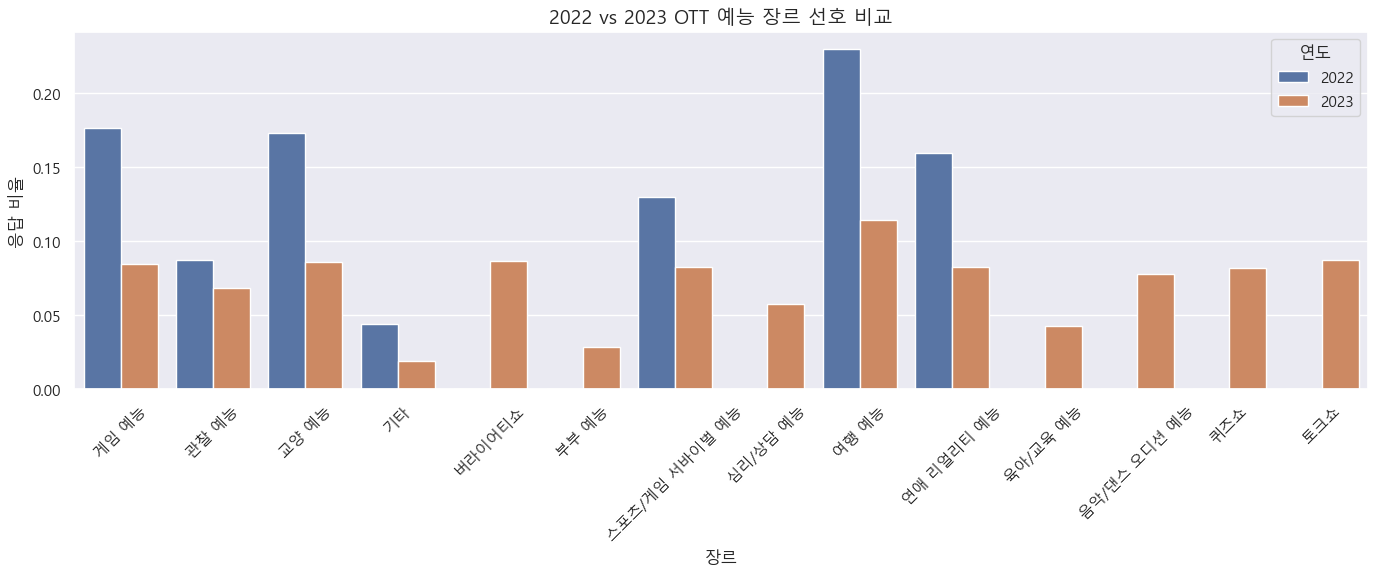

In [85]:
# 1. 예능 장르 매핑 딕셔너리 (2023 기준으로 통일)
col_to_kor_variety = {
    "genre_variety_game_2023": "게임 예능",
    "genre_variety_travel_2023": "여행 예능",
    "genre_variety_observe_2023": "관찰 예능",
    "genre_variety_reality_2023": "연애 리얼리티 예능",
    "genre_variety_audition_2023": "음악/댄스 오디션 예능",
    "genre_variety_survival_2023": "스포츠/게임 서바이벌 예능",
    "genre_variety_culture_2023": "교양 예능",
    "genre_variety_counsel_2023": "심리/상담 예능",
    "genre_variety_edu_2023": "육아/교육 예능",
    "genre_variety_talkshow_2023": "토크쇼",
    "genre_variety_quizshow_2023": "퀴즈쇼",
    "genre_variety_varshow_2023": "버라이어티쇼",
    "genre_variety_married_2023": "부부 예능",
    "genre_variety_etc_2023": "기타"
}

# 2. melt
genre_cols_variety_2022 = [col for col in df_2022.columns if col.startswith("genre_variety_") and col.endswith("_2022")]
genre_cols_variety_2023 = [col for col in df_2023.columns if col.startswith("genre_variety_") and col.endswith("_2023")]

df_variety_2022 = df_2022[["user_id"] + genre_cols_variety_2022].copy()
df_variety_2023 = df_2023[["user_id"] + genre_cols_variety_2023].copy()

df_melt_2022 = df_variety_2022.melt(id_vars=["user_id"], var_name="장르코드", value_name="선택")
df_melt_2023 = df_variety_2023.melt(id_vars=["user_id"], var_name="장르코드", value_name="선택")

# 3. 컬럼명 통일 및 한글 매핑
df_melt_2022["장르코드_표준"] = df_melt_2022["장르코드"].str.replace("_2022", "_2023")
df_melt_2023["장르코드_표준"] = df_melt_2023["장르코드"]
df_melt_2022["장르"] = df_melt_2022["장르코드_표준"].map(col_to_kor_variety)
df_melt_2023["장르"] = df_melt_2023["장르코드_표준"].map(col_to_kor_variety)

# 4. 필터링
df_used_2022 = df_melt_2022[df_melt_2022["선택"] == 1]
df_used_2023 = df_melt_2023[df_melt_2023["선택"] == 1]

# 5. 비율 계산
df_2022_pct = (
    df_used_2022["장르"].value_counts(normalize=True)
    .sort_index()
    .rename("2022")
    .to_frame()
)
df_2023_pct = (
    df_used_2023["장르"].value_counts(normalize=True)
    .sort_index()
    .rename("2023")
    .to_frame()
)

# 6. 병합 및 변화량 계산
df_compare = pd.merge(df_2022_pct, df_2023_pct, left_index=True, right_index=True, how="outer").fillna(0)
df_compare["변화량"] = df_compare["2023"] - df_compare["2022"]

# 7. 시각화용 long-form 변환
df_plot = df_compare[["2022", "2023"]].copy()
df_plot["장르"] = df_plot.index
df_plot = df_plot.melt(id_vars="장르", var_name="연도", value_name="비율")
df_plot["연도"] = pd.Categorical(df_plot["연도"], categories=["2022", "2023"], ordered=True)
df_plot = df_plot.sort_values(by=["장르", "연도"])

# 8. 시각화
plt.figure(figsize=(14, 6))
sns.barplot(data=df_plot, x="장르", y="비율", hue="연도")
plt.title("2022 vs 2023 OTT 예능 장르 선호 비교", fontsize=14)
plt.xlabel("장르")
plt.ylabel("응답 비율")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_9840\34718485.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


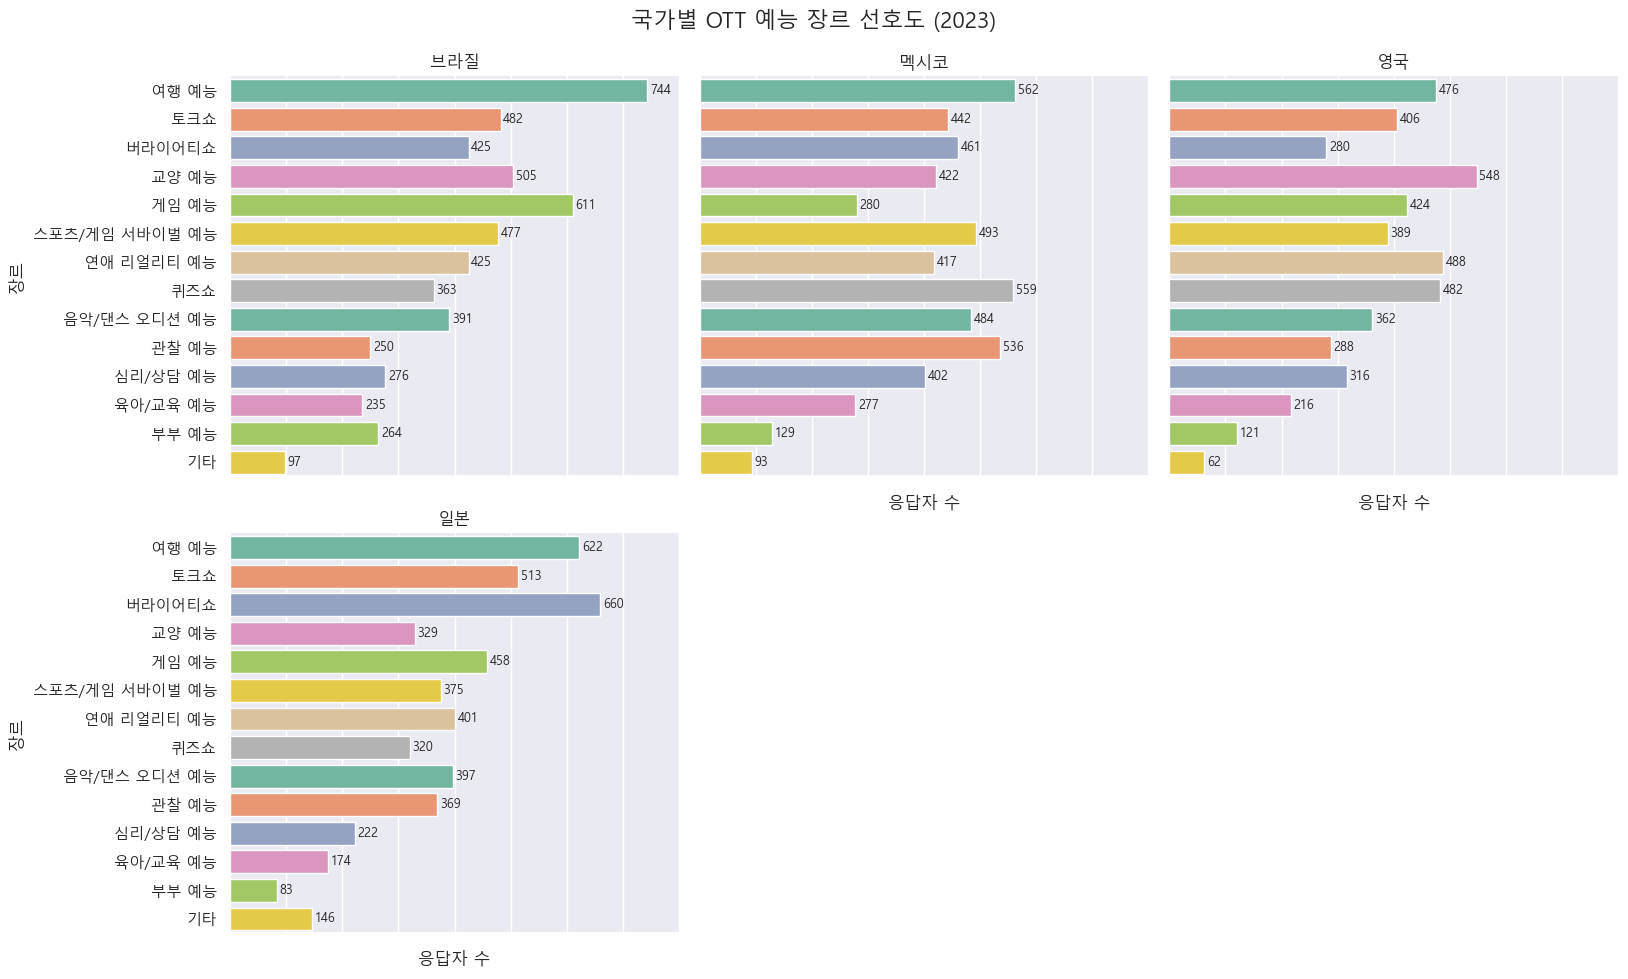

In [86]:
# 1. 예능 장르 컬럼 필터링 (2023 기준)
genre_cols_variety_2023 = [col for col in df_2023.columns if col.startswith("genre_variety_") and col.endswith("_2023")]

# 2. melt 및 장르 매핑
df_variety = df_2023[["user_id", "nation"] + genre_cols_variety_2023].copy()
df_melt_variety = df_variety.melt(id_vars=["user_id", "nation"], var_name="장르코드", value_name="선택")
df_melt_variety = df_melt_variety[df_melt_variety["선택"] == 1]
df_melt_variety["장르"] = df_melt_variety["장르코드"].map(col_to_kor_variety)

# 3. 장르 순서 고정
genre_order = df_melt_variety["장르"].value_counts().index.tolist()

# 4. 시각화
g = sns.catplot(
    data=df_melt_variety,
    y="장르",
    kind="count",
    col="nation",
    col_wrap=3,
    height=5,
    aspect=1.1,
    order=genre_order,
    palette="Set2"
)

g.set_titles("{col_name}")
g.set_xticklabels(rotation=45)
g.set_axis_labels("응답자 수", "장르")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("국가별 OTT 예능 장르 선호도 (2023)", fontsize=16)

# 막대 위에 수치 표시
for ax in g.axes.flatten():
    for container in ax.containers:
        ax.bar_label(container, label_type="edge", fontsize=9, padding=2)

plt.tight_layout()
plt.show()

In [87]:
# 2022 예능 장르 매핑
col_to_kor_variety_2022 = {
    "genre_variety_game_2022": "게임 예능",
    "genre_variety_travel_2022": "여행 예능",
    "genre_variety_observe_2022": "관찰 예능",
    "genre_variety_reality_2022": "연애 리얼리티 예능",
    "genre_variety_survival_2022": "오디션/서바이벌 예능",
    "genre_variety_culture_2022": "교양 예능",
    "genre_variety_etc_2022": "기타"
}

# 2023 예능 장르 매핑
col_to_kor_variety_2023 = {
    "genre_variety_game_2023": "게임 예능",
    "genre_variety_travel_2023": "여행 예능",
    "genre_variety_observe_2023": "관찰 예능",
    "genre_variety_reality_2023": "연애 리얼리티 예능",
    "genre_variety_audition_2023": "음악/댄스 오디션 예능",
    "genre_variety_survival_2023": "오디션/서바이벌 예능",
    "genre_variety_culture_2023": "교양 예능",
    "genre_variety_etc_2023": "기타",
    "genre_variety_counsel_2023": "심리/상담 예능",
    "genre_variety_edu_2023": "육아/교육 예능",
    "genre_variety_talkshow_2023": "토크쇼",
    "genre_variety_quizshow_2023": "퀴즈쇼",
    "genre_variety_varshow_2023": "버라이어티쇼",
    "genre_variety_married_2023": "부부 예능"
}

C:\Users\User\AppData\Local\Temp\ipykernel_9840\416788580.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


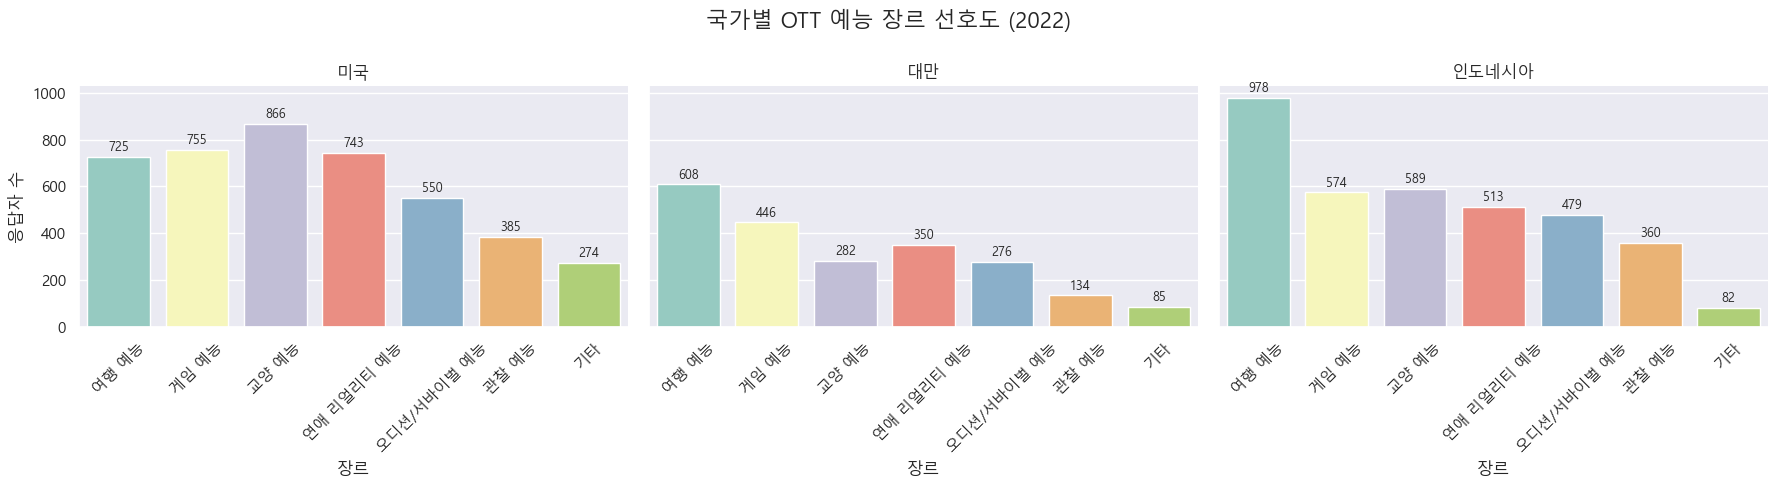

In [88]:
# 1. 예능 장르 컬럼 필터링 (2022 기준)
genre_cols_variety_2022 = [col for col in df_2022.columns if col.startswith("genre_variety_") and col.endswith("_2022")]

# 3. melt
df_variety_2022 = df_2022[["user_id", "nation", "gender", "age"] + genre_cols_variety_2022].melt(
    id_vars=["user_id", "nation", "gender", "age"],
    value_vars=genre_cols_variety_2022,
    var_name="장르코드",
    value_name="선택"
)

# 4. 응답값이 1인 경우만 필터링
df_variety_2022_used = df_variety_2022[df_variety_2022["선택"] == 1].copy()
df_variety_2022_used["장르"] = df_variety_2022_used["장르코드"].map(col_to_kor_variety_2022)

# 5. 장르별 정렬 순서
genre_order_variety_2022 = df_variety_2022_used["장르"].value_counts().index.tolist()

# 6. 시각화: 국가별 선호도
import seaborn as sns
import matplotlib.pyplot as plt

g = sns.catplot(
    data=df_variety_2022_used,
    x="장르",
    kind="count",
    col="nation",
    col_wrap=3,
    height=5,
    aspect=1.2,
    order=genre_order_variety_2022,
    palette="Set3"
)

g.set_titles("{col_name}")
g.set_xticklabels(rotation=45)
g.set_axis_labels("장르", "응답자 수")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("국가별 OTT 예능 장르 선호도 (2022)", fontsize=16)

# 수치 표시
for ax in g.axes.flatten():
    for container in ax.containers:
        ax.bar_label(container, label_type="edge", fontsize=9, padding=2)

plt.tight_layout()
plt.show()


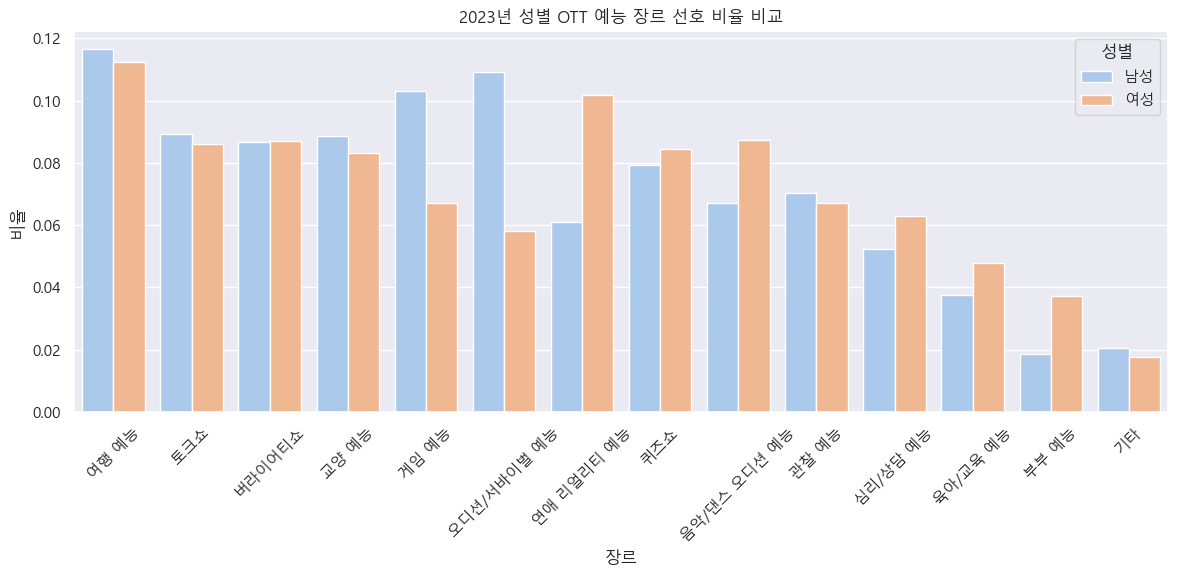

In [89]:

# 3. melt & 응답=1 필터
df_variety_2023 = df_2023[["user_id", "gender"] + genre_cols_variety_2023].melt(
    id_vars=["user_id", "gender"],
    value_vars=genre_cols_variety_2023,
    var_name="장르코드",
    value_name="선택"
)
df_variety_2023_used = df_variety_2023[df_variety_2023["선택"] == 1].copy()
df_variety_2023_used["장르"] = df_variety_2023_used["장르코드"].map(col_to_kor_variety_2023)

# 4. 응답 비율 계산
temp_2023 = (
    df_variety_2023_used.groupby(["gender", "장르"])
    .size()
    .reset_index(name="count")
)
total_by_gender = temp_2023.groupby("gender")["count"].transform("sum")
temp_2023["비율"] = temp_2023["count"] / total_by_gender

# 5. 장르 순서
genre_order_2023 = df_variety_2023_used["장르"].value_counts().index.tolist()
temp_2023["장르"] = pd.Categorical(temp_2023["장르"], categories=genre_order_2023, ordered=True)

# 6. 시각화
plt.figure(figsize=(12, 6))
sns.barplot(
    data=temp_2023,
    x="장르",
    y="비율",
    hue="gender",
    order=genre_order_2023,
    palette="pastel"
)
plt.title("2023년 성별 OTT 예능 장르 선호 비율 비교")
plt.xlabel("장르")
plt.ylabel("비율")
plt.xticks(rotation=45)
plt.legend(title="성별")
plt.tight_layout()
plt.show()


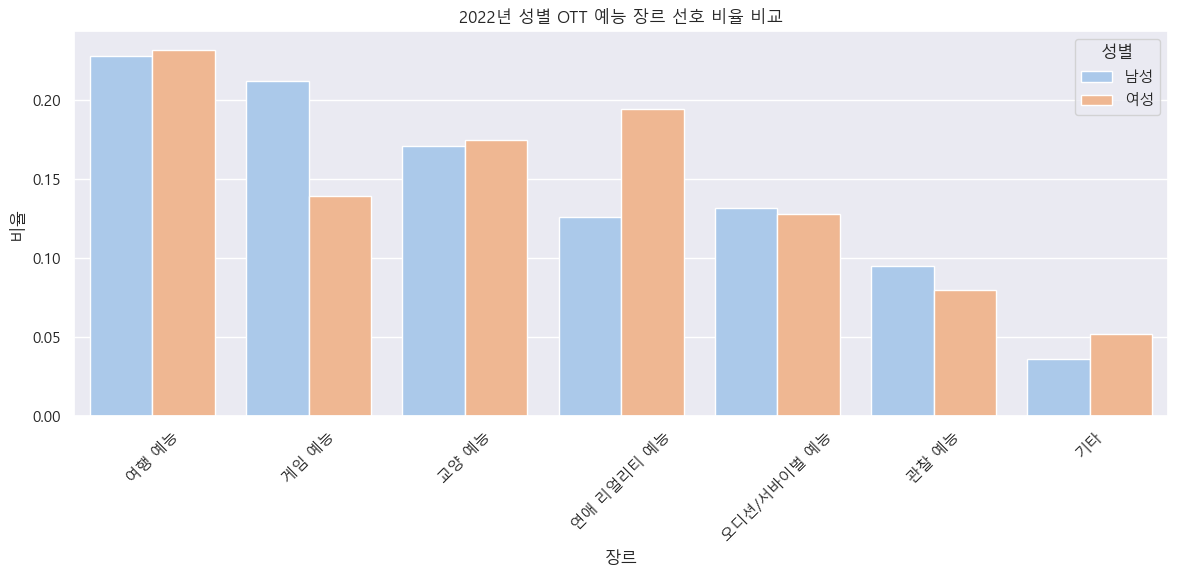

In [90]:
# 3. melt & 응답=1 필터
df_variety_2022 = df_2022[["user_id", "gender"] + genre_cols_variety_2022].melt(
    id_vars=["user_id", "gender"],
    value_vars=genre_cols_variety_2022,
    var_name="장르코드",
    value_name="선택"
)
df_variety_2022_used = df_variety_2022[df_variety_2022["선택"] == 1].copy()
df_variety_2022_used["장르"] = df_variety_2022_used["장르코드"].map(col_to_kor_variety_2022)

# 4. 응답 비율 계산
temp_2022 = (
    df_variety_2022_used.groupby(["gender", "장르"])
    .size()
    .reset_index(name="count")
)
total_by_gender = temp_2022.groupby("gender")["count"].transform("sum")
temp_2022["비율"] = temp_2022["count"] / total_by_gender

# 5. 장르 순서
genre_order_2022 = df_variety_2022_used["장르"].value_counts().index.tolist()
temp_2022["장르"] = pd.Categorical(temp_2022["장르"], categories=genre_order_2022, ordered=True)

# 6. 시각화
plt.figure(figsize=(12, 6))
sns.barplot(
    data=temp_2022,
    x="장르",
    y="비율",
    hue="gender",
    order=genre_order_2022,
    palette="pastel"
)
plt.title("2022년 성별 OTT 예능 장르 선호 비율 비교")
plt.xlabel("장르")
plt.ylabel("비율")
plt.xticks(rotation=45)
plt.legend(title="성별")
plt.tight_layout()
plt.show()


In [91]:
# 1-1. 예능 장르 컬럼 목록
genre_cols_2022 = [col for col in df_2022.columns if col.startswith("genre_variety_") and col.endswith("_2022")]
genre_cols_2023 = [col for col in df_2023.columns if col.startswith("genre_variety_") and col.endswith("_2023")]

# 1-2. 장르 코드 → 장르명 매핑
col_to_kor_variety_2022 = {
    "genre_variety_game_2022": "게임 예능",
    "genre_variety_travel_2022": "여행 예능",
    "genre_variety_observe_2022": "관찰 예능",
    "genre_variety_reality_2022": "연애 리얼리티 예능",
    "genre_variety_survival_2022": "오디션/서바이벌 예능",
    "genre_variety_culture_2022": "교양 예능",
    "genre_variety_etc_2022": "기타"
}

col_to_kor_variety_2023 = {
    "genre_variety_game_2023": "게임 예능",
    "genre_variety_travel_2023": "여행 예능",
    "genre_variety_observe_2023": "관찰 예능",
    "genre_variety_reality_2023": "연애 리얼리티 예능",
    "genre_variety_audition_2023": "음악/댄스 오디션 예능",
    "genre_variety_survival_2023": "오디션/서바이벌 예능",
    "genre_variety_culture_2023": "교양 예능",
    "genre_variety_etc_2023": "기타",
    "genre_variety_counsel_2023": "심리/상담 예능",
    "genre_variety_edu_2023": "육아/교육 예능",
    "genre_variety_talkshow_2023": "토크쇼",
    "genre_variety_quizshow_2023": "퀴즈쇼",
    "genre_variety_varshow_2023": "버라이어티쇼",
    "genre_variety_married_2023": "부부 예능"
}

C:\Users\User\AppData\Local\Temp\ipykernel_9840\417621870.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.assign(비율=x["size"] / x["size"].sum()))
C:\Users\User\AppData\Local\Temp\ipykernel_9840\417621870.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


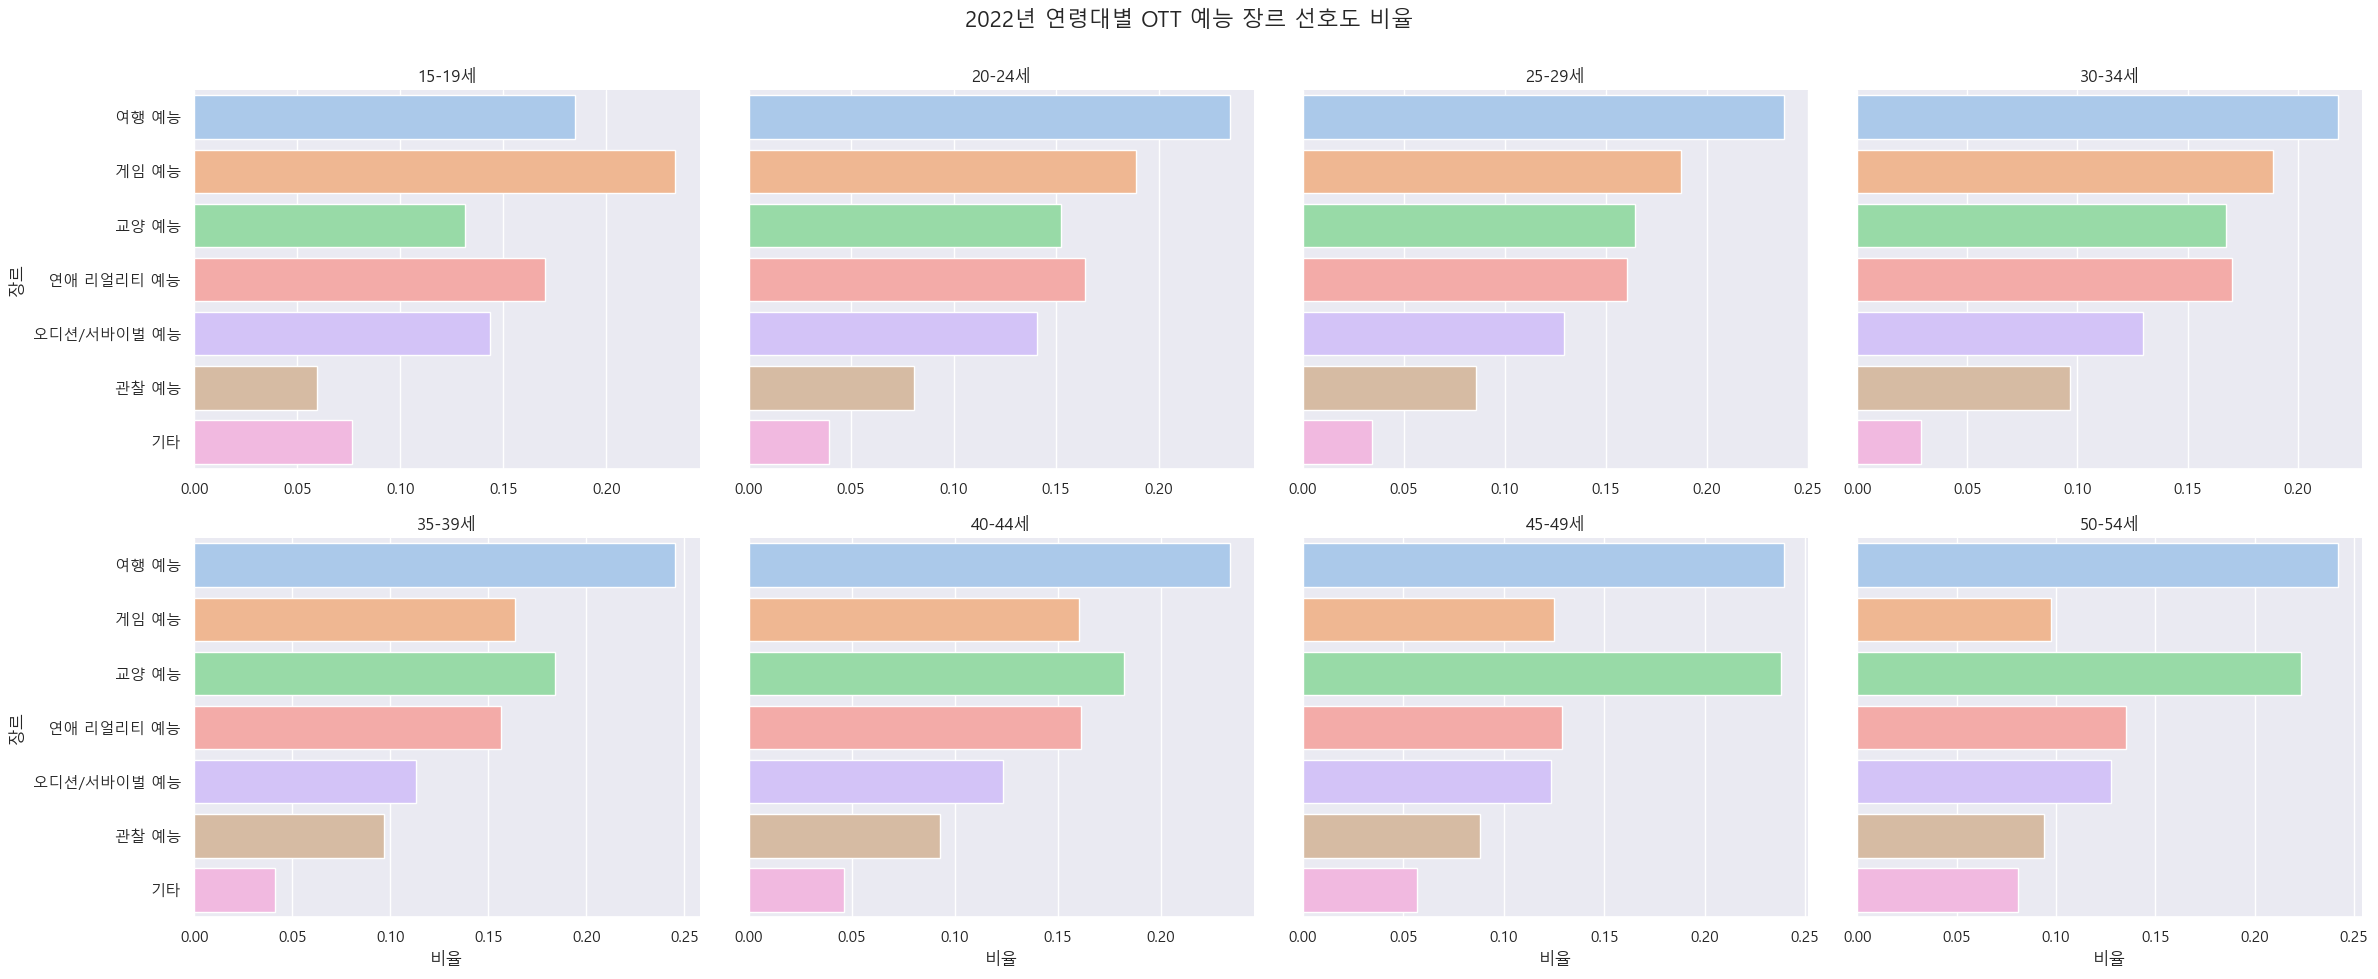

In [92]:
df_genre_2022 = df_2022[["user_id", "age"] + genre_cols_2022].copy()
df_melt_2022 = df_genre_2022.melt(id_vars=["user_id", "age"], var_name="장르코드", value_name="선택")
df_melt_2022 = df_melt_2022[df_melt_2022["선택"] == 1]
df_melt_2022["장르"] = df_melt_2022["장르코드"].map(col_to_kor_variety_2022)

age_genre_2022 = (
    df_melt_2022.groupby(["age", "장르"], as_index=False)
    .size()
    .groupby("age", as_index=False)
    .apply(lambda x: x.assign(비율=x["size"] / x["size"].sum()))
    .drop(columns="size")
)

genre_order_2022 = df_melt_2022["장르"].value_counts().index.tolist()

import seaborn as sns
import matplotlib.pyplot as plt

g = sns.catplot(
    data=age_genre_2022,
    x="비율",
    y="장르",
    col="age",
    kind="bar",
    col_wrap=4,
    sharex=False,
    order=genre_order_2022,
    height=5,
    aspect=1.2,
    palette="pastel"
)
g.set_titles("{col_name}")
g.set_axis_labels("비율", "장르")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("2022년 연령대별 OTT 예능 장르 선호도 비율", fontsize=16)
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_9840\137556989.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.assign(비율=x["size"] / x["size"].sum()))
C:\Users\User\AppData\Local\Temp\ipykernel_9840\137556989.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


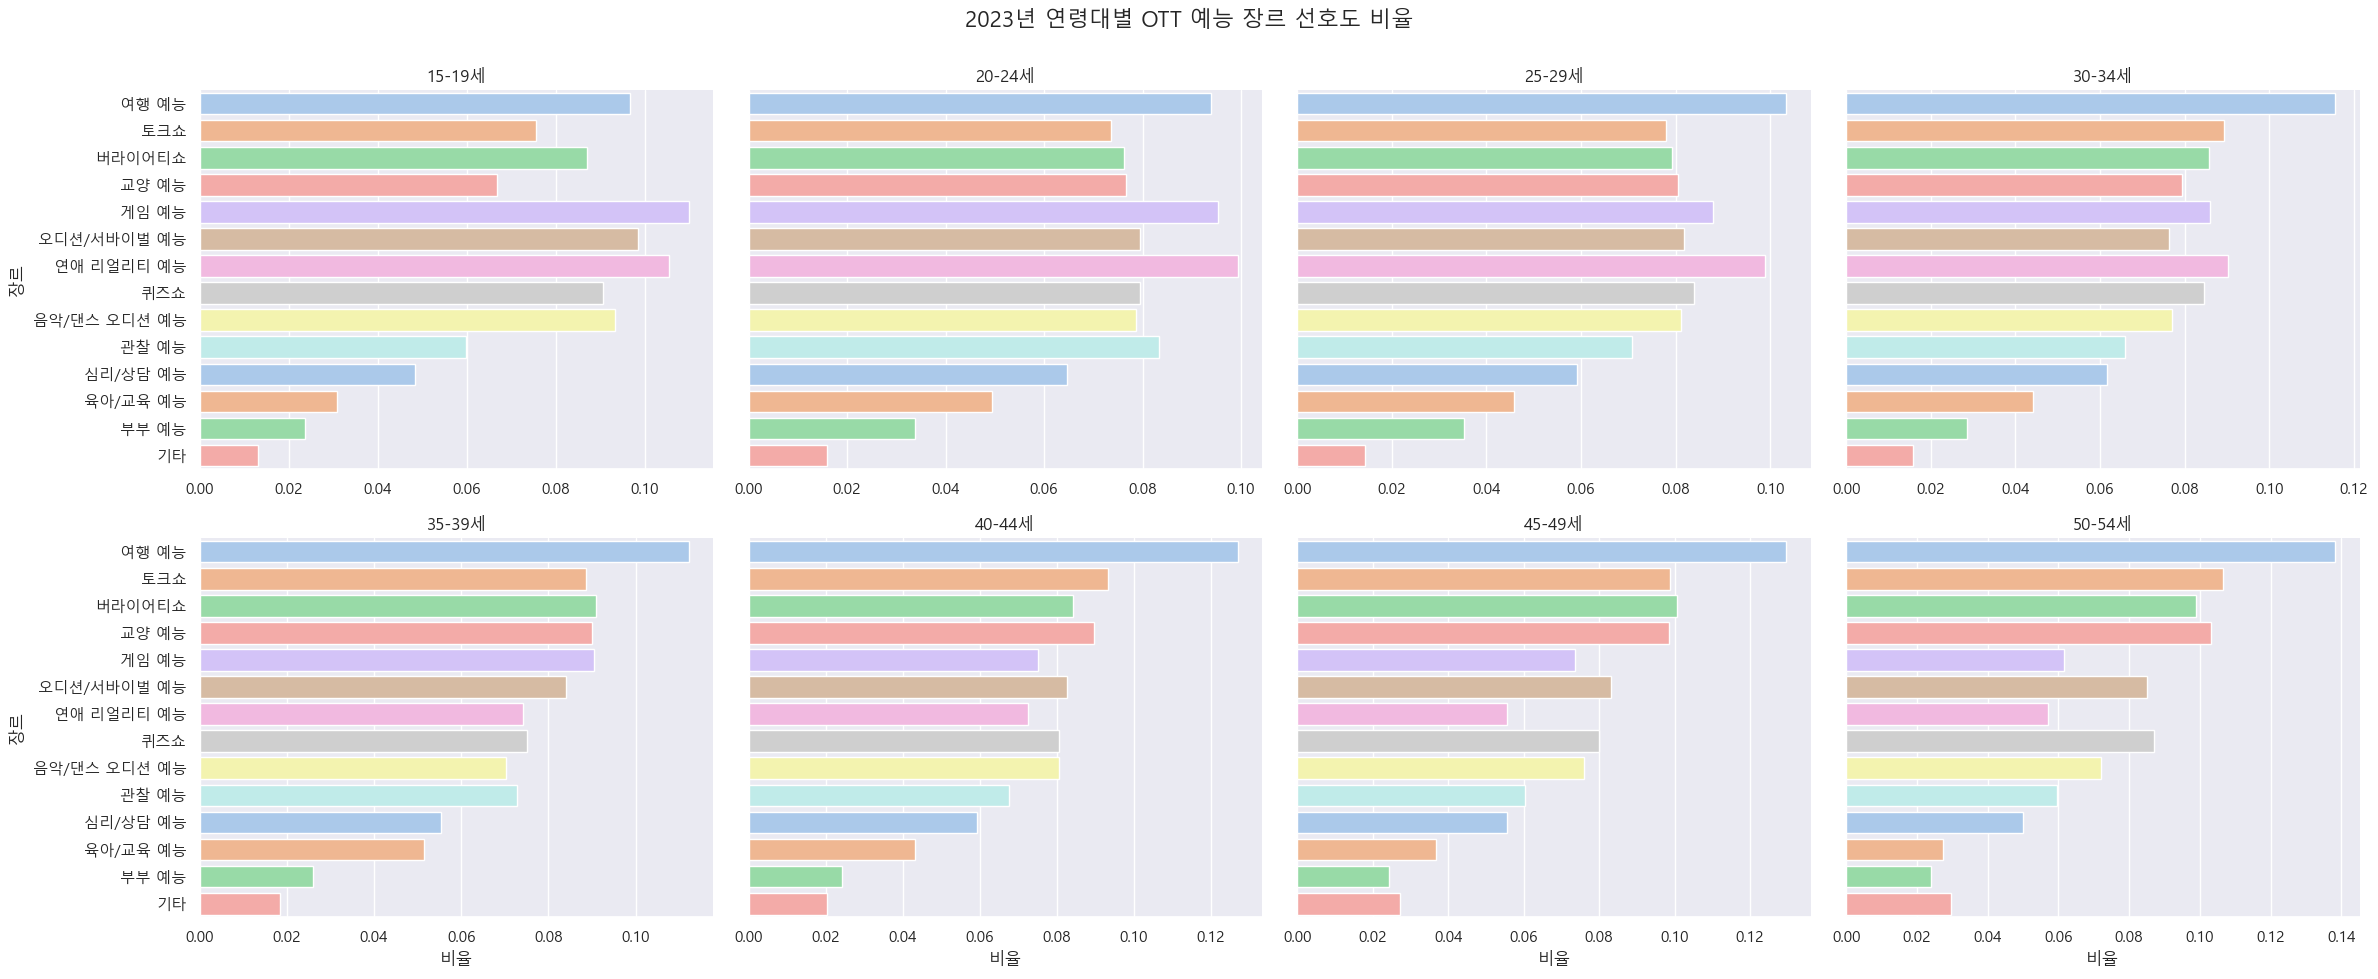

In [93]:
df_genre_2023 = df_2023[["user_id", "age"] + genre_cols_2023].copy()
df_melt_2023 = df_genre_2023.melt(id_vars=["user_id", "age"], var_name="장르코드", value_name="선택")
df_melt_2023 = df_melt_2023[df_melt_2023["선택"] == 1]
df_melt_2023["장르"] = df_melt_2023["장르코드"].map(col_to_kor_variety_2023)

age_genre_2023 = (
    df_melt_2023.groupby(["age", "장르"], as_index=False)
    .size()
    .groupby("age", as_index=False)
    .apply(lambda x: x.assign(비율=x["size"] / x["size"].sum()))
    .drop(columns="size")
)

genre_order_2023 = df_melt_2023["장르"].value_counts().index.tolist()

g = sns.catplot(
    data=age_genre_2023,
    x="비율",
    y="장르",
    col="age",
    kind="bar",
    col_wrap=4,
    sharex=False,
    order=genre_order_2023,
    height=5,
    aspect=1.2,
    palette="pastel"
)
g.set_titles("{col_name}")
g.set_axis_labels("비율", "장르")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("2023년 연령대별 OTT 예능 장르 선호도 비율", fontsize=16)
plt.show()

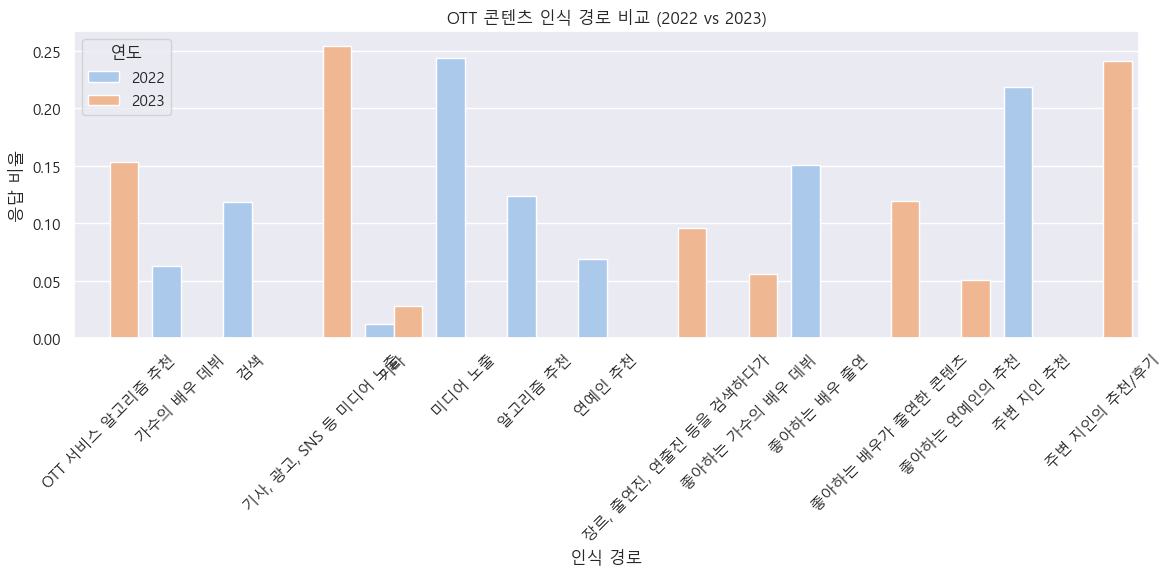

In [94]:
# ---------------------
# 1. 컬럼명-한글 매핑
col_to_kor_2022 = {
    "recog_route_recom_2022": "주변 지인 추천",
    "recog_route_media_2022": "미디어 노출",
    "recog_route_fav_actor_2022": "좋아하는 배우 출연",
    "recog_route_fav_singer_2022": "가수의 배우 데뷔",
    "recog_route_celeb_recom_2022": "연예인 추천",
    "recog_route_algorithm_2022": "알고리즘 추천",
    "recog_route_search_2022": "검색",
    "recog_route_etc_2022": "기타"
}

# ---------------------
# 2. 2022 데이터: melt & count
route_cols_2022 = list(col_to_kor_2022.keys())
df_2022_route = df_2022[route_cols_2022].copy()
df_melt_2022 = df_2022_route.melt(var_name="코드", value_name="응답")
df_melt_2022 = df_melt_2022[df_melt_2022["응답"] == 1]
df_melt_2022["인식 경로"] = df_melt_2022["코드"].map(col_to_kor_2022)

route_count_2022 = df_melt_2022["인식 경로"].value_counts(normalize=True).sort_values(ascending=False)

# ---------------------
# 3. 2023 데이터: 문자열 분해 & count
df_melt_2023 = df_2023[["recog_route_2023"]].dropna().copy()
df_melt_2023["인식 경로"] = df_melt_2023["recog_route_2023"].str.split("\n")
df_melt_2023 = df_melt_2023.explode("인식 경로")
route_count_2023 = df_melt_2023["인식 경로"].value_counts(normalize=True).sort_values(ascending=False)

# ---------------------
# 4. 병합 시각화용
df_route_compare = pd.DataFrame({
    "2022": route_count_2022,
    "2023": route_count_2023
}).fillna(0)

df_route_plot = df_route_compare.reset_index(names="인식 경로").melt(id_vars="인식 경로", var_name="연도", value_name="비율")

# ---------------------
# 5. 시각화
plt.figure(figsize=(12, 6))
sns.barplot(data=df_route_plot, x="인식 경로", y="비율", hue="연도", palette="pastel")
plt.title("OTT 콘텐츠 인식 경로 비교 (2022 vs 2023)")
plt.ylabel("응답 비율")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


C:\Users\User\AppData\Local\Temp\ipykernel_9840\163022178.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=route_pct_2022, y="인식 경로", x="비율", palette="pastel")


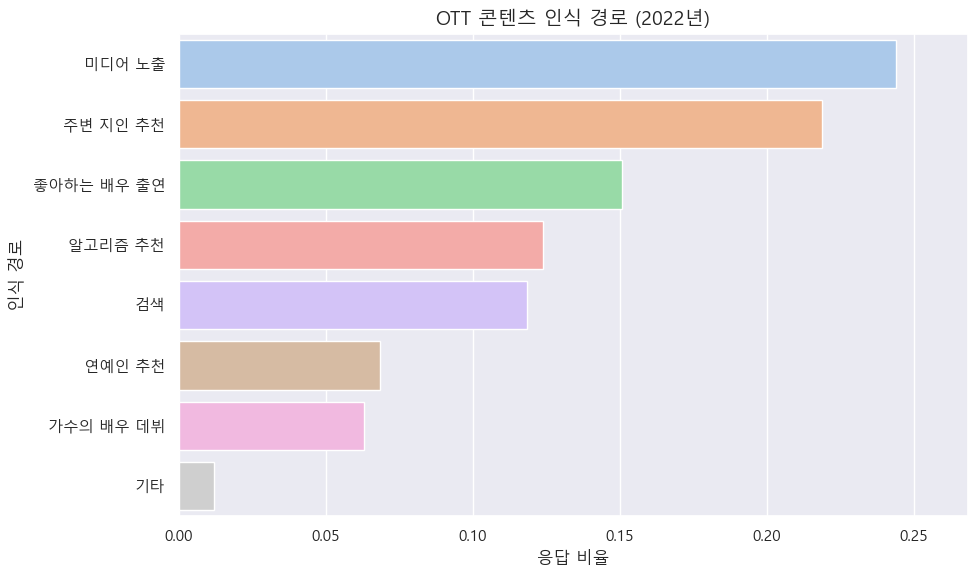

In [95]:
# 2022 비율 계산
route_pct_2022 = (
    df_melt_2022["인식 경로"]
    .value_counts(normalize=True)
    .sort_values(ascending=False)
    .rename_axis("인식 경로")
    .reset_index(name="비율")
)

# 시각화
plt.figure(figsize=(10, 6))
sns.barplot(data=route_pct_2022, y="인식 경로", x="비율", palette="pastel")
plt.title("OTT 콘텐츠 인식 경로 (2022년)", fontsize=14)
plt.xlabel("응답 비율")
plt.ylabel("인식 경로")
plt.xlim(0, route_pct_2022["비율"].max() * 1.1)
plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_9840\2512912441.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=route_pct, y="인식 경로", x="비율", palette="pastel")


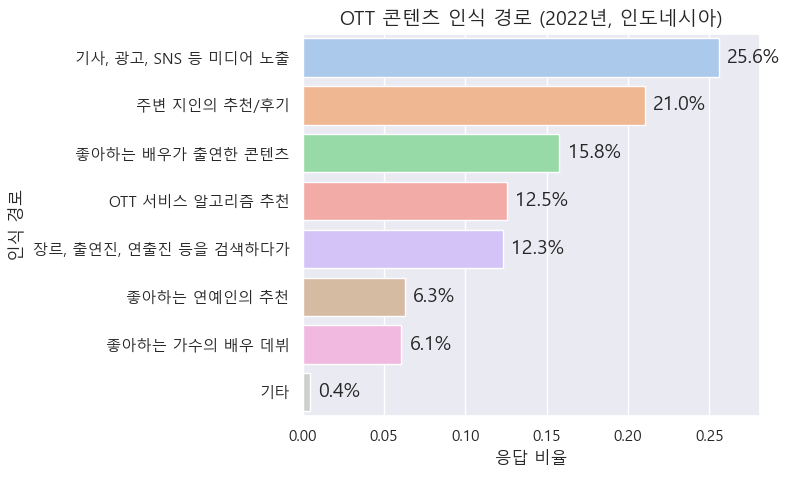

C:\Users\User\AppData\Local\Temp\ipykernel_9840\2512912441.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=route_pct, y="인식 경로", x="비율", palette="pastel")


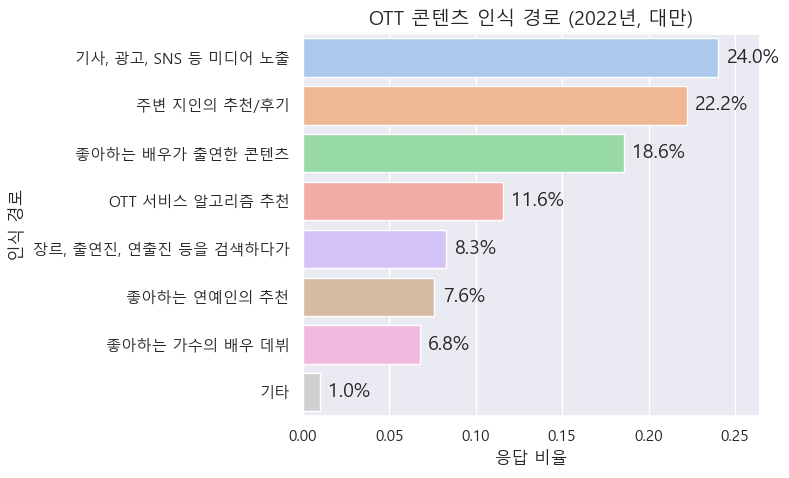

C:\Users\User\AppData\Local\Temp\ipykernel_9840\2512912441.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=route_pct, y="인식 경로", x="비율", palette="pastel")


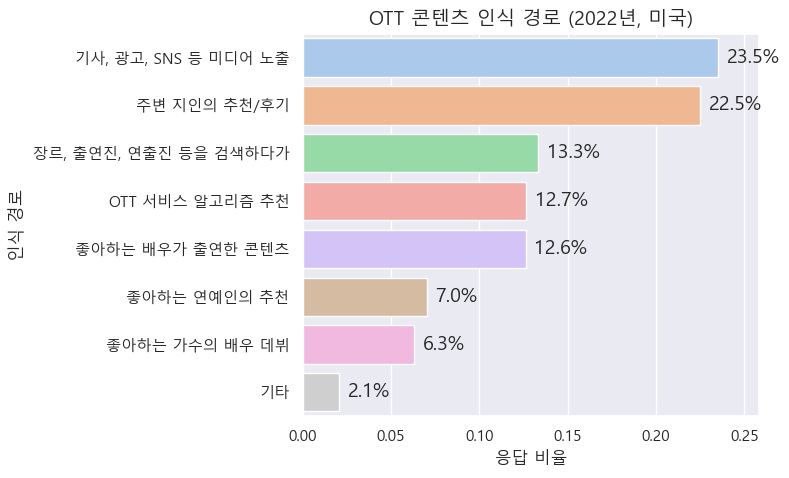

In [115]:
# --------------------------
# 특정 국가별 인식 경로 비율 그래프 함수
# --------------------------
def plot_route_ratio_by_nation(df_melt, nation_name):
    # 특정 국가 데이터만 필터링
    nation_df = df_melt[df_melt['nation'] == nation_name]

    # 비율 계산
    route_pct = (
        nation_df["인식 경로"]
        .value_counts(normalize=True)
        .sort_values(ascending=False)
        .rename_axis("인식 경로")
        .reset_index(name="비율")
    )

    # 시각화
    plt.figure(figsize=(8, 5))
    sns.barplot(data=route_pct, y="인식 경로", x="비율", palette="pastel")
    plt.title(f"OTT 콘텐츠 인식 경로 (2022년, {nation_name})", fontsize=14)
    plt.xlabel("응답 비율")
    plt.ylabel("인식 경로")
    plt.xlim(0, route_pct["비율"].max() * 1.1)

    # 수치 표시
    for i, v in enumerate(route_pct["비율"]):
        plt.text(v + 0.005, i, f"{v:.1%}", va='center')

    plt.tight_layout()
    plt.show()

# --------------------------
# 그래프 출력
# --------------------------
for nation in ["인도네시아", "대만", "미국"]:
    plot_route_ratio_by_nation(df_melt_2022, nation)


C:\Users\User\AppData\Local\Temp\ipykernel_9840\1243333469.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=route_pct_2022_sel, y="인식 경로", x="비율", palette="pastel")


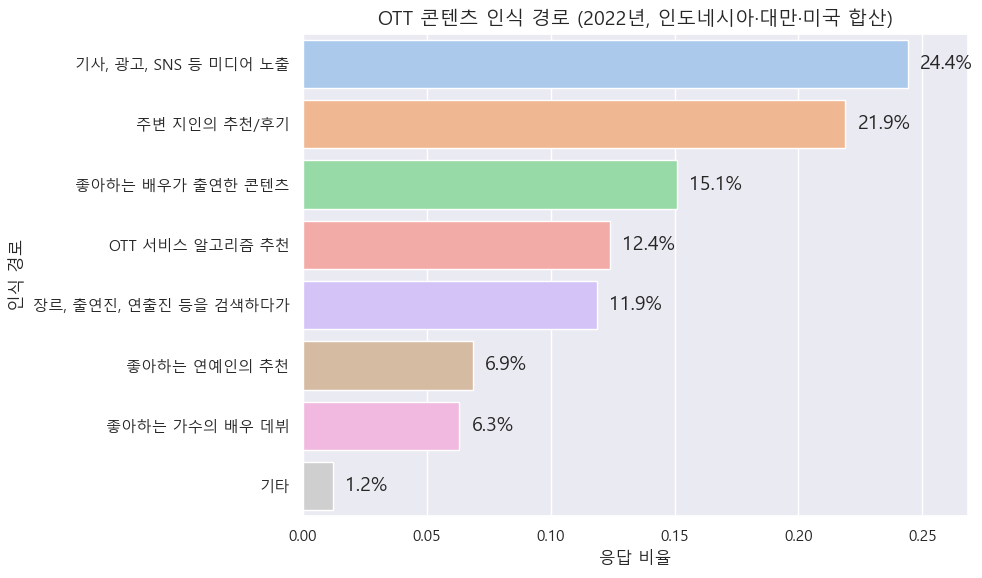

=== 2022년 인도네시아·대만·미국 합산 인식 경로 비율 ===
                   인식 경로  비율(%)
0   기사, 광고, SNS 등 미디어 노출   24.4
1           주변 지인의 추천/후기   21.9
2       좋아하는 배우가 출연한 콘텐츠   15.1
3        OTT 서비스 알고리즘 추천   12.4
4  장르, 출연진, 연출진 등을 검색하다가   11.9
5           좋아하는 연예인의 추천    6.9
6         좋아하는 가수의 배우 데뷔    6.3
7                     기타    1.2


In [116]:
# --------------------------
# 세 나라만 필터링 (인도네시아, 대만, 미국)
# --------------------------
sel_nations = ["인도네시아", "대만", "미국"]
df_melt_2022_sel = df_melt_2022[df_melt_2022["nation"].isin(sel_nations)].copy()

# --------------------------
# 비율 계산 (세 나라 합친 표본 기준)
# --------------------------
route_pct_2022_sel = (
    df_melt_2022_sel["인식 경로"]
    .value_counts(normalize=True)
    .sort_values(ascending=False)
    .rename_axis("인식 경로")
    .reset_index(name="비율")
)

# --------------------------
# 시각화 (한 그래프)
# --------------------------
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=route_pct_2022_sel, y="인식 경로", x="비율", palette="pastel")

# 퍼센트 라벨
for i, v in enumerate(route_pct_2022_sel["비율"]):
    ax.text(v + 0.005, i, f"{v:.1%}", va='center')

plt.title("OTT 콘텐츠 인식 경로 (2022년, 인도네시아·대만·미국 합산)", fontsize=14)
plt.xlabel("응답 비율")
plt.ylabel("인식 경로")
plt.xlim(0, route_pct_2022_sel["비율"].max() * 1.1)
plt.tight_layout()
plt.show()

# (옵션) 표로 같이 확인
print("=== 2022년 인도네시아·대만·미국 합산 인식 경로 비율 ===")
print(route_pct_2022_sel.assign(비율=lambda d: (d["비율"]*100).round(1)).rename(columns={"비율":"비율(%)"}))


C:\Users\User\AppData\Local\Temp\ipykernel_9840\2843143039.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=route_pct_2022, y="인식 경로", x="비율", palette="pastel")


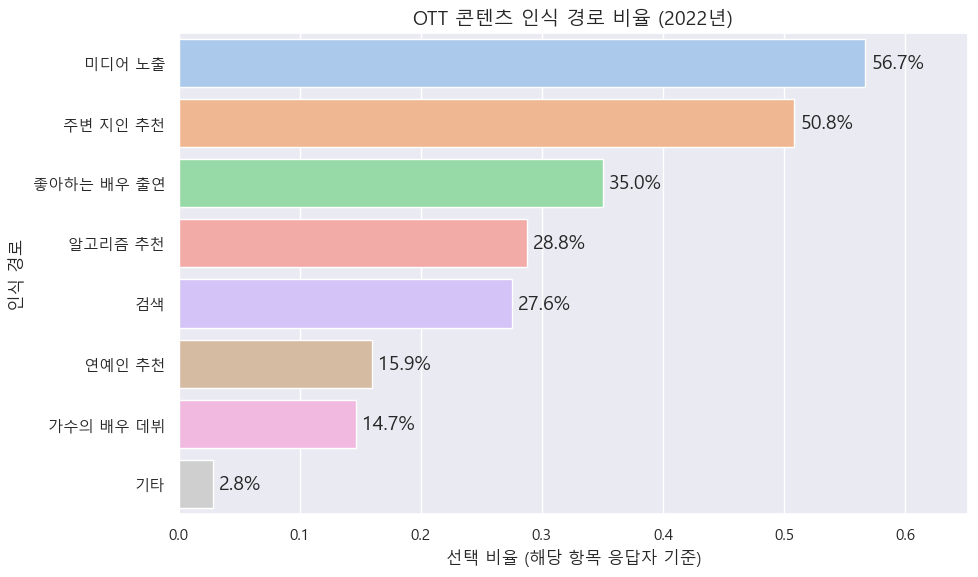

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------
# 1. 컬럼명-한글 매핑
col_to_kor_2022 = {
    "recog_route_recom_2022": "주변 지인 추천",
    "recog_route_media_2022": "미디어 노출",
    "recog_route_fav_actor_2022": "좋아하는 배우 출연",
    "recog_route_fav_singer_2022": "가수의 배우 데뷔",
    "recog_route_celeb_recom_2022": "연예인 추천",
    "recog_route_algorithm_2022": "알고리즘 추천",
    "recog_route_search_2022": "검색",
    "recog_route_etc_2022": "기타"
}

route_cols_2022 = list(col_to_kor_2022.keys())

# ---------------------
# 2. melt 후 비율 계산 (응답자 수 대비 선택 비율)
df_2022_route = df_2022[route_cols_2022].copy()
df_melt_2022 = df_2022_route.melt(var_name="코드", value_name="응답")
df_melt_2022 = df_melt_2022[df_melt_2022["응답"].isin([0, 1])]
df_melt_2022["인식 경로"] = df_melt_2022["코드"].map(col_to_kor_2022)

# 각 항목별: 1의 개수 / 유효 응답 수
route_pct_2022 = (
    df_melt_2022.groupby("인식 경로")["응답"]
    .agg(lambda x: (x == 1).sum() / len(x))
    .sort_values(ascending=False)
    .reset_index(name="비율")
)

# ---------------------
# 3. 시각화
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=route_pct_2022, y="인식 경로", x="비율", palette="pastel")

# 수치 텍스트 표시 (% 형식)
for i, (value, label) in enumerate(zip(route_pct_2022["비율"], route_pct_2022["인식 경로"])):
    ax.text(value + 0.005, i, f"{value:.1%}", va='center')

plt.title("OTT 콘텐츠 인식 경로 비율 (2022년)", fontsize=14)
plt.xlabel("선택 비율 (해당 항목 응답자 기준)")
plt.ylabel("인식 경로")
plt.xlim(0, route_pct_2022["비율"].max() * 1.15)
plt.tight_layout()
plt.show()


C:\Users\User\AppData\Local\Temp\ipykernel_9840\1577041102.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=route_pct_2022_sel, y="인식 경로", x="비율", palette="pastel")


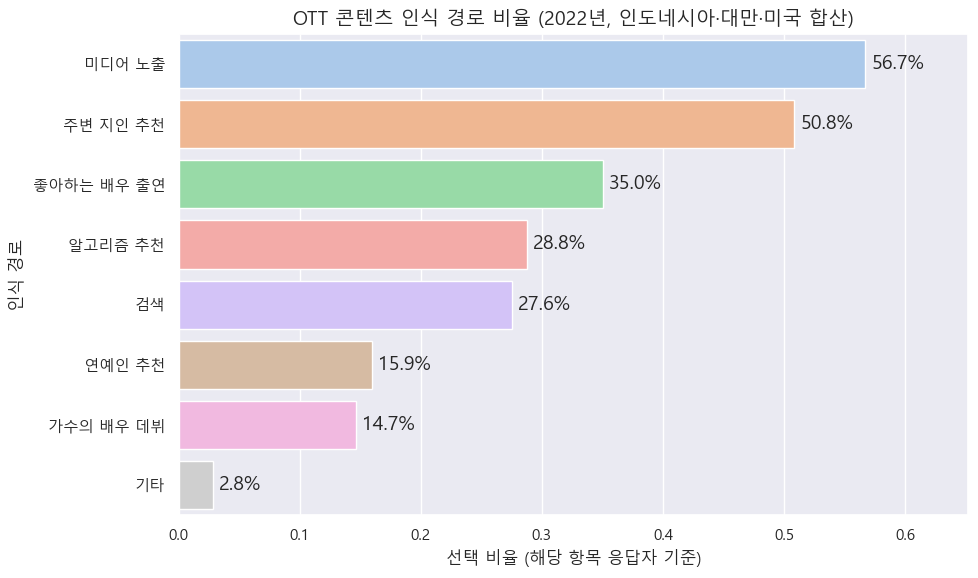

=== 2022년 인도네시아·대만·미국 합산 인식 경로 비율 ===
        인식 경로  비율(%)
0      미디어 노출   56.7
1    주변 지인 추천   50.8
2  좋아하는 배우 출연   35.0
3     알고리즘 추천   28.8
4          검색   27.6
5      연예인 추천   15.9
6   가수의 배우 데뷔   14.7
7          기타    2.8


In [120]:
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------
# 1. 컬럼명-한글 매핑
col_to_kor_2022 = {
    "recog_route_recom_2022": "주변 지인 추천",
    "recog_route_media_2022": "미디어 노출",
    "recog_route_fav_actor_2022": "좋아하는 배우 출연",
    "recog_route_fav_singer_2022": "가수의 배우 데뷔",
    "recog_route_celeb_recom_2022": "연예인 추천",
    "recog_route_algorithm_2022": "알고리즘 추천",
    "recog_route_search_2022": "검색",
    "recog_route_etc_2022": "기타"
}

route_cols_2022 = list(col_to_kor_2022.keys())

# ---------------------
# 2. 세 나라만 필터링
sel_nations = ["인도네시아", "대만", "미국"]
df_2022_sel = df_2022[df_2022["nation"].isin(sel_nations)].copy()

# ---------------------
# 3. melt 후 비율 계산 (응답자 수 대비 선택 비율)
df_melt_2022 = df_2022_sel[["nation"] + route_cols_2022].melt(
    id_vars=["nation"], var_name="코드", value_name="응답"
)
df_melt_2022 = df_melt_2022[df_melt_2022["응답"].isin([0, 1])]
df_melt_2022["인식 경로"] = df_melt_2022["코드"].map(col_to_kor_2022)

# 각 항목별: (1의 개수) / (해당 항목 응답자 수)
route_pct_2022_sel = (
    df_melt_2022.groupby("인식 경로")["응답"]
    .agg(lambda x: (x == 1).sum() / len(x))
    .sort_values(ascending=False)
    .reset_index(name="비율")
)

# ---------------------
# 4. 시각화
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=route_pct_2022_sel, y="인식 경로", x="비율", palette="pastel")

# 수치 텍스트 표시 (% 형식)
for i, (value, label) in enumerate(zip(route_pct_2022_sel["비율"], route_pct_2022_sel["인식 경로"])):
    ax.text(value + 0.005, i, f"{value:.1%}", va='center')

plt.title("OTT 콘텐츠 인식 경로 비율 (2022년, 인도네시아·대만·미국 합산)", fontsize=14)
plt.xlabel("선택 비율 (해당 항목 응답자 기준)")
plt.ylabel("인식 경로")
plt.xlim(0, route_pct_2022_sel["비율"].max() * 1.15)
plt.tight_layout()
plt.show()

# ---------------------
# 5. 표로 확인
print("=== 2022년 인도네시아·대만·미국 합산 인식 경로 비율 ===")
print(route_pct_2022_sel.assign(비율=lambda d: (d["비율"]*100).round(1)).rename(columns={"비율":"비율(%)"}))


C:\Users\User\AppData\Local\Temp\ipykernel_9840\2636814887.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=route_pct_2023, y="인식 경로", x="비율", palette="pastel")


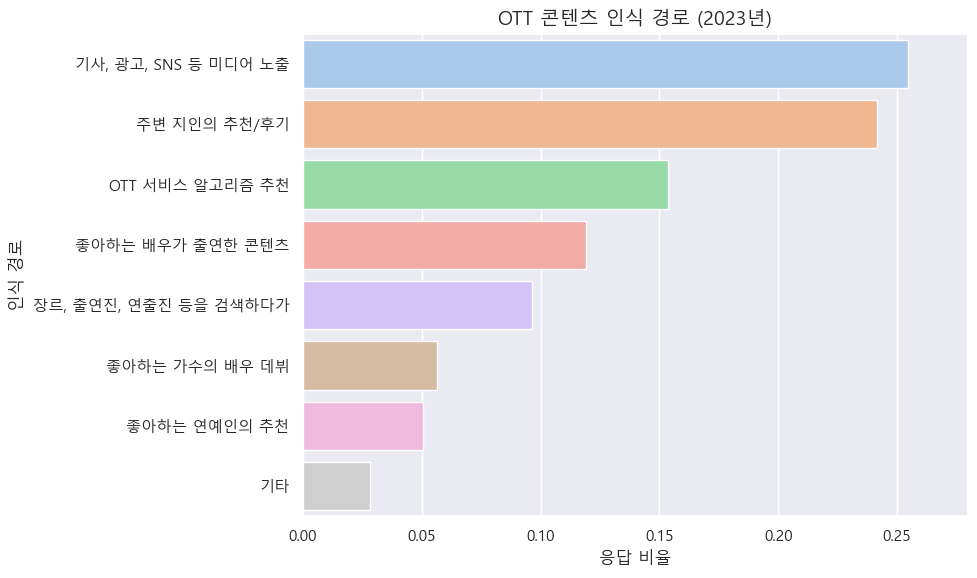

In [97]:
# 2023 비율 계산
route_pct_2023 = (
    df_melt_2023["인식 경로"]
    .value_counts(normalize=True)
    .sort_values(ascending=False)
    .rename_axis("인식 경로")
    .reset_index(name="비율")
)

# 시각화
plt.figure(figsize=(10, 6))
sns.barplot(data=route_pct_2023, y="인식 경로", x="비율", palette="pastel")
plt.title("OTT 콘텐츠 인식 경로 (2023년)", fontsize=14)
plt.xlabel("응답 비율")
plt.ylabel("인식 경로")
plt.xlim(0, route_pct_2023["비율"].max() * 1.1)
plt.tight_layout()
plt.show()

In [98]:
# 1. 2022년도: wide → long 형 변환
route_cols_2022 = [col for col in df_2022.columns if col.startswith("recog_route_") and col.endswith("_2022")]
route_mapping = {
    "recog_route_recom_2022": "주변 지인의 추천/후기",
    "recog_route_media_2022": "기사, 광고, SNS 등 미디어 노출",
    "recog_route_fav_actor_2022": "좋아하는 배우가 출연한 콘텐츠",
    "recog_route_fav_singer_2022": "좋아하는 가수의 배우 데뷔",
    "recog_route_celeb_recom_2022": "좋아하는 연예인의 추천",
    "recog_route_algorithm_2022": "OTT 서비스 알고리즘 추천",
    "recog_route_search_2022": "장르, 출연진, 연출진 등을 검색하다가",
    "recog_route_etc_2022": "기타"
}

df_melt_2022 = df_2022[["user_id", "gender", "age", "nation"] + route_cols_2022].melt(
    id_vars=["user_id", "gender", "age", "nation"],
    value_vars=route_cols_2022,
    var_name="route_code",
    value_name="선택"
)
df_melt_2022 = df_melt_2022[df_melt_2022["선택"] == 1].copy()
df_melt_2022["인식 경로"] = df_melt_2022["route_code"].map(route_mapping)

# 2. 2023년도: 멀티응답형 문자열 → 행으로 분리
df_melt_2023 = df_2023[["user_id", "gender", "age", "nation", "recog_route_2023"]].dropna(subset=["recog_route_2023"]).copy()
df_melt_2023 = df_melt_2023.assign(
    인식_리스트=df_melt_2023["recog_route_2023"].str.split("\n")
).explode("인식_리스트")
df_melt_2023["인식 경로"] = df_melt_2023["인식_리스트"].str.strip()

In [99]:
def plot_facet_distribution(df, facet_col, year):
    # 1. 비율 계산
    temp = (
        df.groupby([facet_col, "인식 경로"])
        .size()
        .reset_index(name="count")
    )
    temp["비율"] = temp.groupby(facet_col)["count"].transform(lambda x: x / x.sum())

    # 2. 순서 고정
    route_order = df["인식 경로"].value_counts().index.tolist()
    temp["인식 경로"] = pd.Categorical(temp["인식 경로"], categories=route_order, ordered=True)

    # 3. 시각화
    g = sns.catplot(
        data=temp,
        x="비율",
        y="인식 경로",
        col=facet_col,
        kind="bar",
        col_wrap=4,
        sharex=False,
        height=5,
        aspect=1.2,
        palette="pastel"
    )
    g.set_titles("{col_name}")
    g.set_axis_labels("비율", "인식 경로")

    # 4. 그래프 개수 기반 가운데 정렬 위치 보정
    n_axes = len(g.axes.flatten())
    if n_axes == 1:
        title_x = 0.5
    elif n_axes == 2:
        title_x = 0.425
    elif n_axes == 3:
        title_x = 0.45
    else:
        title_x = 0.5  # 기본값

    # 5. 여백 조정 및 제목 추가
    g.fig.tight_layout()
    g.fig.subplots_adjust(top=0.88)
    g.fig.text(title_x, 0.95, f"{year}년 {facet_col}별 OTT 콘텐츠 인식 경로 비율", 
               fontsize=16, ha="center", va="center")

    plt.show()


C:\Users\User\AppData\Local\Temp\ipykernel_9840\422609066.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


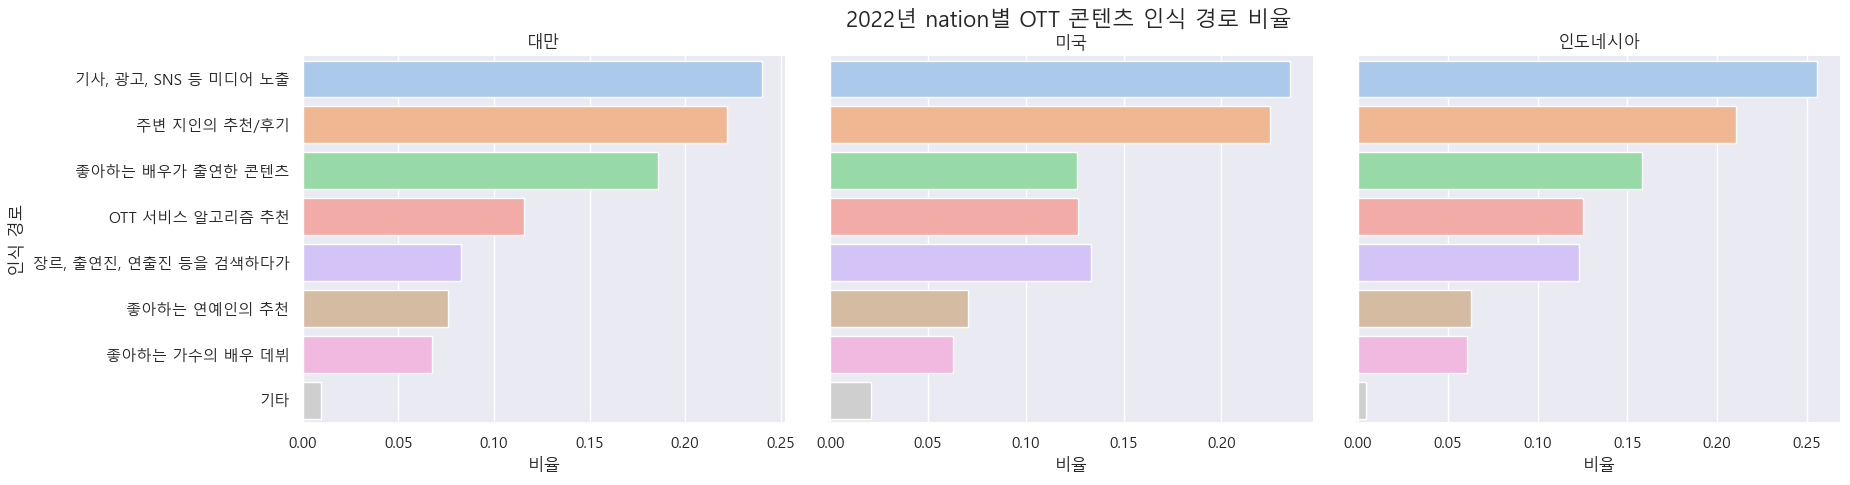

In [100]:
plot_facet_distribution(df_melt_2022, "nation", 2022)

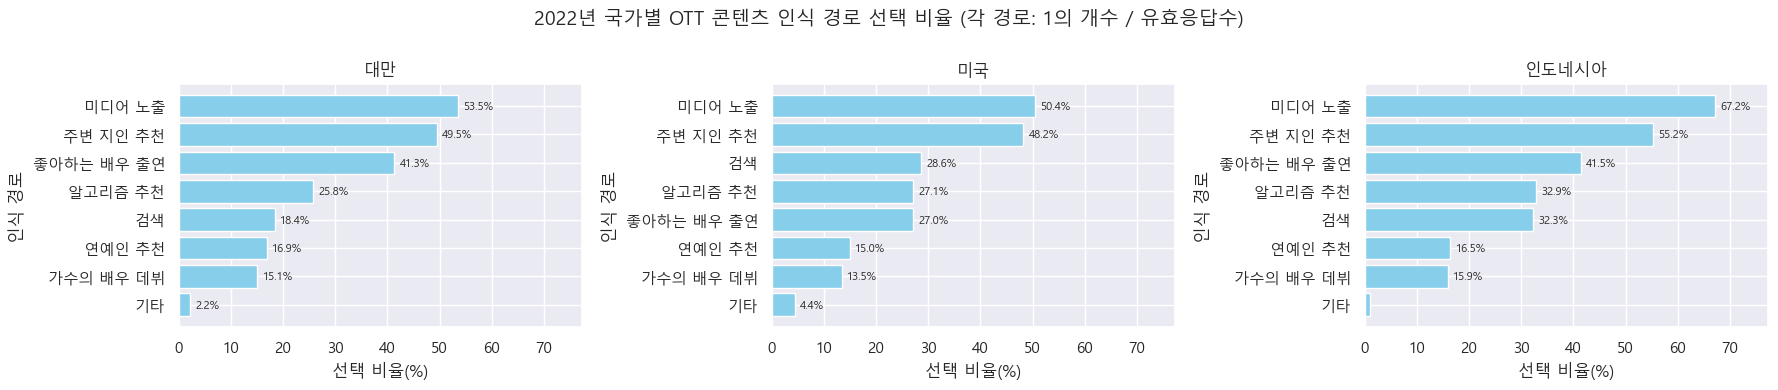

=== 2022년 국가별 인식 경로 선택 비율(%, 각 항목별 1의 개수 / 유효응답수) ===
인식 경로   주변 지인 추천  미디어 노출  좋아하는 배우 출연  가수의 배우 데뷔  연예인 추천  알고리즘 추천    검색   기타
nation                                                                     
대만          49.5    53.5        41.3       15.1    16.9     25.8  18.4  2.2
미국          48.2    50.4        27.0       13.5    15.0     27.1  28.6  4.4
인도네시아       55.2    67.2        41.5       15.9    16.5     32.9  32.3  1.1


In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

# ---------------------
# 1) 컬럼명-한글 매핑
col_to_kor_2022 = {
    "recog_route_recom_2022": "주변 지인 추천",
    "recog_route_media_2022": "미디어 노출",
    "recog_route_fav_actor_2022": "좋아하는 배우 출연",
    "recog_route_fav_singer_2022": "가수의 배우 데뷔",
    "recog_route_celeb_recom_2022": "연예인 추천",
    "recog_route_algorithm_2022": "알고리즘 추천",
    "recog_route_search_2022": "검색",
    "recog_route_etc_2022": "기타"
}
route_cols_2022 = list(col_to_kor_2022.keys())

# ---------------------
# 2) melt (국가 포함) + 비율 계산(각 항목별 1의 개수 / 유효응답수)
use_cols = ['nation'] + route_cols_2022
df_route = df_2022[use_cols].copy()

df_melt = df_route.melt(
    id_vars=['nation'],
    value_vars=route_cols_2022,
    var_name='코드',
    value_name='응답'
)

# 0/1만 유효로 사용 (NaN 제외)
df_melt = df_melt[df_melt['응답'].isin([0, 1])].copy()
df_melt['인식 경로'] = df_melt['코드'].map(col_to_kor_2022)

# 국가-경로별 비율 계산
route_pct_by_nation = (
    df_melt.groupby(['nation', '인식 경로'])['응답']
    .agg(lambda x: (x == 1).sum() / len(x))
    .reset_index(name='비율')
)

# 피벗(국가 x 경로) – 없으면 0으로 채움
pct_pivot = route_pct_by_nation.pivot(index='nation', columns='인식 경로', values='비율')
pct_pivot = pct_pivot.reindex(columns=list(col_to_kor_2022.values()))  # 보기 좋게 열 순서 고정
pct_pivot = pct_pivot.fillna(0)

# ---------------------
# 3) 국가별 그래프 (가로바) – 각 국가 내 경로 비율 (0~100%)
nations = pct_pivot.index.tolist()
n_cols = 3
n_rows = math.ceil(len(nations) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*6, n_rows*4), squeeze=False)

# x축 공통 최대값(퍼센트) – 국가별 비교 위해 전체 최대 기준
xmax = (pct_pivot.max().max() * 100) * 1.15
xmax = max(xmax, 30)  # 너무 작아보이지 않게 최소 폭

for i, nation in enumerate(nations):
    r = i // n_cols
    c = i % n_cols
    ax = axes[r, c]

    vals = (pct_pivot.loc[nation] * 100).sort_values(ascending=True)  # 낮은 비율부터 위로
    ax.barh(vals.index, vals.values, color='skyblue')

    # 라벨(퍼센트) 표시
    for y, v in enumerate(vals.values):
        if v >= 2:  # 2% 이상만 라벨 표기 (혼잡 방지; 필요시 조정)
            ax.text(v + 1, y, f"{v:.1f}%", va='center', fontsize=8)

    ax.set_xlim(0, xmax)
    ax.set_title(nation, fontsize=12)
    ax.set_xlabel("선택 비율(%)")
    ax.set_ylabel("인식 경로")

# 남는 축 지우기
for j in range(i+1, n_rows*n_cols):
    fig.delaxes(axes[j//n_cols, j % n_cols])

fig.suptitle("2022년 국가별 OTT 콘텐츠 인식 경로 선택 비율 (각 경로: 1의 개수 / 유효응답수)", fontsize=14)
plt.tight_layout()
plt.show()

# ---------------------
# 4) 표도 같이 출력 (보고서용)
print("=== 2022년 국가별 인식 경로 선택 비율(%, 각 항목별 1의 개수 / 유효응답수) ===")
print((pct_pivot * 100).round(1))


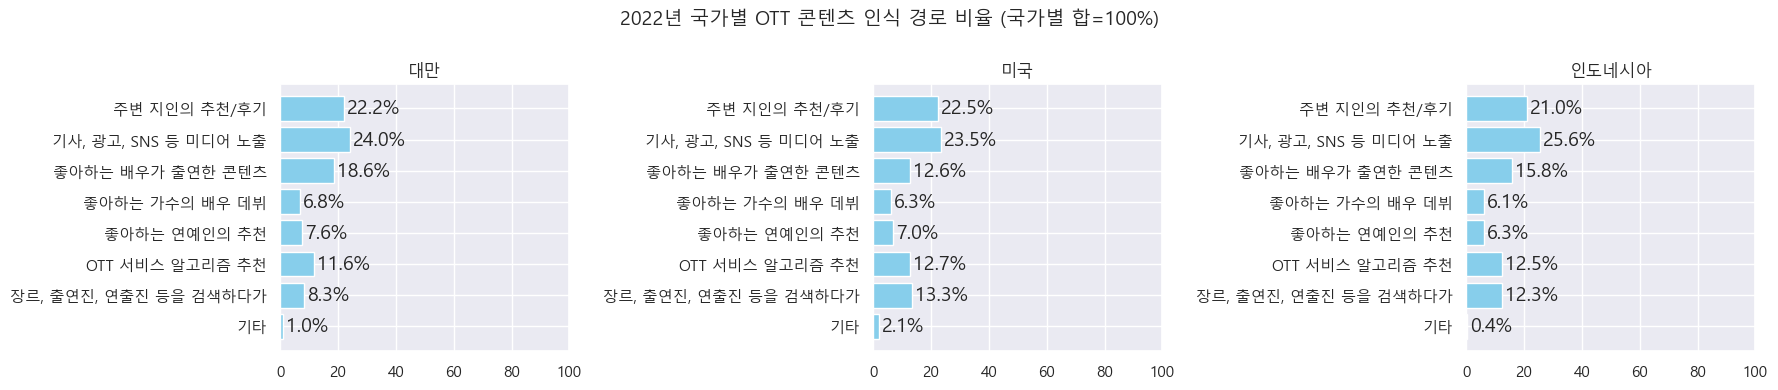

=== 2022년 국가별 인식 경로 비율 (국가별 합=100%) ===
인식 경로   주변 지인의 추천/후기  기사, 광고, SNS 등 미디어 노출  좋아하는 배우가 출연한 콘텐츠  좋아하는 가수의 배우 데뷔  \
nation                                                                         
대만              22.2                  24.0              18.6             6.8   
미국              22.5                  23.5              12.6             6.3   
인도네시아           21.0                  25.6              15.8             6.1   

인식 경로   좋아하는 연예인의 추천  OTT 서비스 알고리즘 추천  장르, 출연진, 연출진 등을 검색하다가   기타  
nation                                                             
대만               7.6             11.6                    8.3  1.0  
미국               7.0             12.7                   13.3  2.1  
인도네시아            6.3             12.5                   12.3  0.4  


In [102]:
import matplotlib.pyplot as plt

# --------------------------
# 1) 데이터 준비 (2022)
# --------------------------
df_plot = df_melt_2022[['nation', '인식 경로']].dropna()

# 경로 순서 고정
route_order = [
    "주변 지인의 추천/후기",
    "기사, 광고, SNS 등 미디어 노출",
    "좋아하는 배우가 출연한 콘텐츠",
    "좋아하는 가수의 배우 데뷔",
    "좋아하는 연예인의 추천",
    "OTT 서비스 알고리즘 추천",
    "장르, 출연진, 연출진 등을 검색하다가",
    "기타"
]

# --------------------------
# 2) 국가별 비율 계산 (행=국가, 열=인식 경로)
# --------------------------
ct = pd.crosstab(df_plot['nation'], df_plot['인식 경로'])
ct = ct.reindex(columns=[r for r in route_order if r in ct.columns])
prop_row = ct.div(ct.sum(axis=1), axis=0) * 100  # 국가별 비율(%)

# --------------------------
# 3) 국가별 개별 그래프
# --------------------------
nations = prop_row.index.tolist()
n_cols = 3
n_rows = (len(nations) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*6, n_rows*4))
axes = axes.flatten()

for i, nation in enumerate(nations):
    ax = axes[i]
    vals = prop_row.loc[nation]
    ax.barh(vals.index, vals.values, color='skyblue')
    
    # 값 라벨 표시
    for idx, v in enumerate(vals.values):
        ax.text(v + 1, idx, f"{v:.1f}%", va='center')
    
    ax.set_xlim(0, 100)
    ax.set_title(f"{nation}", fontsize=12)
    ax.invert_yaxis()  # 위에서부터 표시
    
# 나머지 빈 서브플롯 제거
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("2022년 국가별 OTT 콘텐츠 인식 경로 비율 (국가별 합=100%)", fontsize=14)
plt.tight_layout()
plt.show()

# --------------------------
# 4) 표 출력
# --------------------------
print("=== 2022년 국가별 인식 경로 비율 (국가별 합=100%) ===")
print(prop_row.round(1))


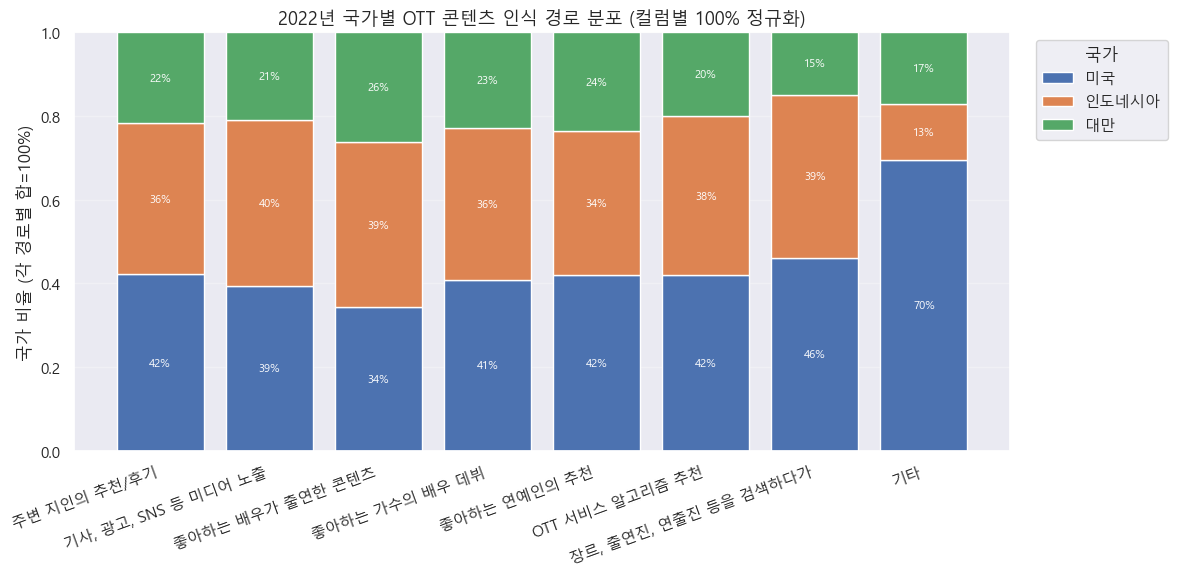

=== 2022년 국가별 인식 경로 분포 (컬럼별 100% 정규화, %) ===
인식 경로   주변 지인의 추천/후기  기사, 광고, SNS 등 미디어 노출  좋아하는 배우가 출연한 콘텐츠  좋아하는 가수의 배우 데뷔  \
nation                                                                         
미국              42.2                  39.5              34.3            40.9   
인도네시아           36.2                  39.5              39.5            36.2   
대만              21.6                  21.0              26.2            22.9   

인식 경로   좋아하는 연예인의 추천  OTT 서비스 알고리즘 추천  장르, 출연진, 연출진 등을 검색하다가    기타  
nation                                                              
미국              41.9             41.9                   46.1  69.5  
인도네시아           34.4             38.2                   39.0  13.3  
대만              23.7             19.9                   14.9  17.2  


In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# 0) 준비: 2022만 사용 & 필요 컬럼 정리
# ---------------------------------------
df_plot = df_melt_2022[['nation', '인식 경로']].dropna()

# 경로(열) 순서를 mapping 순서대로 맞추기
route_order = [
    "주변 지인의 추천/후기",
    "기사, 광고, SNS 등 미디어 노출",
    "좋아하는 배우가 출연한 콘텐츠",
    "좋아하는 가수의 배우 데뷔",
    "좋아하는 연예인의 추천",
    "OTT 서비스 알고리즘 추천",
    "장르, 출연진, 연출진 등을 검색하다가",
    "기타"
]

# ---------------------------------------
# 1) 교차표: nation x 인식 경로 (빈도)
# ---------------------------------------
ct = pd.crosstab(df_plot['nation'], df_plot['인식 경로'])

# route_order에 있는 컬럼만 사용하고 순서 정렬
ct = ct.reindex(columns=[r for r in route_order if r in ct.columns])

# 국가 순서는 전체 선택 수가 많은 순서로
nation_order = ct.sum(axis=1).sort_values(ascending=False).index.tolist()
ct = ct.reindex(index=nation_order)

# ---------------------------------------
# 2) 컬럼별 100% 정규화 (각 경로별 국가 비율의 합 = 100%)
# ---------------------------------------
col_sum = ct.sum(axis=0).replace(0, np.nan)   # 0-division 방지
prop_colnorm = (ct / col_sum).fillna(0)       # 비율(0~1)

# ---------------------------------------
# 3) 100% 스택 막대그래프 (X=인식 경로, 스택=국가)
# ---------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

bottom = np.zeros(len(prop_colnorm.columns))
x = np.arange(len(prop_colnorm.columns))

bars_by_nation = {}
for nation in prop_colnorm.index:
    vals = prop_colnorm.loc[nation].values
    bars = ax.bar(x, vals, bottom=bottom, label=nation)
    bars_by_nation[nation] = bars
    # 수치 라벨 (%). 너무 작으면 생략
    for bar, v, btm in zip(bars, vals, bottom):
        if v >= 0.05:  # 5% 이상일 때만 라벨 표시 (원하면 조정)
            ax.text(
                bar.get_x() + bar.get_width()/2,
                btm + v/2,
                f"{v*100:.0f}%",
                ha='center', va='center', fontsize=8, color='white'
            )
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(prop_colnorm.columns, rotation=20, ha='right')
ax.set_ylim(0, 1)
ax.set_ylabel("국가 비율 (각 경로별 합=100%)")
ax.set_title("2022년 국가별 OTT 콘텐츠 인식 경로 분포 (컬럼별 100% 정규화)", fontsize=13)
ax.legend(title="국가", bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# ---------------------------------------
# 4) 표로도 확인 (각 경로별 100% 정규화된 국가 비율%)
# ---------------------------------------
prop_pct = (prop_colnorm * 100).round(1)
print("=== 2022년 국가별 인식 경로 분포 (컬럼별 100% 정규화, %) ===")
print(prop_pct)

C:\Users\User\AppData\Local\Temp\ipykernel_9840\422609066.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


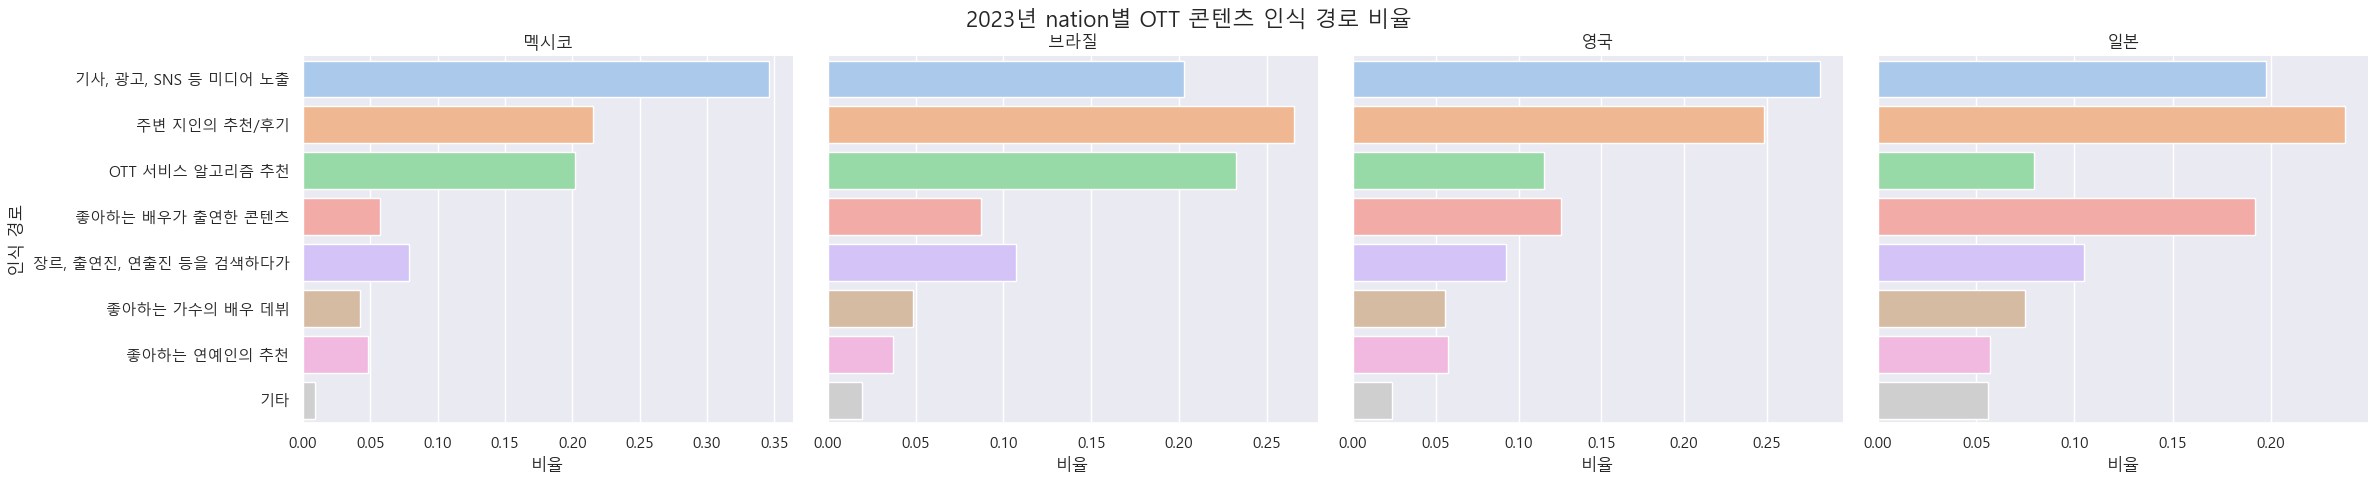

In [104]:
plot_facet_distribution(df_melt_2023, "nation", 2023)

C:\Users\User\AppData\Local\Temp\ipykernel_9840\422609066.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


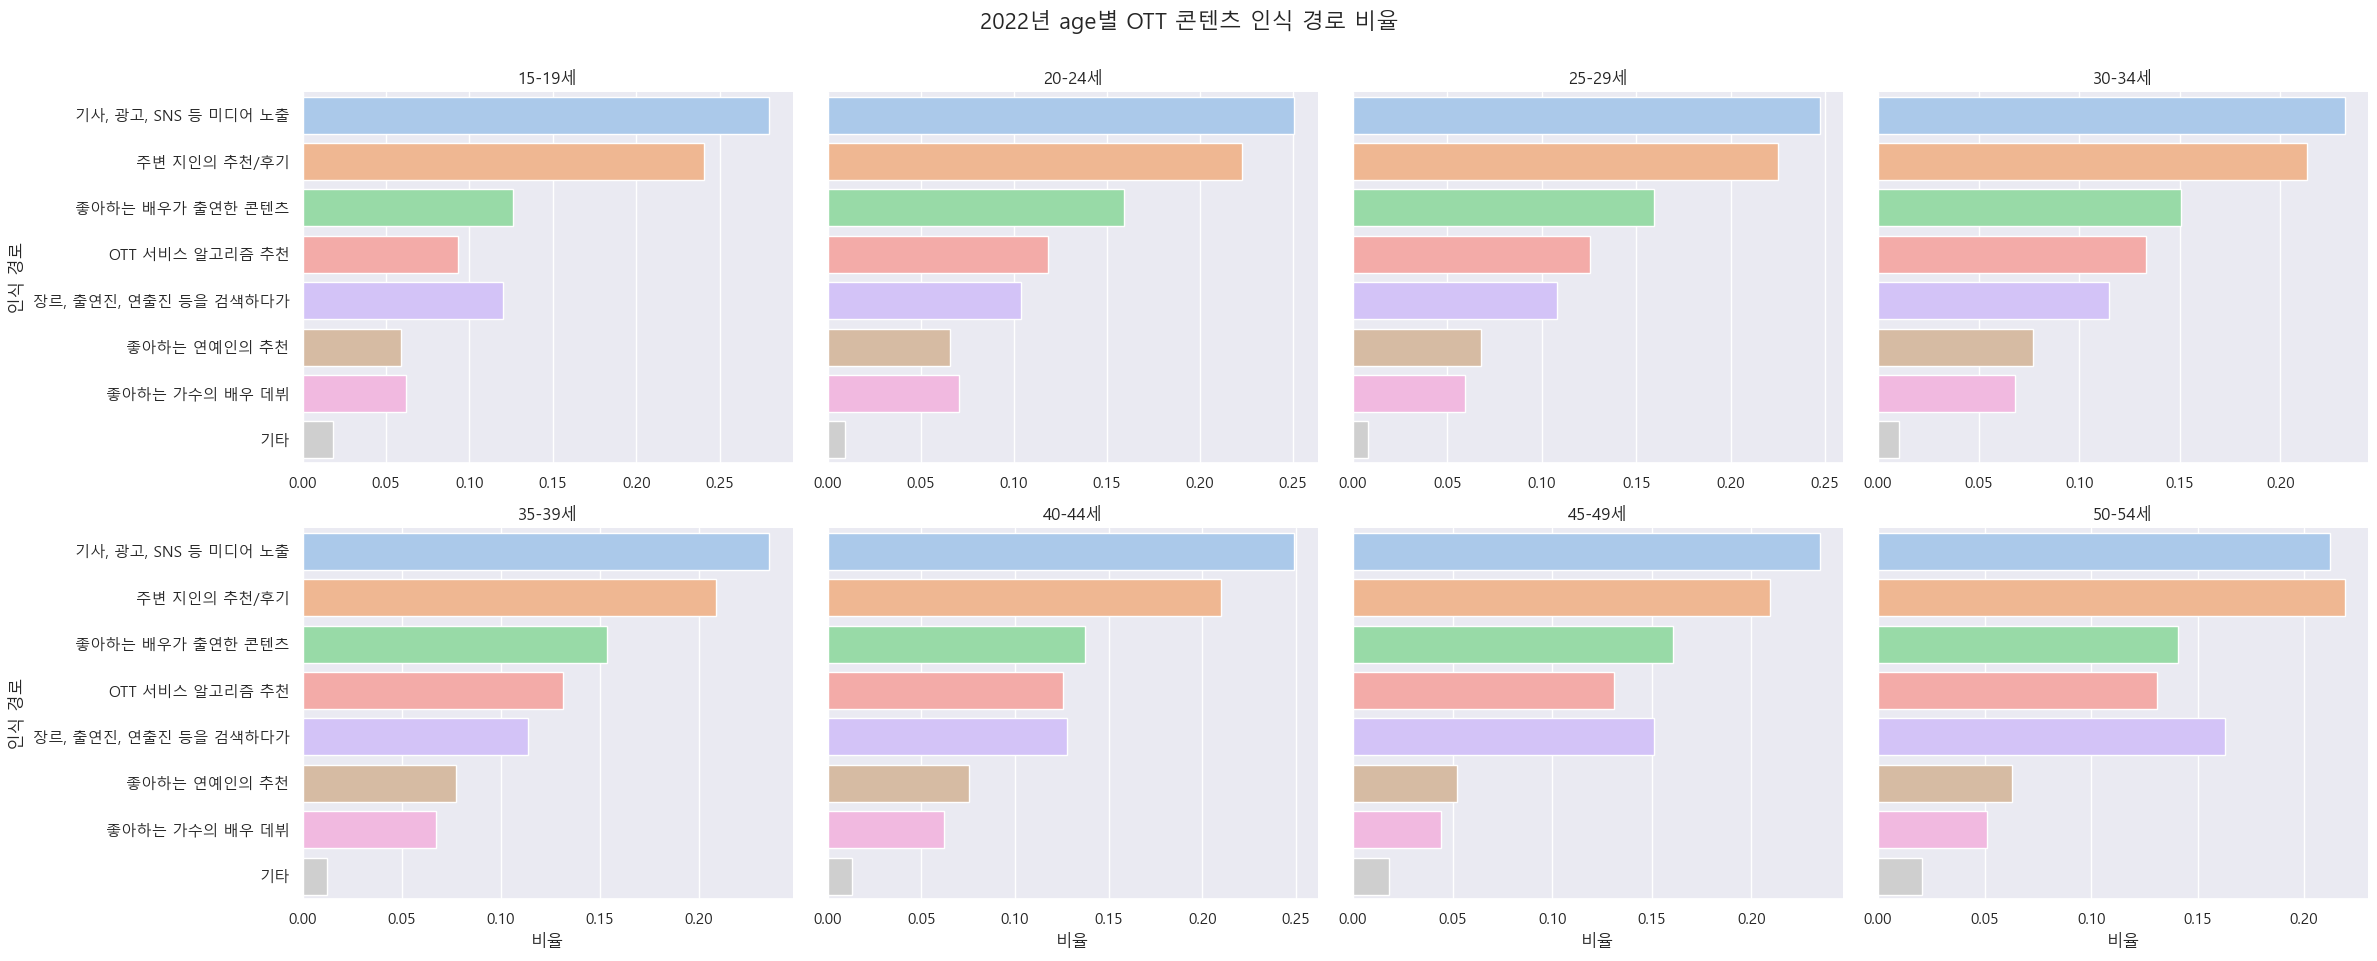

In [105]:
plot_facet_distribution(df_melt_2022, "age", 2022)

C:\Users\User\AppData\Local\Temp\ipykernel_9840\422609066.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


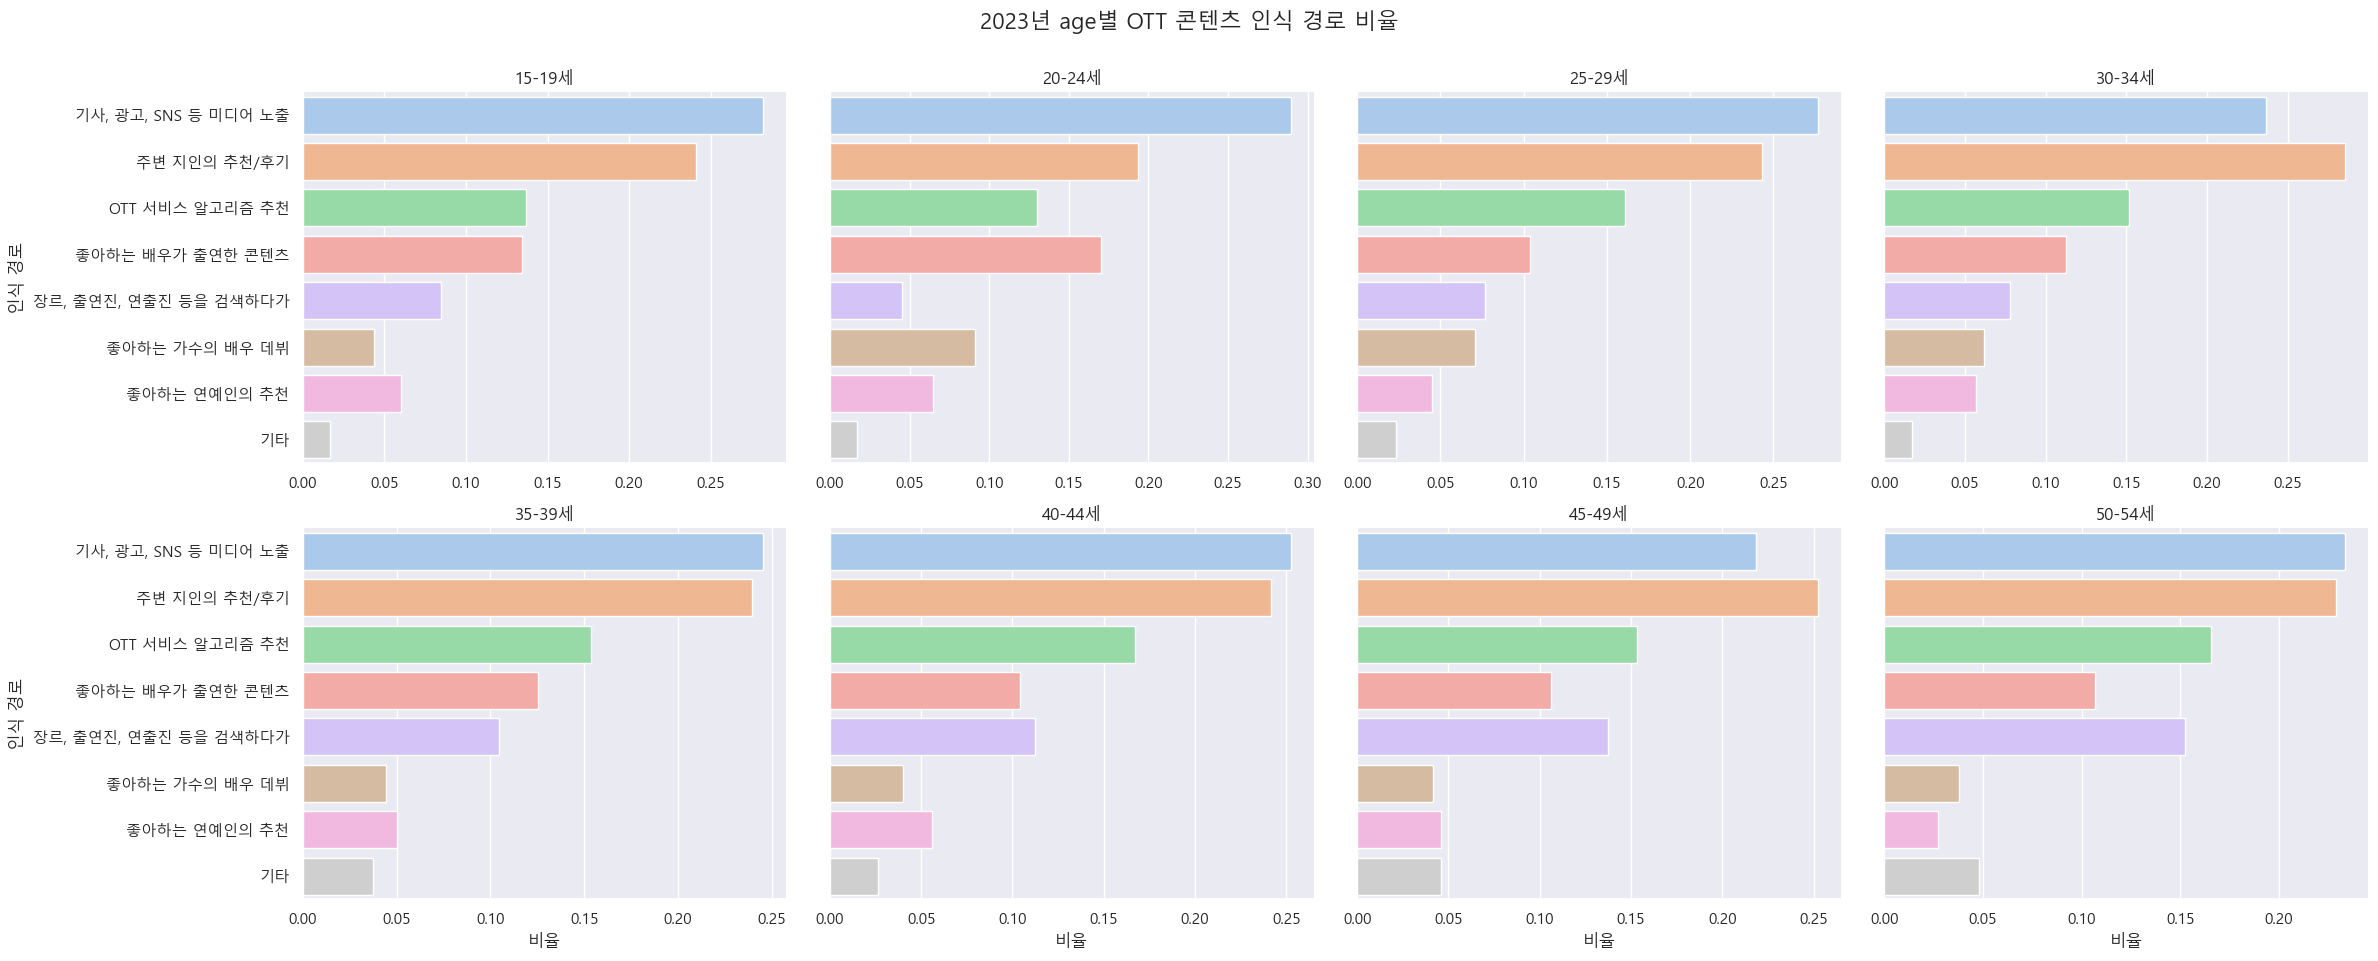

In [106]:
plot_facet_distribution(df_melt_2023, "age", 2023)

C:\Users\User\AppData\Local\Temp\ipykernel_9840\422609066.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


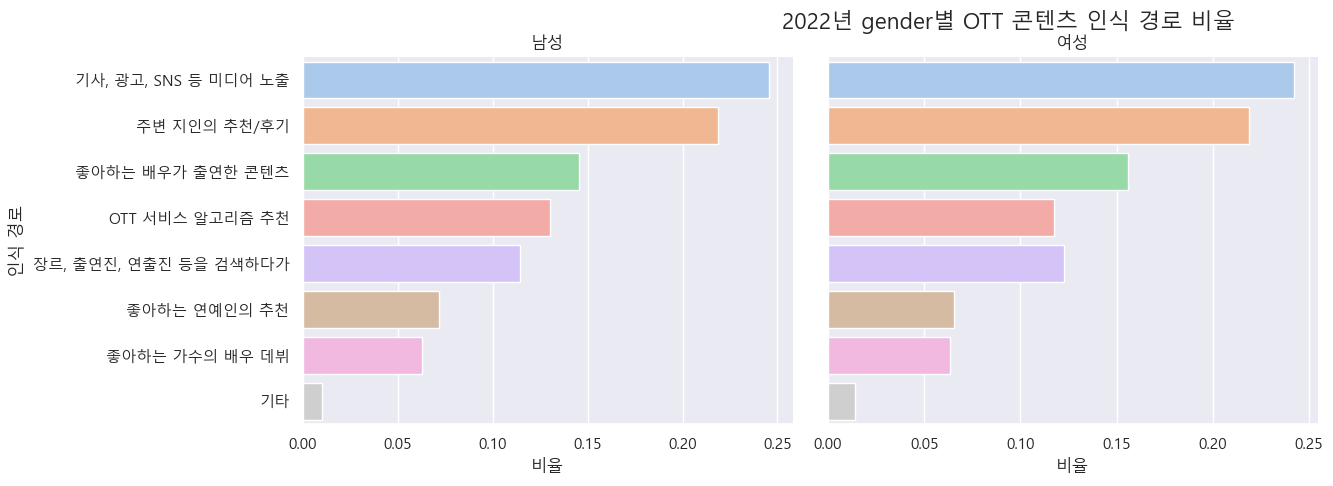

In [107]:
plot_facet_distribution(df_melt_2022, "gender", 2022)

C:\Users\User\AppData\Local\Temp\ipykernel_9840\422609066.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


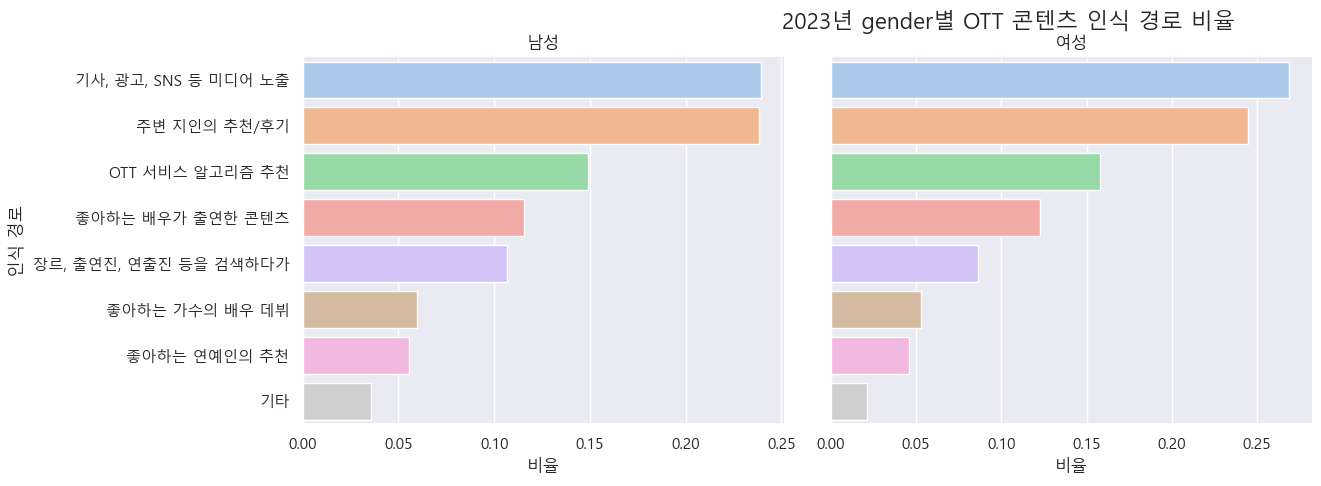

In [108]:
plot_facet_distribution(df_melt_2023, "gender", 2023)

In [109]:
# 시청 방식 컬럼 리스트
watch_cols = [
    "watch_recommendation", "watch_search", "watch_original",
    "watch_full_single", "watch_binge", "watch_unsubscribe"
]

# 컬럼명 → 한글 매핑
watch_labels = {
    "watch_recommendation": "OTT서비스에서 나에게 추천 해주는 프로그램을 시청",
    "watch_search": "OTT에서 제공하는 프로그램을 검색하여 시청",
    "watch_original": "OTT 자체 제작 프로그램(오리지널) 주로 시청",
    "watch_full_single": "영상 콘텐츠 한 편을 처음부터 끝까지 시청",
    "watch_binge": "영상 콘텐츠 여러 편을 몰아봄",
    "watch_unsubscribe": "관심있는 콘텐츠만 이용 후에 유료 구독을 해지"
}

C:\Users\User\AppData\Local\Temp\ipykernel_9840\3864889012.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=watch_total.values, y=watch_total.index, palette="pastel")


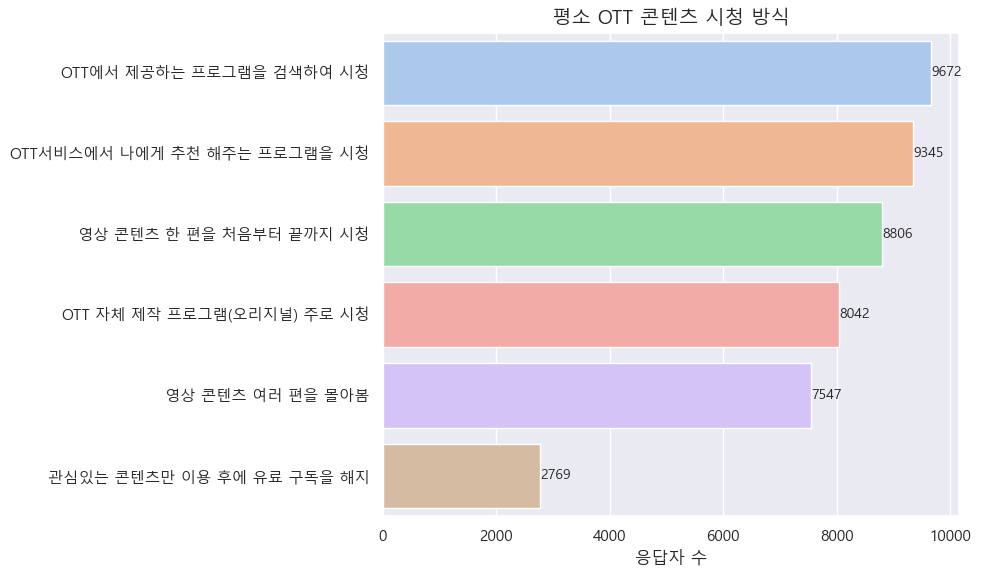

In [110]:
# 응답 수 계산 및 정렬
watch_total = df_common[watch_cols].sum().rename(index=watch_labels).sort_values(ascending=False)

# 시각화
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=watch_total.values, y=watch_total.index, palette="pastel")

# 수치 표시
for i, value in enumerate(watch_total.values):
    ax.text(value + 3, i, f"{int(value)}", va='center', fontsize=10)

plt.title("평소 OTT 콘텐츠 시청 방식", fontsize=14)
plt.xlabel("응답자 수")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [111]:
# 한글 시청 방식 매핑
watch_label_map = {
    "watch_recommendation": "OTT 추천 시청",
    "watch_search": "검색 시청",
    "watch_original": "오리지널 위주 시청",
    "watch_full_single": "한 편 끝까지 시청",
    "watch_binge": "여러 편 몰아보기",
    "watch_unsubscribe": "콘텐츠만 보고 구독 해지"
}

# 분석 대상 컬럼
watch_columns = list(watch_label_map.keys())


C:\Users\User\AppData\Local\Temp\ipykernel_9840\1135094164.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


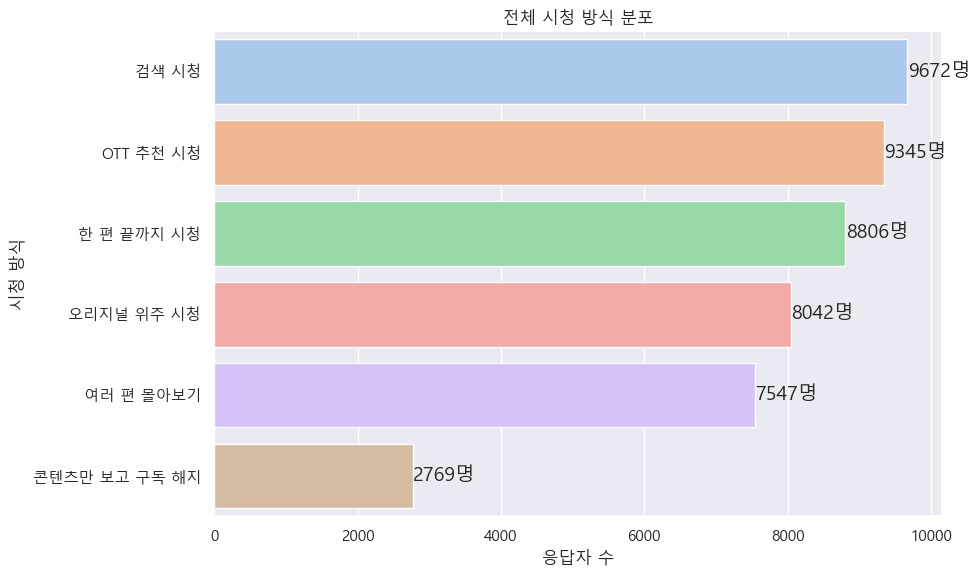

In [112]:
# 전체 시청 방식 분포 계산
df_watch = df_common[watch_columns].copy()
watch_counts = df_watch.sum().sort_values(ascending=False)

# 한글 라벨로 치환
watch_counts.index = watch_counts.index.map(watch_label_map)

# 시각화
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=watch_counts.values,
    y=watch_counts.index,
    palette="pastel"
)
for i, v in enumerate(watch_counts.values):
    ax.text(v + 5, i, f"{int(v)}명", va='center')
plt.title("전체 시청 방식 분포")
plt.xlabel("응답자 수")
plt.ylabel("시청 방식")
plt.tight_layout()
plt.show()

In [113]:
def plot_facet_watch_distribution_reach(df, facet_col, label_map, title_prefix):
    # df: 입력 데이터
    # facet_col: 국가, 성별 등 그룹화 기준
    # label_map: {컬럼명: 시청 방식 라벨} 사전
    # title_prefix: 그래프 제목 접두어

    # 1. 데이터 변형: melt로 시청 방식 추출
    df_melt = df[["user_id", facet_col] + list(label_map.keys())].melt(
        id_vars=["user_id", facet_col],
        var_name="방식",
        value_name="선택"
    )
    df_melt = df_melt[df_melt["선택"] == 1].copy()
    df_melt["시청 방식"] = df_melt["방식"].map(label_map)

    # 2. 시청 방식별 선택 인원 수 계산
    selected = (
        df_melt.groupby([facet_col, "시청 방식"])["user_id"]
        .nunique()
        .reset_index(name="선택 인원 수")
    )

    # 3. 국가별 전체 응답자 수 계산
    total = df.groupby(facet_col)["user_id"].nunique().reset_index(name="전체 인원 수")

    # 4. 병합 후 도달률 계산
    temp = pd.merge(selected, total, on=facet_col)
    temp["도달률"] = temp["선택 인원 수"] / temp["전체 인원 수"]

    # 5. 시청 방식 순서 고정
    temp["시청 방식"] = pd.Categorical(
        temp["시청 방식"], categories=list(label_map.values()), ordered=True
    )

    # 6. 시각화
    g = sns.catplot(
        data=temp,
        x="도달률",
        y="시청 방식",
        col=facet_col,
        kind="bar",
        col_wrap=4,
        sharex=False,
        height=5,
        aspect=1.2,
        palette="pastel"
    )
    g.set_titles("{col_name}")
    g.set_axis_labels("도달률", "시청 방식")
    g.fig.subplots_adjust(top=0.88)
    g.fig.suptitle(f"{title_prefix}별 시청 방식 도달률 (%)", fontsize=16)

    # 7. 수치 표시
    for ax in g.axes.flatten():
        for container in ax.containers:
            ax.bar_label(container, fmt="%.2f", label_type="edge", fontsize=9, padding=2)

    plt.tight_layout()
    plt.show()


In [114]:
plot_facet_watch_distribution(df_common, "gender", watch_label_map, "성별")
plot_facet_watch_distribution(df_common, "age", watch_label_map, "연령대")
plot_facet_watch_distribution(df_common, "nation", watch_label_map, "국가")

NameError: name 'plot_facet_watch_distribution' is not defined

In [ ]:
# 시청 방식 컬럼과 라벨 매핑
watch_cols = [
    "watch_recommendation", "watch_search", "watch_original",
    "watch_full_single", "watch_binge", "watch_unsubscribe", "ott_live"
]
label_map = {
    "watch_recommendation": "추천 시청",
    "watch_search": "검색 시청",
    "watch_original": "오리지널 콘텐츠",
    "watch_full_single": "단일 회차 완주",
    "watch_binge": "몰아보기",
    "watch_unsubscribe": "해지 후 재시청"
}

# 1. 국가별 응답자 수 계산
nation_total = df_common.groupby("nation")["user_id"].nunique().to_dict()

# 2. 데이터 melt
df_melt = df_common[["user_id", "nation"] + watch_cols].melt(
    id_vars=["user_id", "nation"],
    var_name="시청방식",
    value_name="선택"
)

# 3. 1로 응답한 경우만 필터링
df_selected = df_melt[df_melt["선택"] == 1].drop_duplicates(subset=["user_id", "nation", "시청방식"])

# 4. 시청 방식별 국가별 유니크 유저 수 집계
watch_counts = (
    df_selected.groupby(["nation", "시청방식"])["user_id"]
    .nunique()
    .reset_index(name="선택자수")
)

# 5. 응답자 수와 매핑하여 도달률 계산
watch_counts["도달률"] = watch_counts.apply(
    lambda row: row["선택자수"] / nation_total.get(row["nation"], 1),
    axis=1
)

# 6. 시청방식 이름 매핑 및 순서 지정
watch_counts["시청방식"] = watch_counts["시청방식"].map(label_map)
watch_counts["시청방식"] = pd.Categorical(
    watch_counts["시청방식"],
    categories=list(label_map.values()),
    ordered=True
)

# 7. 시각화
g = sns.catplot(
    data=watch_counts,
    x="도달률",
    y="시청방식",
    col="nation",
    kind="bar",
    col_wrap=4,
    sharex=False,
    height=5,
    aspect=1.2,
    palette="pastel"
)

g.set_titles("{col_name}")
g.set_axis_labels("비율", "시청 방식")
g.fig.subplots_adjust(top=0.88)
g.fig.suptitle("국가별 시청 방식 비율", fontsize=16)

# 수치 표시
for ax in g.axes.flatten():
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", label_type="edge", fontsize=9, padding=2)

plt.tight_layout()
plt.show()


In [ ]:
live_label_map = {
    1: "전혀 그렇지 않다",
    2: "그렇지 않다",
    3: "보통이다",
    4: "그렇다",
    5: "매우 그렇다"
}
order = list(live_label_map.values())

In [ ]:
# 전체 분포
df_live = df_common["ott_live"].map(live_label_map).value_counts().reindex(order)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=df_live.values, y=df_live.index, palette="pastel")
for i, v in enumerate(df_live.values):
    ax.text(v + 5, i, f"{int(v)}명", va='center')
plt.title("OTT 라이브 콘텐츠 이용 정도")
plt.xlabel("응답자 수")
plt.ylabel("이용 정도")
plt.tight_layout()
plt.show()

In [ ]:
def plot_ott_live_facet(df, facet_col):
    df_temp = df[[facet_col, "ott_live"]].dropna()
    df_temp["라이브 시청 정도"] = df_temp["ott_live"].map(live_label_map)

    temp = (
        df_temp.groupby([facet_col, "라이브 시청 정도"])
        .size()
        .reset_index(name="count")
    )
    temp["비율"] = temp.groupby(facet_col)["count"].transform(lambda x: x / x.sum())

    temp["라이브 시청 정도"] = pd.Categorical(temp["라이브 시청 정도"], categories=order, ordered=True)

    g = sns.catplot(
        data=temp,
        x="비율",
        y="라이브 시청 정도",
        col=facet_col,
        kind="bar",
        col_wrap=4,
        sharex=False,
        height=5,
        aspect=1.2,
        palette="pastel"
    )
    g.set_titles("{col_name}")
    g.set_axis_labels("비율", "라이브 시청 정도")
    g.fig.subplots_adjust(top=0.88)
    g.fig.suptitle(f"{facet_col}별 OTT 라이브 콘텐츠 이용 정도", fontsize=16)

    for ax in g.axes.flatten():
        for container in ax.containers:
            ax.bar_label(container, fmt="%.2f", label_type="edge", fontsize=9, padding=2)

    plt.tight_layout()
    plt.show()

In [ ]:
plot_ott_live_facet(df_common, "gender")
plot_ott_live_facet(df_common, "age")
plot_ott_live_facet(df_common, "nation")

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 라벨 매핑
live_label_map = {
    1: "전혀 그렇지 않다",
    2: "그렇지 않다",
    3: "보통이다",
    4: "그렇다",
    5: "매우 그렇다"
}
order = list(live_label_map.values())

# 데이터 준비
df_gender_live = df_common[["gender", "ott_live"]].dropna()
df_gender_live["라이브 시청 정도"] = df_gender_live["ott_live"].map(live_label_map)

# 그룹별 비율 계산
temp = (
    df_gender_live.groupby(["라이브 시청 정도", "gender"])
    .size()
    .reset_index(name="count")
)
temp["비율"] = temp.groupby("gender")["count"].transform(lambda x: x / x.sum())
temp["라이브 시청 정도"] = pd.Categorical(temp["라이브 시청 정도"], categories=order, ordered=True)

# 시각화
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=temp,
    x="라이브 시청 정도",
    y="비율",
    hue="gender",
    palette="pastel"
)

# 수치 표시
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", label_type="edge", fontsize=9, padding=3)

plt.title("성별 OTT 라이브 콘텐츠 이용 정도 비교", fontsize=14)
plt.xlabel("라이브 시청 정도")
plt.ylabel("비율")
plt.xticks(rotation=0)
plt.legend(title="성별")
plt.tight_layout()
plt.show()

In [ ]:

# 1. 분석 대상 컬럼 및 라벨 정의
watch_cols = {
    "watch_recommendation": "추천 기반 시청",
    "watch_search": "검색 기반 시청",
    "watch_original": "오리지널 콘텐츠 시청",
    "watch_full_single": "처음부터 끝까지 시청",
    "watch_binge": "여러 편 몰아보기",
    "watch_unsubscribe": "관심 콘텐츠 후 구독 해지"
}

# 2. 데이터 준비
df_watch = df_common[["gender"] + list(watch_cols.keys())].copy()

# 3. Melt (긴 형태로 변환)
df_melt = df_watch.melt(id_vars="gender", var_name="시청방식", value_name="선택")
df_melt = df_melt[df_melt["선택"] == 1]  # 선택한 항목만 필터링
df_melt["시청방식"] = df_melt["시청방식"].map(watch_cols)

# 4. 시청방식 순서
order = df_melt["시청방식"].value_counts().index.tolist()

# 5. 비율 계산
temp = (
    df_melt.groupby(["시청방식", "gender"])
    .size()
    .reset_index(name="count")
)
temp["비율"] = temp.groupby("gender")["count"].transform(lambda x: x / x.sum())
temp["시청방식"] = pd.Categorical(temp["시청방식"], categories=order, ordered=True)

# 6. 시각화
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=temp,
    x="시청방식",
    y="비율",
    hue="gender",
    palette="pastel"
)

# 수치 표시
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", label_type="edge", fontsize=9, padding=3)

plt.title("성별 OTT 콘텐츠 시청 방식 비교", fontsize=14)
plt.xlabel("시청 방식")
plt.ylabel("비율")
plt.xticks(rotation=45)
plt.legend(title="성별")
plt.tight_layout()
plt.show()


In [ ]:
# 인식 경로 라벨 매핑
route_cols_2022 = {
    "recog_route_recom_2022": "지인 추천",
    "recog_route_media_2022": "미디어 노출",
    "recog_route_fav_actor_2022": "좋아하는 배우 출연",
    "recog_route_fav_singer_2022": "가수의 배우 데뷔",
    "recog_route_celeb_recom_2022": "연예인 추천",
    "recog_route_algorithm_2022": "알고리즘 추천",
    "recog_route_search_2022": "검색 시 발견",
    "recog_route_etc_2022": "기타"
}

# 데이터 준비
df_route_2022 = df_2022[["gender"] + list(route_cols_2022.keys())].copy()

# Melt
df_melt_2022 = df_route_2022.melt(id_vars="gender", var_name="경로코드", value_name="선택")
df_melt_2022 = df_melt_2022[df_melt_2022["선택"] == 1]
df_melt_2022["인식 경로"] = df_melt_2022["경로코드"].map(route_cols_2022)

# 비율 계산
temp_2022 = (
    df_melt_2022.groupby(["인식 경로", "gender"])
    .size()
    .reset_index(name="count")
)
temp_2022["비율"] = temp_2022.groupby("gender")["count"].transform(lambda x: x / x.sum())

# 순서 고정
order_2022 = df_melt_2022["인식 경로"].value_counts().index.tolist()
temp_2022["인식 경로"] = pd.Categorical(temp_2022["인식 경로"], categories=order_2022, ordered=True)

# 시각화
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=temp_2022,
    x="인식 경로",
    y="비율",
    hue="gender",
    palette="pastel"
)

# 수치 라벨
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", label_type="edge", fontsize=9, padding=2)

plt.title("성별 OTT 콘텐츠 인식 경로 (2022)", fontsize=14)
plt.xlabel("인식 경로")
plt.ylabel("비율")
plt.xticks(rotation=45)
plt.legend(title="성별")
plt.tight_layout()
plt.show()


In [ ]:
# 인식 경로는 쉼표로 구분된 문자열 하나의 컬럼이므로 explode 필요
df_route_2023 = df_2023[["gender", "recog_route_2023"]].copy()
df_route_2023["인식 경로"] = df_route_2023["recog_route_2023"].str.split("\n").explode().str.strip()
df_route_2023 = df_route_2023[df_route_2023["인식 경로"].notna()]

# 비율 계산
temp_2023 = (
    df_route_2023.groupby(["인식 경로", "gender"])
    .size()
    .reset_index(name="count")
)
temp_2023["비율"] = temp_2023.groupby("gender")["count"].transform(lambda x: x / x.sum())

# 순서 고정
order_2023 = df_route_2023["인식 경로"].value_counts().index.tolist()
temp_2023["인식 경로"] = pd.Categorical(temp_2023["인식 경로"], categories=order_2023, ordered=True)

# 시각화
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=temp_2023,
    x="인식 경로",
    y="비율",
    hue="gender",
    palette="pastel"
)

# 수치 라벨
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", label_type="edge", fontsize=9, padding=2)

plt.title("성별 OTT 콘텐츠 인식 경로 (2023)", fontsize=14)
plt.xlabel("인식 경로")
plt.ylabel("비율")
plt.xticks(rotation=45)
plt.legend(title="성별")
plt.tight_layout()
plt.show()